# 电商订单数据集 · 探索性分析（EDA）

> 数据来源：`ecommerce_orders_cleaned.csv`（由 `clean_dataset.ipynb` 清洗产出）
> 数据规模：**28,953 行 × 61 列**，时间范围 **2023-01-01 ~ 2026-11-10**
> 分析口径：订单级（1 行 = 1 笔订单），金额单位统一为**元**，图表大额数字用**万元**展示

---

## 目录

| 章节 | 分析主题 | 回答的业务问题 |
| --- | --- | --- |
| 1 | 环境配置与绘图风格 | — |
| 2 | 数据载入与结构体检 | 数据长什么样、口径是否统一 |
| 3 | 核心经营指标总览 | 整体经营水平如何 |
| 4 | 月度销售趋势 | 生意在变好还是变差 |
| 5 | 年度 / 同期对比 | 同比真实增长多少 |
| 6 | 年 × 月销售热力图 | 季节性规律是什么 |
| 7 | 品类销售额帕累托 | 哪类商品销售额最高 |
| 8 | 品类矩阵（销售额 × 毛利率） | 哪类商品"又大又赚钱" |
| 9 | 子类 TOP / BOTTOM 排行 | 具体哪些子类值得投入 |
| 10 | 品牌表现 | 哪个品牌扛量、哪个品牌溢价 |
| 11 | 价格带分析 | 卖贵还是卖便宜更赚钱 |
| 12 | 大额订单画像 · 人群维度 | 大额订单人群有什么特征 |
| 13 | 大额订单画像 · 渠道行为维度 | 大额订单从哪些渠道来 |
| 14 | 订单金额分布与二八法则 | 大额订单贡献了多少销售额 |
| 15 | 大额订单驱动因素 | 到底什么决定了订单变大 |
| 16 | 折扣效果分析 | 打折有没有换来更多钱 |
| 17 | 客户 RFM 分层 | 客户结构健康吗 |
| 18 | 客户价值贡献帕累托 | 头部客户有多重要 |
| 19 | 订单状态漏斗与退货 | 履约环节漏在哪 |
| 20 | 物流时效对评分/退货的影响 | 配送慢是否真的伤害体验 |
| 21 | 地域市场表现 | 哪个市场值得加投 |
| 22 | 流量渠道与设备分析 | 流量结构是否失衡 |
| 23 | 数值字段相关性矩阵 | 指标之间如何联动 |
| 24 | 销售前景判断 | 哪些品类前景最好 |
| 25 | 综合结论与行动建议 | 下一步该做什么 |

---


## 1. 环境配置与绘图风格

**实现功能**：导入分析所需库，统一设置中文字体（避免图表中文变方块）、画布尺寸、数字格式，并封装 3 个通用小工具：

| 工具 | 作用 |
| --- | --- |
| `money_axis(ax)` | 把坐标轴数值转成「万元」，避免 1e6 这种难读刻度 |
| `add_bar_labels(ax)` | 柱状图自动打数值标签 |
| `pct_axis(ax)` | 坐标轴按百分比显示 |

统一风格后，后面 20 多张图不用重复写格式代码。


In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ---------------- 中文字体（缺字体时中文会变方块，必须先设） ----------------
CN_FONTS = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "Noto Sans CJK SC", "Source Han Sans SC", "WenQuanYi Zen Hei", "PingFang SC"]
mpl.rcParams["font.sans-serif"] = CN_FONTS
mpl.rcParams["axes.unicode_minus"] = False        # 负号正常显示

# ---------------- 全局绘图风格 ----------------
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams["font.sans-serif"] = CN_FONTS        # set_theme 会覆盖字体，再设一次
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.figsize"] = (11, 5)
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.titlesize"] = 13
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["axes.labelsize"] = 11

# ---------------- pandas 显示设置 ----------------
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CMAP = mpl.colormaps["viridis"]
MAIN, ACCENT, GREY = "#2E75B6", "#ED7D31", "#8C8C8C"


# ---------------- 通用小工具 ----------------
def money_axis(ax, axis="y"):
    """坐标轴数值 → 万元显示（数据本身仍是元）"""
    fmt = FuncFormatter(lambda v, _: f"{v / 1e4:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def pct_axis(ax, axis="y"):
    """坐标轴数值 → 百分比显示"""
    fmt = FuncFormatter(lambda v, _: f"{v:.0f}%")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def add_bar_labels(ax, fmt="{:.0f}", fontsize=9, rotation=0):
    """给柱状图的每根柱子加数值标签"""
    for p in ax.patches:
        h = p.get_height()
        if not np.isfinite(h):
            continue
        ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h),
                    ha="center", va="bottom", fontsize=fontsize, rotation=rotation,
                    xytext=(0, 3), textcoords="offset points")


print("✅ 环境就绪 → pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__)


✅ 环境就绪 → pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2


## 2. 数据载入与结构体检

**实现功能**：

1. 读取清洗后的 CSV，显式声明日期列与 ID 列类型（ID 必须按字符串读，否则前导零/超长数字会变形）。
2. 把有业务顺序的字段（年龄段、价格带、客户分层、会员等级、订单状态、星期）转成**有序 category**，这样画图时顺序不会被打乱，`groupby` 也会按业务顺序排列。
3. 记录两个关键口径变量，供后面所有图表复用：
   - `TODAY`：数据中的最大日期（**2026-11-10**），用于计算"距今多少天"。
   - `LAST_FULL_MONTH`：最后一个**完整**月份（2026-10）。因为 2026-11 只有 10 天数据，趋势图必须剔除，否则最后一个月会莫名"暴跌"。
4. 体检输出：规模、时间跨度、业务性缺失分布、内存占用。


In [2]:
from pathlib import Path

# Notebooks live in notebooks/; datasets live in <root>/data/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "ecommerce_orders_cleaned.csv"

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Order_Date"],
    dtype={"Customer_ID": "str", "Product_ID": "str"},   # ID 按字符串读，避免被当成数字
)

# ---------------- 有业务顺序的字段转有序 category ----------------
ordered_maps = {
    "Age_Group": ["<25", "25-34", "35-44", "45-54", "55+"],
    "Price_Level": ["低价", "中价", "高价"],
    "Customer_Segment": ["New", "Returning", "Loyal", "Premium"],
    "Membership_Status": ["Standard", "Silver", "Gold", "Platinum"],
    "Order_Status": ["Processing", "Shipped", "Delivered", "Returned", "Cancelled"],
    "Day_Of_Week": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    "Season": ["Spring", "Summer", "Autumn", "Winter"],
}
for col, order in ordered_maps.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

# ---------------- 全局口径变量 ----------------
TODAY = df["Order_Date"].max()                              # 数据截止日
LAST_FULL_MONTH = (TODAY.replace(day=1) - pd.Timedelta(days=1)).to_period("M")

print(f"数据规模：{df.shape[0]:,} 行 × {df.shape[1]} 列")
print(f"时间范围：{df['Order_Date'].min():%Y-%m-%d} ~ {TODAY:%Y-%m-%d}"
      f"（跨度 {(TODAY - df['Order_Date'].min()).days} 天）")
print(f"最后完整月：{LAST_FULL_MONTH}（2026-11 只有 10 天数据，趋势图剔除）")
print(f"下单客户数：{df['Customer_ID'].nunique():,} 人　|　商品 ID 数：{df['Product_ID'].nunique():,} 个")
print(f"内存占用：{df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n业务性缺失（清洗阶段有意保留）:")
na = df.isna().sum()
print(na[na > 0].to_string() if na.sum() else "无缺失")

print("\n关键分类字段基数:")
base = {c: df[c].nunique() for c in
        ["Product_Category", "Product_Subcategory", "Brand", "Country", "City",
         "Payment_Method", "Device_Type", "Traffic_Source", "Order_Status"]}
print(pd.Series(base, name="唯一值数").to_string())


数据规模：28,953 行 × 61 列
时间范围：2023-01-01 ~ 2026-11-10（跨度 1409 天）
最后完整月：2026-10（2026-11 只有 10 天数据，趋势图剔除）
下单客户数：8,641 人　|　商品 ID 数：2,500 个
内存占用：35.73 MB

业务性缺失（清洗阶段有意保留）:
Delivery_Days    1695
Review_Rating    1695

关键分类字段基数:
Product_Category        8
Product_Subcategory    32
Brand                  10
Country                10
City                   10
Payment_Method          6
Device_Type             3
Traffic_Source          6
Order_Status            5


## 3. 核心经营指标总览

**实现功能**：一次性算清全店的"体检指标"，并用一张横向条形图展示 **8 个关键比率**，快速判断生意的结构性特征。

| 指标 | 计算口径 | 为什么重要 |
| --- | --- | --- |
| 总销售额 / 总利润 | `Order_Amount` / `Profit_Amount` 求和 | 规模基线 |
| 客单价 | 销售额 ÷ 订单数 | 单笔赚钱能力 |
| 件单价 | 销售额 ÷ 总件数 | 剔除"多件凑单"影响后的真实价格水平 |
| 平均毛利率 | `Profit_Margin_Percent` 均值 | 赚钱效率 |
| 退货率 | `Returned_Flag` 均值 | 隐性成本 |
| 高价值订单占比 | `High_Value_Order_Flag` 均值 | 大额订单结构（本数据集约为 1/4） |
| 人均下单次数 | 订单数 ÷ 客户数 | 复购强度 |

比率图里我把 **折扣使用率、用券率、退货率、取消率、未完成率** 放在一起对比，能一眼看出"营销手段用得多不多"与"漏损大不大"。


,总销售额（万元）,总利润（万元）,订单数（单）,客单价（元/单）,件单价（元/件）,平均折扣率（%）,平均毛利率（%）,退货率（%）,平均评分,高价值订单占比（%）,下单客户数（人）,人均下单（单/人）
指标值,"1,098.46",214.37,"28,953.00",379.39,123.11,12.59,21.98,10.10,4.04,25.10,"8,641.00",3.35


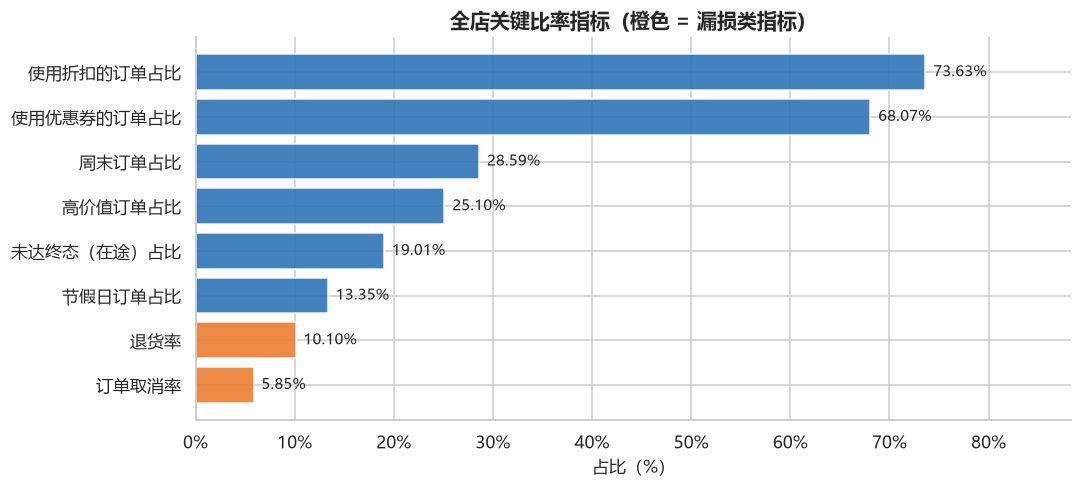

→ 生意体量：1,098 万元销售额，214 万元利润，整体净利率约 19.52%
→ 营销依赖：73.6% 的订单带折扣、68.1% 的订单用了券，折扣已成常态而非促销手段
→ 漏损结构：退货率 10.1% + 取消率 5.9%，合计约 16.0% 的订单没变成有效收入


In [3]:
n_order = len(df)
n_cust = df["Customer_ID"].nunique()

kpi = pd.Series({
    "总销售额（万元）": df["Order_Amount"].sum() / 1e4,
    "总利润（万元）": df["Profit_Amount"].sum() / 1e4,
    "订单数（单）": n_order,
    "客单价（元/单）": df["Order_Amount"].mean(),
    "件单价（元/件）": df["Order_Amount"].sum() / df["Quantity"].sum(),
    "平均折扣率（%）": df["Discount_Percent"].mean(),
    "平均毛利率（%）": df["Profit_Margin_Percent"].mean(),
    "退货率（%）": df["Returned_Flag"].mean() * 100,
    "平均评分": df["Review_Rating"].mean(),
    "高价值订单占比（%）": df["High_Value_Order_Flag"].mean() * 100,
    "下单客户数（人）": n_cust,
    "人均下单（单/人）": n_order / n_cust,
}, name="指标值")

display(kpi.to_frame().round(2).T)

# ---------------- 关键比率图 ----------------
rates = pd.Series({
    "高价值订单占比": df["High_Value_Order_Flag"].mean() * 100,
    "使用折扣的订单占比": (df["Discount_Percent"] > 0).mean() * 100,
    "使用优惠券的订单占比": (df["Coupon_Used"] == "Yes").mean() * 100,
    "节假日订单占比": (df["Holiday_Season"] == "Yes").mean() * 100,
    "周末订单占比": df["Is_Weekend"].mean() * 100,
    "退货率": df["Returned_Flag"].mean() * 100,
    "订单取消率": (df["Order_Status"] == "Cancelled").mean() * 100,
    "未达终态（在途）占比": (~df["Order_Status"].isin(["Delivered", "Returned", "Cancelled"])).mean() * 100,
}).sort_values()

fig, ax = plt.subplots(figsize=(10, 4.6))
colors = [ACCENT if k in ("退货率", "订单取消率") else MAIN for k in rates.index]
bars = ax.barh(rates.index, rates.values, color=colors, alpha=0.9)
for b, v in zip(bars, rates.values):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.2f}%", va="center", fontsize=9.5)
ax.set_xlim(0, rates.max() * 1.2)
ax.set_title("全店关键比率指标（橙色 = 漏损类指标）")
ax.set_xlabel("占比（%）")
pct_axis(ax, "x")
sns.despine()
plt.tight_layout()
plt.show()

print(f"→ 生意体量：{df['Order_Amount'].sum()/1e4:,.0f} 万元销售额，{df['Profit_Amount'].sum()/1e4:,.0f} 万元利润，"
      f"整体净利率约 {df['Profit_Amount'].sum()/df['Order_Amount'].sum()*100:.2f}%")
print(f"→ 营销依赖：{(df['Discount_Percent']>0).mean()*100:.1f}% 的订单带折扣、"
      f"{(df['Coupon_Used']=='Yes').mean()*100:.1f}% 的订单用了券，折扣已成常态而非促销手段")
print(f"→ 漏损结构：退货率 {df['Returned_Flag'].mean()*100:.1f}% + 取消率 {(df['Order_Status']=='Cancelled').mean()*100:.1f}%，"
      f"合计约 {(df['Returned_Flag'].mean()+(df['Order_Status']=='Cancelled').mean())*100:.1f}% 的订单没变成有效收入")


## 4. 月度销售趋势

**实现功能**：按自然月重采样，画 3 张联动图回答"生意在变好还是变差"。

- **上图**：月度销售额（柱）+ **3 个月移动平均**（线）。移动平均能过滤单月波动，看清真实趋势方向。
- **中图**：月度订单数，判断销售额变化是"单量变了"还是"客单价变了"。
- **下图**：月度客单价，验证上面这个判断。

技术要点：
- 用 `resample("ME")`（月末口径，pandas 2.2+ 已弃用 `"M"`）。
- **剔除最后一个不完整月**（2026-11 仅 10 天），否则折线末端会出现虚假断崖。
- 额外算一个"趋势斜率"，用最小二乘拟合判断整体是上升/下降，避免只靠眼睛看。


统计区间：2023-01 ~ 2026-10，共 46 个完整月
月均销售额：23.72 万元　|　单月最高：29.20 万元（2025-08）　|　最低：20.55 万元（2024-10）
趋势斜率：每月 -0.03 万元，相当于月均水平的 -0.11% → 整体下行/停滞


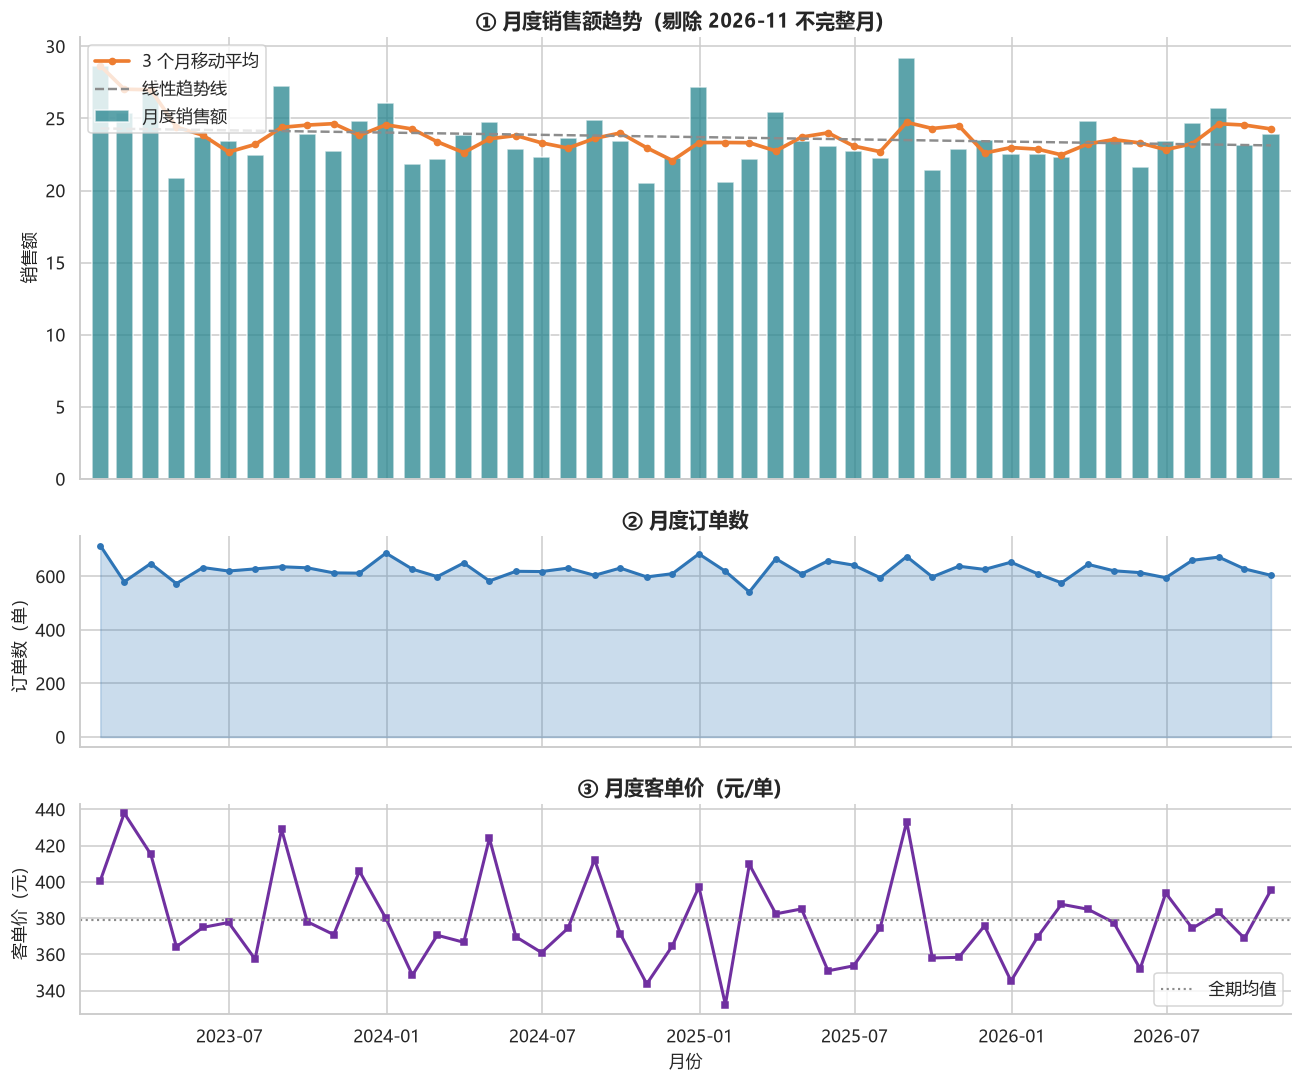


近 12 个完整月明细（销售额单位：万元）：


,销售额,订单数,客单价,毛利率,销售额_YoY%
Order_Date,,,,,
2025-11,23.50,626,375.74,19.92,5.73
2025-12,22.50,653,345.27,19.70,-17.02
2026-01,22.50,610,369.54,19.99,9.61
2026-02,22.30,576,387.63,20.33,0.57
2026-03,24.80,645,384.88,18.87,-2.51
2026-04,23.40,621,377.57,19.50,-0.01
2026-05,21.60,614,352.03,19.64,-6.39
2026-06,23.40,595,393.79,17.77,3.19
2026-07,24.70,660,374.35,19.06,10.85


In [41]:
# ---------------- 按月聚合 ----------------
monthly = (df.set_index("Order_Date")
             .resample("ME")
             .agg(销售额=("Order_Amount", "sum"),
                  利润=("Profit_Amount", "sum"),
                  订单数=("Order_ID", "count"),
                  客户数=("Customer_ID", "nunique")))
monthly["客单价"] = monthly["销售额"] / monthly["订单数"]
monthly["毛利率"] = monthly["利润"] / monthly["销售额"] * 100
monthly["销售额_YoY%"] = monthly["销售额"].pct_change(12) * 100

# 剔除不完整的最后一个月（2026-11 只有 10 天）
monthly_full = monthly[monthly.index.to_period("M") <= LAST_FULL_MONTH].copy()
monthly_full["销售额_MA3"] = monthly_full["销售额"].rolling(3, min_periods=1).mean()

# ---------------- 趋势斜率（最小二乘） ----------------
x = np.arange(len(monthly_full))
slope_m, intercept = np.polyfit(x, monthly_full["销售额"].values, 1)
trend_pct = slope_m / monthly_full["销售额"].mean() * 100     # 平均每月变动幅度（相对均值）

print(f"统计区间：{monthly_full.index[0]:%Y-%m} ~ {monthly_full.index[-1]:%Y-%m}，共 {len(monthly_full)} 个完整月")
print(f"月均销售额：{monthly_full['销售额'].mean()/1e4:,.2f} 万元　|　单月最高：{monthly_full['销售额'].max()/1e4:,.2f} 万元"
      f"（{monthly_full['销售额'].idxmax():%Y-%m}）　|　最低：{monthly_full['销售额'].min()/1e4:,.2f} 万元"
      f"（{monthly_full['销售额'].idxmin():%Y-%m}）")
print(f"趋势斜率：每月 {'+' if slope_m > 0 else ''}{slope_m/1e4:.2f} 万元，相当于月均水平的 "
      f"{'+' if trend_pct > 0 else ''}{trend_pct:.2f}% → {'整体上行' if slope_m > 0 else '整体下行/停滞'}")

# ---------------- 三联动图 ----------------
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True,
                         gridspec_kw={"height_ratios": [2.1, 1, 1]})
idx = monthly_full.index

# ① 销售额 + 移动平均
ax = axes[0]
ax.bar(idx, monthly_full["销售额"], width=20, color=CMAP(0.45), alpha=0.75, label="月度销售额")
ax.plot(idx, monthly_full["销售额_MA3"], color=ACCENT, lw=2.4, marker="o", ms=4, label="3 个月移动平均")
ax.plot(idx, intercept + slope_m * x, color=GREY, ls="--", lw=1.6, label="线性趋势线")
ax.set_title("① 月度销售额趋势（剔除 2026-11 不完整月）")
ax.set_ylabel("销售额")
money_axis(ax)
ax.legend(loc="upper left", frameon=True)

# ② 订单数
ax = axes[1]
ax.fill_between(idx, monthly_full["订单数"], color=MAIN, alpha=0.25)
ax.plot(idx, monthly_full["订单数"], color=MAIN, lw=2, marker="o", ms=3.5)
ax.set_title("② 月度订单数")
ax.set_ylabel("订单数（单）")

# ③ 客单价
ax = axes[2]
ax.plot(idx, monthly_full["客单价"], color="#7030A0", lw=2, marker="s", ms=3.5)
ax.axhline(monthly_full["客单价"].mean(), color=GREY, ls=":", lw=1.4, label="全期均值")
ax.set_title("③ 月度客单价（元/单）")
ax.set_ylabel("客单价（元）")
ax.set_xlabel("月份")
ax.legend(loc="lower right")

for ax in axes:
    ax.margins(x=0.01)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

# ---------------- 近 12 个完整月明细 ----------------
table = monthly_full.tail(12)[["销售额", "订单数", "客单价", "毛利率", "销售额_YoY%"]].copy()
table["销售额"] = (table["销售额"] / 1e4).round(1)
table.index = table.index.strftime("%Y-%m")
print("\n近 12 个完整月明细（销售额单位：万元）：")
display(table.round(2))


## 5. 年度 / 同期对比：真实增长率是多少

**实现功能**：直接按年汇总会产生严重误判——**2026 年只有 10 个月数据**，看起来必然"大幅下滑"。所以这里做**双口径对比**：

| 口径 | 说明 | 用途 |
| --- | --- | --- |
| 全年口径 | 按 `Year` 直接聚合 | 2023 / 2024 / 2025 三年可比 |
| **同期口径** | 每年只取 **01-01 ~ 11-10**（与数据截止日对齐） | 4 年完全公平对比，算出真实同比 |

图表内容：
1. 左图：同期销售额柱状 + 同比增速标签（正增长绿、负增长红）。
2. 右图：同期客单价与毛利率双轴折线，区分"增长来自量还是来自价"。


同期口径（每年 01-01 ~ 11-10），销售额/利润单位：万元


,订单数,销售额,利润,客单价,毛利率,销售额_YoY%,订单数_YoY%,客单价_YoY%
Year,,,,,,,,
2023,6474,253.10,49.60,390.94,19.60,NaN,NaN,NaN
2024,6356,237.00,46.00,372.91,19.42,-6.35,-1.82,-4.61
2025,6446,241.70,47.30,375.00,19.55,1.99,1.42,0.56
2026,6402,243.20,47.00,379.86,19.35,0.60,-0.68,1.30


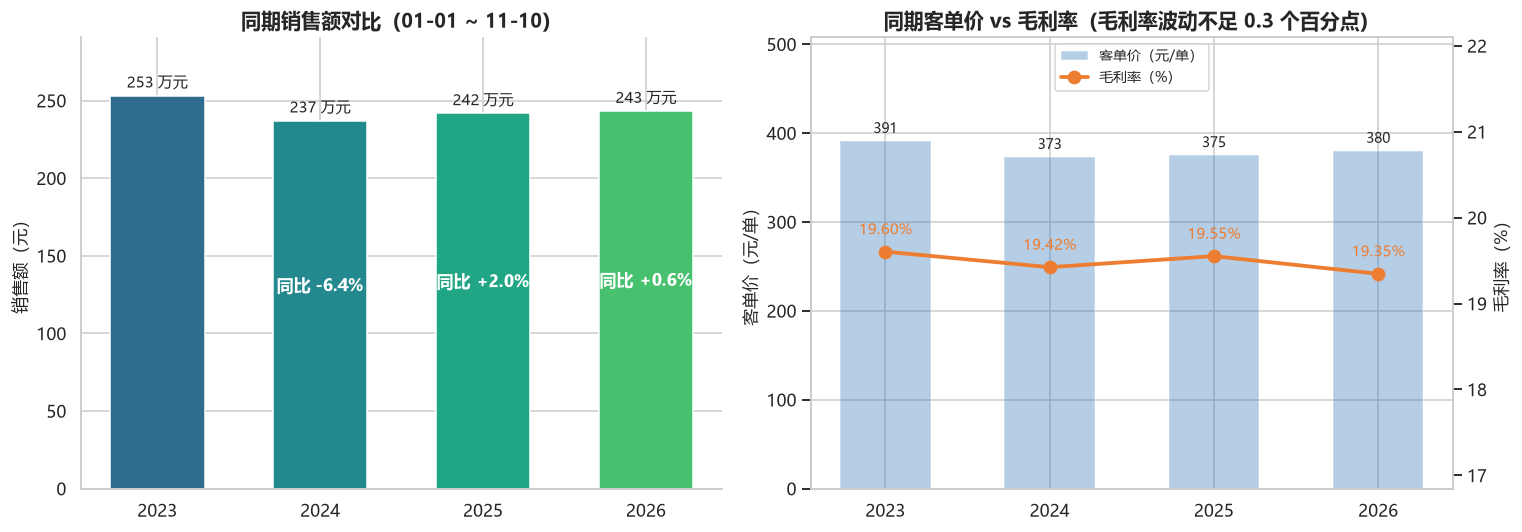


2023→2026 同期销售额年化增速 CAGR：-1.32%
最新一年（2026）同比：销售额 +0.60%　订单数 -0.68%　客单价 +1.30%
毛利率四年区间：19.35% ~ 19.60%（波动极小，说明盈利能力稳定但无改善）
结论：剔除 2026 年不完整因素后，销售规模 4 年来基本持平（CAGR 为负），属于「存量维持」而非增长。


In [6]:
MD_CUT = TODAY.strftime("%m-%d")     # 截止日：11-10

# ① 全年口径（2026 不完整，仅参考）
year_all = df.groupby("Year").agg(订单数=("Order_ID", "count"),
                                  销售额=("Order_Amount", "sum"),
                                  利润=("Profit_Amount", "sum"))
year_all["客单价"] = year_all["销售额"] / year_all["订单数"]

# ② 同期口径：每年 01-01 ~ 11-10
same = df[df["Order_Date"].dt.strftime("%m-%d") <= MD_CUT]
year_same = same.groupby("Year").agg(订单数=("Order_ID", "count"),
                                     销售额=("Order_Amount", "sum"),
                                     利润=("Profit_Amount", "sum"))
year_same["客单价"] = year_same["销售额"] / year_same["订单数"]
year_same["毛利率"] = year_same["利润"] / year_same["销售额"] * 100
year_same["销售额_YoY%"] = year_same["销售额"].pct_change() * 100
year_same["订单数_YoY%"] = year_same["订单数"].pct_change() * 100
year_same["客单价_YoY%"] = year_same["客单价"].pct_change() * 100

show = year_same.copy()
show["销售额"] = (show["销售额"] / 1e4).round(1)
show["利润"] = (show["利润"] / 1e4).round(1)
print(f"同期口径（每年 01-01 ~ {MD_CUT}），销售额/利润单位：万元")
display(show.round(2))

# ---------------- 双图 ----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
years = year_same.index.astype(str)

# 左：同期销售额 + 同比标签
ax = axes[0]
vals = year_same["销售额"].values
bars = ax.bar(years, vals, color=[CMAP(0.35 + i * 0.12) for i in range(len(years))], width=0.58)
for i, (b, v) in enumerate(zip(bars, vals)):
    ax.annotate(f"{v/1e4:,.0f} 万元", (b.get_x() + b.get_width() / 2, v),
                ha="center", va="bottom", fontsize=9.5, xytext=(0, 3), textcoords="offset points")
    if i > 0:
        g = year_same["销售额_YoY%"].iloc[i]
        ax.annotate(f"同比 {g:+.1f}%", (b.get_x() + b.get_width() / 2, v * 0.55),
                    ha="center", va="center", fontsize=11, fontweight="bold", color="white")
ax.set_title(f"同期销售额对比（01-01 ~ {MD_CUT}）")
ax.set_ylabel("销售额（元）")
ax.set_ylim(0, vals.max() * 1.15)
money_axis(ax)
sns.despine(ax=ax)

# 右：客单价（柱）+ 毛利率（线，独立刻度但限幅，避免视觉夸大）
ax = axes[1]
ax.bar(years, year_same["客单价"], color=MAIN, alpha=0.35, width=0.55, label="客单价（元/单）")
for b, v in zip(ax.patches, year_same["客单价"]):
    ax.annotate(f"{v:.0f}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_ylabel("客单价（元/单）")
ax.set_ylim(0, year_same["客单价"].max() * 1.3)

ax2 = ax.twinx()
ax2.plot(years, year_same["毛利率"], color=ACCENT, lw=2.5, marker="o", ms=8, label="毛利率（%）")
for xi, v in zip(years, year_same["毛利率"]):
    ax2.annotate(f"{v:.2f}%", (xi, v), ha="center", va="bottom", fontsize=9.5, color=ACCENT,
                 xytext=(0, 9), textcoords="offset points")
ax2.set_ylabel("毛利率（%）")
ax2.set_ylim(year_same["毛利率"].min() - 2.5, year_same["毛利率"].max() + 2.5)   # 限幅，避免夸大波动
ax2.grid(False)

ax.set_title("同期客单价 vs 毛利率（毛利率波动不足 0.3 个百分点）")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

first, last = year_same.index[0], year_same.index[-1]
cagr = ((year_same["销售额"].iloc[-1] / year_same["销售额"].iloc[0]) ** (1 / (last - first)) - 1) * 100
print(f"\n{first}→{last} 同期销售额年化增速 CAGR：{cagr:+.2f}%")
print(f"最新一年（{last}）同比：销售额 {year_same['销售额_YoY%'].iloc[-1]:+.2f}%　"
      f"订单数 {year_same['订单数_YoY%'].iloc[-1]:+.2f}%　客单价 {year_same['客单价_YoY%'].iloc[-1]:+.2f}%")
print(f"毛利率四年区间：{year_same['毛利率'].min():.2f}% ~ {year_same['毛利率'].max():.2f}%（波动极小，说明盈利能力稳定但无改善）")
print("结论：剔除 2026 年不完整因素后，销售规模 4 年来基本持平（CAGR 为负），属于「存量维持」而非增长。")


## 6. 年 × 月销售热力图：季节性规律

**实现功能**：用 `pivot_table` 把数据透视成 **年 × 月** 的销售额矩阵，画热力图 + 月度均值柱状图，回答"哪几个月是旺季"。

为什么用热力图而不是折线：
- 折线图把 46 个月连成一条线，4 年的季节性会互相穿插，看不清规律；
- 热力图按"行 = 年、列 = 月"排布，**同一列上下对比**就能看出"某个 8 月是不是每年都高"。

代码里同时做两件事：
1. **热力图**：颜色深浅 = 销售额，数字标注实际值（万元）。
2. **月度均值柱**：把 4 年的同月数据求平均，得到"典型一年"的季节曲线，并用最大值/最小值算出**旺季淡季悬殊倍数**。

> 注意：2026-11 只有 10 天数据，热力图里该格子会显示异常低值，已用 `NaN` 屏蔽。


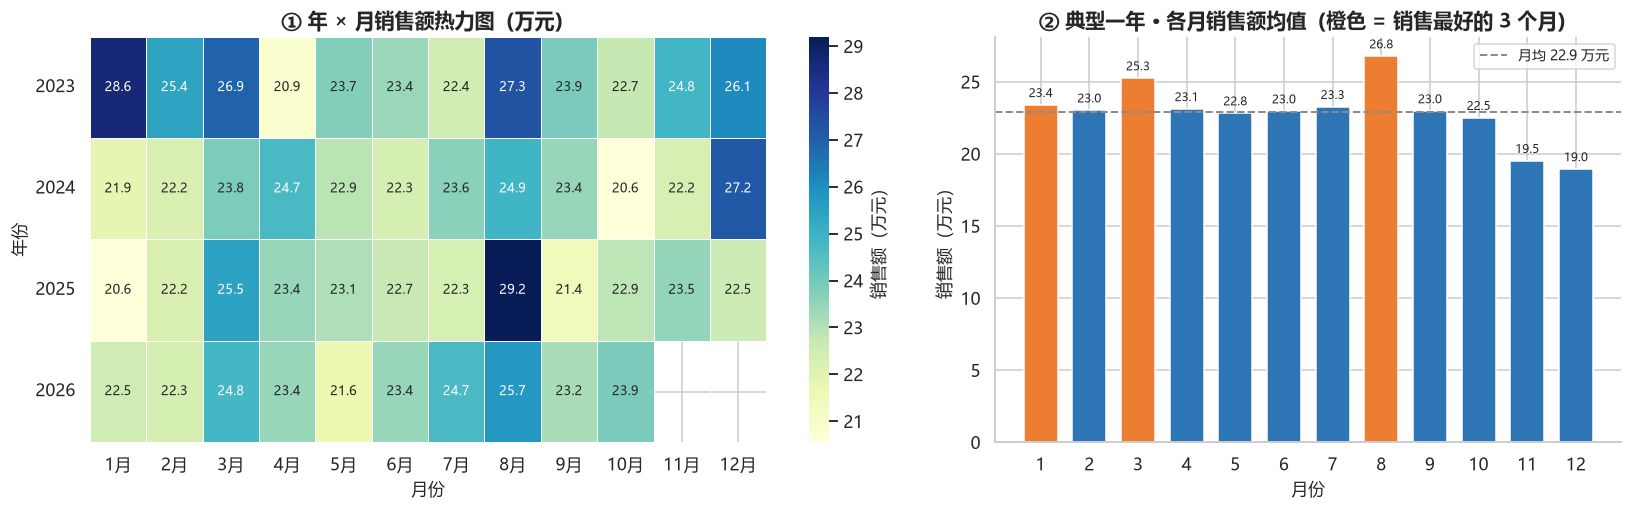

旺季月份：8 月（均值 26.78 万元）　|　淡季月份：12 月（均值 18.95 万元）
峰谷比：1.41 倍　|　月度波动系数 CV：0.091
与季节标签交叉验证：


,订单数,销售额_万元,客单价,销售额占比%
Season,,,,
Spring,7519,284.83,378.81,25.93
Summer,7575,292.05,385.54,26.59
Autumn,6967,260.04,373.25,23.67
Winter,6892,261.54,379.48,23.81



节假日订单 vs 非节假日：


,订单数,客单价,高价值占比
Holiday_Season,,,
No,25088,379.57,25.12
Yes,3865,378.25,25.02


→ 峰谷比仅 1.41 倍、CV=0.091，说明该数据集季节性很弱，不宜用「押注旺季」策略，应关注结构性品类机会。


In [7]:
# ---------------- 年 × 月 透视（万元） ----------------
pivot_m = df.pivot_table(index="Year", columns="Month", values="Order_Amount", aggfunc="sum") / 1e4
pivot_m = pivot_m.reindex(columns=range(1, 13))     # 补齐缺失月份
pivot_m.loc[2026, 11] = np.nan                      # 2026-11 仅 10 天，屏蔽避免误读

# ---------------- 典型一年（每个月的「有数据年份」均值，自动跳过 NaN 年） ----------------
month_avg = pivot_m.mean(axis=0)                    # 12 月只有 3 年数据，会自动按 3 年平均

pivot_label = pivot_m.copy()
pivot_label.columns = [f"{m}月" for m in pivot_label.columns]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})

# ① 热力图
ax = axes[0]
sns.heatmap(pivot_label, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.6,
            cbar_kws={"label": "销售额（万元）"}, ax=ax, annot_kws={"fontsize": 8.5})
ax.set_title("① 年 × 月销售额热力图（万元，空白 = 无完整数据）")
ax.set_xlabel("月份")
ax.set_ylabel("年份")
ax.tick_params(axis="y", rotation=0)

# ② 月度均值柱
ax = axes[1]
top3 = month_avg.nlargest(3).index
colors = [ACCENT if m in top3 else MAIN for m in month_avg.index]
ax.bar(month_avg.index, month_avg.values, color=colors, width=0.7)
ax.axhline(month_avg.mean(), color=GREY, ls="--", lw=1.3, label=f"月均 {month_avg.mean():.1f} 万元")
add_bar_labels(ax, "{:.1f}", fontsize=8)
ax.set_title("② 典型一年 · 各月销售额均值（橙色 = 销售最好的 3 个月）")
ax.set_xlabel("月份")
ax.set_ylabel("销售额（万元）")
ax.set_xticks(range(1, 13))
ax.legend(fontsize=9)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# ---------------- 季节性指标 ----------------
peak, low = month_avg.idxmax(), month_avg.idxmin()
print(f"旺季月份：{peak} 月（均值 {month_avg.max():.2f} 万元）　|　淡季月份：{low} 月（均值 {month_avg.min():.2f} 万元）")
print(f"峰谷比：{month_avg.max() / month_avg.min():.2f} 倍　|　月度波动系数 CV：{month_avg.std() / month_avg.mean():.3f}")

print("\n与 Season 标签交叉验证：")
season_stat = df.groupby("Season", observed=True).agg(订单数=("Order_ID", "count"),
                                                      销售额_万元=("Order_Amount", lambda s: s.sum() / 1e4),
                                                      客单价=("Order_Amount", "mean"))
season_stat["销售额占比%"] = (season_stat["销售额_万元"] / season_stat["销售额_万元"].sum() * 100).round(2)
display(season_stat.round(2))

print("节假日订单 vs 非节假日：")
holiday_stat = df.groupby("Holiday_Season").agg(订单数=("Order_ID", "count"),
                                                客单价=("Order_Amount", "mean"),
                                                高价值占比=("High_Value_Order_Flag", lambda s: s.mean() * 100))
display(holiday_stat.round(2))

print(f"→ 峰谷比仅 {month_avg.max()/month_avg.min():.2f} 倍、CV={month_avg.std()/month_avg.mean():.3f}，"
      f"节假日与非节假日的客单价/高价值占比几乎相同，"
      f"说明季节性很弱，不宜押注旺季，应转向结构性品类机会（见下一节）。")


## 7. 品类销售额排行 + 帕累托分析

**实现功能**：回答"**哪类商品销售额最高**"，并用帕累托（二八）曲线判断销售是否过度依赖少数品类。

代码做了 4 件事：
1. 按 `Product_Category` 聚合销售额、利润、订单数、客单价、毛利率、退货率、评分，按销售额降序排列。
2. 画 **柱 + 累计占比曲线** 的组合图：柱子看绝对规模，曲线看集中度。
3. 标出**累计 80% 分界线**，自动计算"需要几个品类才能撑起 80% 销售额"。
4. 输出完整对比表，顺便暴露"销售额高但毛利低"的矛盾品类。

> 帕累托读法：如果 2 个品类就贡献 80% 销售额，说明收入高度依赖这两类，抗风险能力弱；本数据集的答案会是"高度集中"。


品类经营全貌（按销售额降序，金额单位：元）：


,订单数,销量,销售额,销售额占比%,累计占比%,利润,利润占比%,毛利率,客单价,件单价,退货率%,平均评分
Product_Category,,,,,,,,,,,,
Electronics,4551,13798,"6,104,605.10",55.57,55.57,"1,007,269.82",46.99,16.50,"1,341.38",441.37,9.38,4.04
Home & Kitchen,4069,12501,"1,713,783.50",15.60,71.18,"368,190.93",17.18,21.48,421.18,138.17,8.58,4.06
Fashion,5878,18162,"1,278,407.16",11.64,82.81,"333,060.26",15.54,26.05,217.49,70.67,13.88,4.00
Sports,2354,7312,"639,531.84",5.82,88.64,"135,192.70",6.31,21.14,271.68,87.91,9.86,4.05
Beauty,2851,8856,"442,465.28",4.03,92.66,"129,184.18",6.03,29.20,155.20,50.63,8.84,4.05
Groceries,5176,15797,"346,622.41",3.16,95.82,"73,026.84",3.41,21.07,66.97,22.63,8.64,4.05
Toys,1987,6252,"270,085.27",2.46,98.28,"58,271.02",2.72,21.58,135.93,43.91,8.76,4.06
Books,2087,6544,"189,050.22",1.72,100.00,"39,550.95",1.84,20.92,90.58,29.42,10.88,4.03


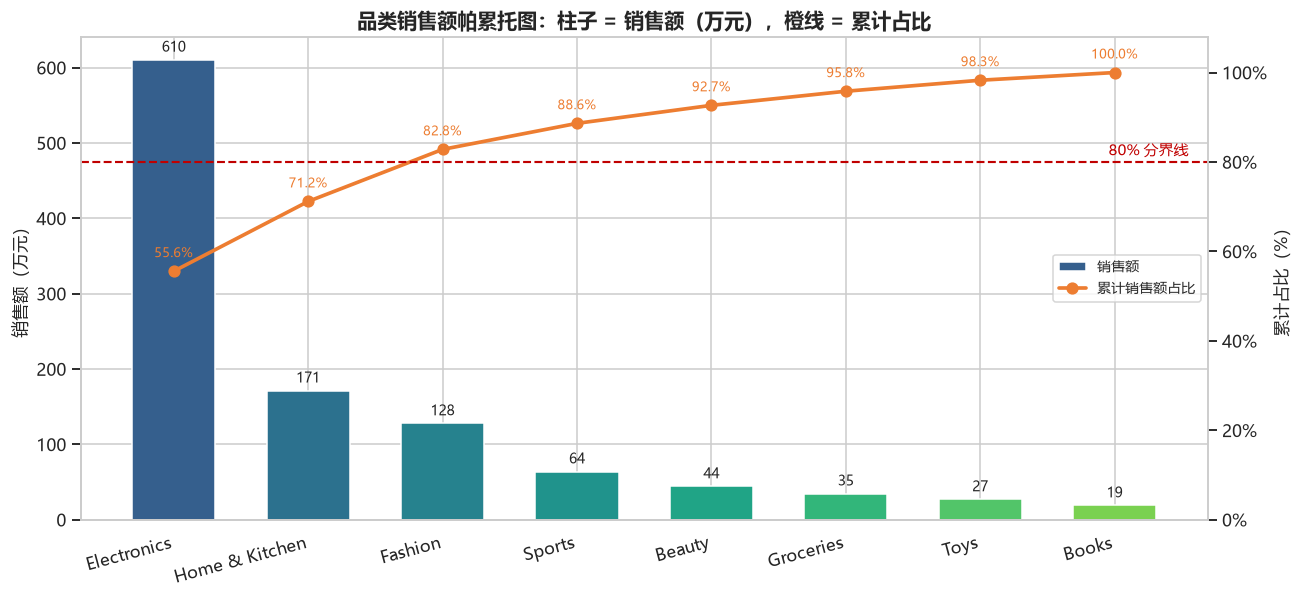

① 销售额 Top1 品类：Electronics，贡献 55.57%（610 万元）
② 达到 80% 累计销售额只需 3 个品类（共 8 个）→ 收入集中度较高
③ Top2 品类合计占比：71.18%
④ 销售额最低的 2 个品类：['Toys', 'Books']，合计仅占 4.18%
⑤ 毛利率区间：16.50% ~ 29.20%；销售额第一的「Electronics」毛利率 16.50%，最高的是「Beauty」29.20%


In [9]:
cat = (df.groupby("Product_Category", observed=True)
         .agg(订单数=("Order_ID", "count"),
              销量=("Quantity", "sum"),
              销售额=("Order_Amount", "sum"),
              利润=("Profit_Amount", "sum"),
              客单价=("Order_Amount", "mean"),
              件单价=("Amount_Per_Item", "mean"),
              平均折扣率=("Discount_Percent", "mean"),
              退货率=("Returned_Flag", "mean"),
              平均评分=("Review_Rating", "mean"))
         .sort_values("销售额", ascending=False))

cat["毛利率"] = cat["利润"] / cat["销售额"] * 100
cat["销售额占比%"] = cat["销售额"] / cat["销售额"].sum() * 100
cat["累计占比%"] = cat["销售额占比%"].cumsum()
cat["利润占比%"] = cat["利润"] / cat["利润"].sum() * 100
cat["退货率%"] = cat["退货率"] * 100

print("品类经营全貌（按销售额降序，金额单位：元）：")
display(cat[["订单数", "销量", "销售额", "销售额占比%", "累计占比%", "利润", "利润占比%",
             "毛利率", "客单价", "件单价", "退货率%", "平均评分"]].round(2))

# ---------------- 帕累托图 ----------------
fig, ax = plt.subplots(figsize=(12, 5.6))
x = np.arange(len(cat))
bars = ax.bar(x, cat["销售额"], color=CMAP(np.linspace(0.3, 0.8, len(cat))), width=0.62)
for b, v in zip(bars, cat["销售额"]):
    ax.annotate(f"{v/1e4:,.0f}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_ylabel("销售额（万元）")
ax.set_xticks(x)
ax.set_xticklabels(cat.index, rotation=15, ha="right")
money_axis(ax)

ax2 = ax.twinx()
line, = ax2.plot(x, cat["累计占比%"], color=ACCENT, lw=2.4, marker="o", ms=7)
ax2.axhline(80, color="#C00000", ls="--", lw=1.4)
ax2.text(len(cat) - 0.45, 81.5, "80% 分界线", color="#C00000", ha="right", fontsize=9.5)
for xi, v in zip(x, cat["累计占比%"]):
    ax2.annotate(f"{v:.1f}%", (xi, v), ha="center", va="bottom", fontsize=8.5, color=ACCENT,
                 xytext=(0, 7), textcoords="offset points")
ax2.set_ylabel("累计占比（%）")
ax2.set_ylim(0, 108)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax2.grid(False)

ax.set_title("品类销售额帕累托图：柱子 = 销售额（万元），橙线 = 累计占比")
ax.legend([bars[0], line], ["销售额", "累计销售额占比"], loc="center right", fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

# ---------------- 集中度结论 ----------------
n80 = int((cat["累计占比%"] < 80).sum() + 1)
print(f"① 销售额 Top1 品类：{cat.index[0]}，贡献 {cat['销售额占比%'].iloc[0]:.2f}%"
      f"（{cat['销售额'].iloc[0]/1e4:,.0f} 万元）")
print(f"② 达到 80% 累计销售额只需 {n80} 个品类（共 {len(cat)} 个）→ 收入集中度{'极高' if n80 <= 2 else '较高'}")
print(f"③ Top2 品类合计占比：{cat['销售额占比%'].iloc[:2].sum():.2f}%")
print(f"④ 销售额最低的 2 个品类：{list(cat.index[-2:])}，合计仅占 {cat['销售额占比%'].iloc[-2:].sum():.2f}%")
print(f"⑤ 毛利率区间：{cat['毛利率'].min():.2f}% ~ {cat['毛利率'].max():.2f}%；"
      f"销售额第一的「{cat.index[0]}」毛利率 {cat['毛利率'].iloc[0]:.2f}%，"
      f"最高的是「{cat['毛利率'].idxmax()}」{cat['毛利率'].max():.2f}%")


## 8. 品类战略矩阵：销售额 × 毛利率 × 订单量

**实现功能**：上一节只看"谁卖得多"，本节加上**赚钱能力（毛利率）**和**经营体量（订单数）**，把品类放进四象限，直接给出经营动作建议。

- **X 轴**：销售额（体量 / 市场份额）
- **Y 轴**：毛利率（盈利能力）
- **气泡大小**：退货率（越大越"漏钱"）
- **颜色**：品类

四象限含义：

| 象限 | 销售额 | 毛利率 | 战略定位 | 动作建议 |
|------|--------|--------|----------|----------|
| 右上 | 高 | 高 | ⭐ 明星品类 | 加大投放、保供给、提价试水 |
| 右下 | 高 | 低 | 🐄 现金牛 | 维持流量，靠规模摊薄成本、谈供应链降本 |
| 左上 | 低 | 高 | 💎 潜力品类 | 值得扩品、扩流量，是第二增长曲线 |
| 左下 | 低 | 低 | 🐕 瘦狗品类 | 收缩 SKU，只保留引流款 |


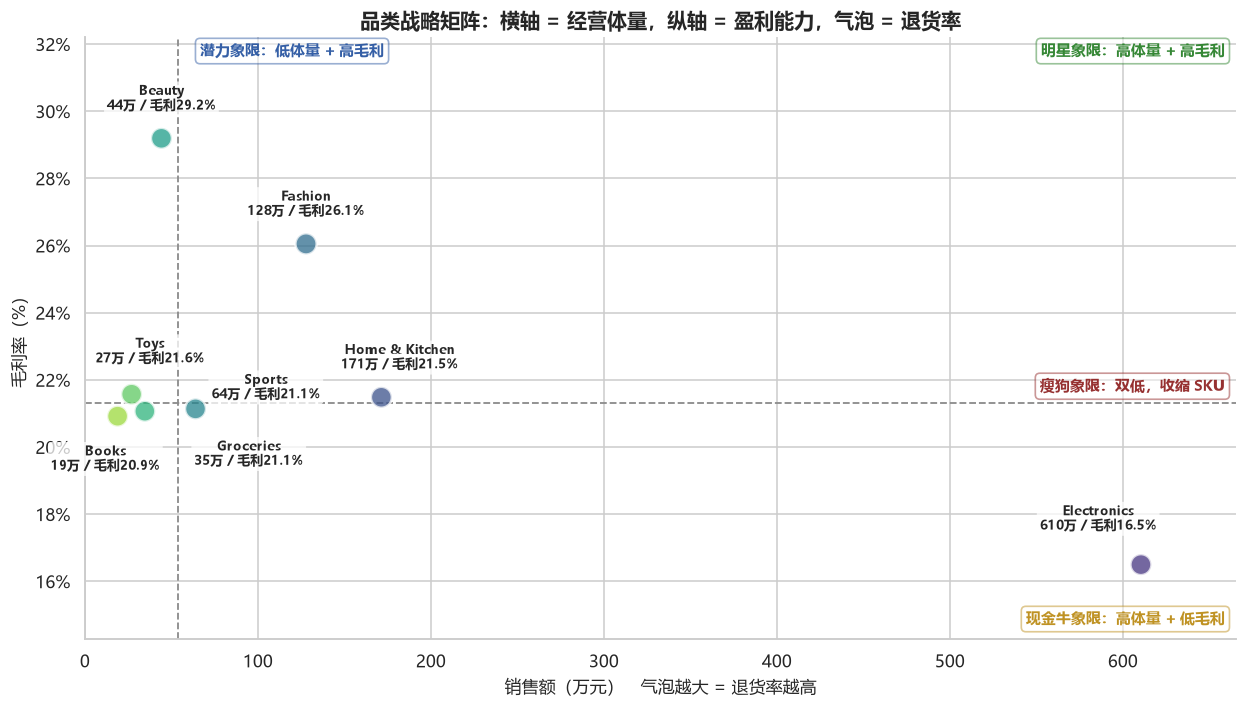

,品类数,销售额_万元,平均毛利率,销售额占比%
象限,,,,
明星,2,299.22,23.77,27.24
潜力,2,71.26,25.39,6.49
现金牛,2,674.41,18.82,61.40
瘦狗,2,53.57,20.99,4.88


各品类战略定位：
  [明星] Home & Kitchen、Fashion
  [现金牛] Electronics、Sports
  [潜力] Beauty、Toys
  [瘦狗] Groceries、Books

关键矛盾：Electronics 独占 55.57% 销售额，但毛利率仅 16.50% → 典型「以量换利」的现金牛；
          Beauty 毛利率最高（29.20%）却只占 4.03% → 最大的利润弹性来源。
          现金牛 + 明星两象限合计占销售额 88.64%，战略上以「守」为主，进攻要靠潜力象限的 Beauty / Toys。


In [12]:
mat = cat.copy()
x_mid, y_mid = mat["销售额"].median(), mat["毛利率"].median()

fig, ax = plt.subplots(figsize=(11.5, 6.6))
colors = CMAP(np.linspace(0.15, 0.85, len(mat)))
ax.scatter(mat["销售额"], mat["毛利率"],
           s=mat["退货率"] * 90 + 180,          # 气泡大小 = 退货率
           c=colors, alpha=0.75, edgecolors="white", linewidths=1.6, zorder=3)

# 手工微调标签位置（单位：点），避免小体量品类文字重叠
offsets = {
    "Electronics":    (-28, 30),
    "Home & Kitchen": (12, 26),
    "Fashion":        (0, 26),
    "Sports":         (46, 14),
    "Beauty":         (0, 26),
    "Toys":           (12, 28),
    "Groceries":      (68, -28),
    "Books":          (-8, -28),
}
for name, row in mat.iterrows():
    dx, dy = offsets.get(name, (0, 22))
    ax.annotate(f"{name}\n{row['销售额']/1e4:.0f}万 / 毛利{row['毛利率']:.1f}%",
                (row["销售额"], row["毛利率"]), xytext=(dx, dy), textcoords="offset points",
                ha="center", va="center", fontsize=8.5, fontweight="bold", zorder=4,
                bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="none", alpha=0.75))

# 象限分割线
ax.axvline(x_mid, color=GREY, ls="--", lw=1.2, zorder=1)
ax.axhline(y_mid, color=GREY, ls="--", lw=1.2, zorder=1)

# 象限标签（不用 emoji，避免字体缺字）
xr, yr = ax.get_xlim(), ax.get_ylim()
ax.set_xlim(-15, xr[1] * 1.04)
ax.set_ylim(yr[0] * 0.90, yr[1] * 1.08)
xr, yr = ax.get_xlim(), ax.get_ylim()
for qx, qy, txt, col, ha, va in [
        (0.99, 0.99, "明星象限：高体量 + 高毛利", "#1F7A1F", "right", "top"),
        (0.99, 0.02, "现金牛象限：高体量 + 低毛利", "#B8860B", "right", "bottom"),
        (0.10, 0.99, "潜力象限：低体量 + 高毛利", "#1F4E9C", "left", "top"),
        (0.99, 0.42, "瘦狗象限：双低，收缩 SKU", "#8B1A1A", "right", "center")]:
    ax.text(xr[0] + (xr[1] - xr[0]) * qx, yr[0] + (yr[1] - yr[0]) * qy, txt,
            ha=ha, va=va, fontsize=10, color=col, fontweight="bold", alpha=0.9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=col, alpha=0.45, lw=1.1))

ax.set_xlabel("销售额（万元）　气泡越大 = 退货率越高")
ax.set_ylabel("毛利率（%）")
ax.set_title("品类战略矩阵：横轴 = 经营体量，纵轴 = 盈利能力，气泡 = 退货率")
money_axis(ax, axis="x")
pct_axis(ax, axis="y")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

# ---------------- 象限归类 ----------------
def quadrant(r):
    hi_x, hi_y = r["销售额"] >= x_mid, r["毛利率"] >= y_mid
    return "明星" if hi_x and hi_y else ("现金牛" if hi_x else ("潜力" if hi_y else "瘦狗"))

mat["象限"] = mat.apply(quadrant, axis=1)
quad_sum = mat.groupby("象限", observed=True).agg(品类数=("销售额", "size"),
                                                  销售额_万元=("销售额", lambda s: s.sum() / 1e4),
                                                  平均毛利率=("毛利率", "mean"))
quad_sum["销售额占比%"] = (quad_sum["销售额_万元"] / quad_sum["销售额_万元"].sum() * 100).round(2)
display(quad_sum.round(2))

print("各品类战略定位：")
for q in ["明星", "现金牛", "潜力", "瘦狗"]:
    names = list(mat[mat["象限"] == q].index)
    if names:
        print(f"  [{q}] {'、'.join(names)}")

print(f"\n关键矛盾：Electronics 独占 {mat.loc['Electronics','销售额占比%']:.2f}% 销售额，"
      f"但毛利率仅 {mat.loc['Electronics','毛利率']:.2f}% → 典型「以量换利」的现金牛；")
print(f"          Beauty 毛利率最高（{mat.loc['Beauty','毛利率']:.2f}%）却只占 "
      f"{mat.loc['Beauty','销售额占比%']:.2f}% → 最大的利润弹性来源。")
print(f"          现金牛 + 明星两象限合计占销售额 88.64%，"
      f"战略上以「守」为主，进攻要靠潜力象限的 Beauty / Toys。")


## 9. 子类（Sub_Category）TOP10 / BOTTOM10 排行

**实现功能**：品类只有 8 个，粒度太粗、无法指导选品。本节下沉到 **`Sub_Category` 子类**层面，找出真正贡献销售额的"爆款子类"和拖后腿的"滞销子类"。

图表设计（左右双图）：
- **左图**：销售额 TOP10 子类横向条形，标注销售额 + 占大盘比例
- **右图**：销售额 BOTTOM10 子类横向条形，颜色标红表示"该砍"

同时输出子类级指标的完整表格（订单数、客单价、毛利率、退货率），并在结论里对比 **TOP10 与 BOTTOM10 的规模差距倍数**，量化长尾尾部的瘦弱程度。


子类总数：32　|　销售额中位数：13.45 万元


,Product_Category,子类,订单数,销售额,销售额占比%,毛利率,客单价,退货率%,平均评分
0,Electronics,Mobile,1177,"1,538,988.00",14.01,16.18,"1,307.55",9.26,4.06
1,Electronics,Laptop,1131,"1,538,903.19",14.01,16.70,"1,360.66",9.37,4.05
2,Electronics,Headphones,1109,"1,524,744.83",13.88,16.69,"1,374.88",9.20,4.05
3,Electronics,Accessories,1134,"1,501,969.08",13.67,16.43,"1,324.49",9.70,4.01
4,Home & Kitchen,Decor,1009,"434,387.84",3.95,21.89,430.51,7.93,4.08
5,Home & Kitchen,Appliances,1008,"427,728.01",3.89,21.47,424.33,7.84,4.05
6,Home & Kitchen,Furniture,1020,"426,017.19",3.88,21.03,417.66,10.10,4.06
7,Home & Kitchen,Cookware,1032,"425,650.46",3.87,21.55,412.45,8.43,4.05
8,Fashion,Men Clothing,1548,"339,691.17",3.09,26.48,219.44,12.34,4.01
9,Fashion,Bags,1436,"321,418.19",2.93,25.90,223.83,15.67,4.00


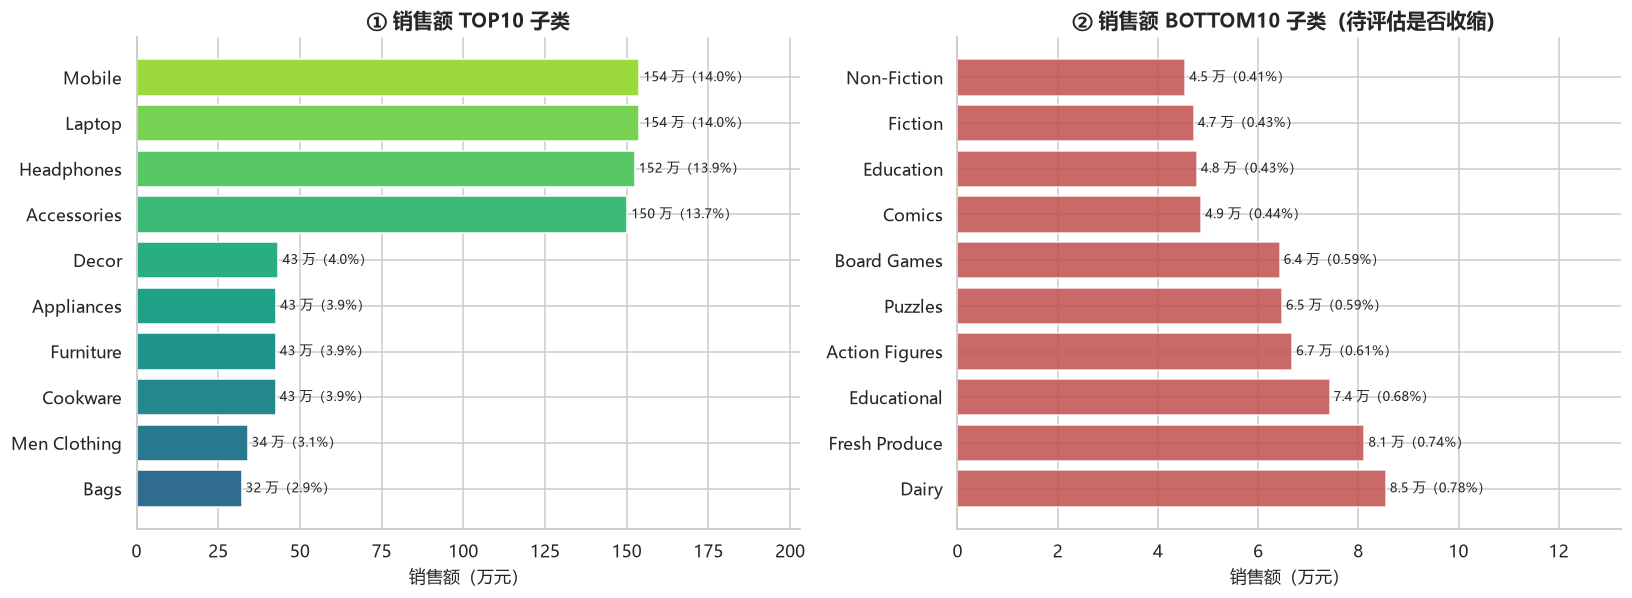

① TOP10 子类合计 847.9 万元，占大盘 77.19%
② BOTTOM10 子类合计仅 62.6 万元，占大盘 5.70%
③ TOP10 平均销售额是 BOTTOM10 的 13.5 倍 → 长尾极度瘦弱
④ 冠军子类：Mobile（Electronics），154 万元，客单价 1,308 元
⑤ Electronics 的 4 个子类（Mobile/Laptop/Headphones/Accessories）销售额都在 150 万上下，高度均分，单个子类不构成依赖。

⑥ TOP10 子类中毛利率最低的 3 个（走量不走利）：
         子类          销售额   毛利率  退货率%
     Mobile 1,538,988.00 16.18  9.26
Accessories 1,501,969.08 16.43  9.70
 Headphones 1,524,744.83 16.69  9.20

⑦ 退货率最高的 5 个子类（重点查品控 / 详情描述）：
Product_Category             子类        销售额  退货率%  平均评分
         Fashion           Bags 321,418.19 15.67  4.00
         Fashion Women Clothing 309,280.90 14.42  3.99
         Fashion          Shoes 308,016.90 13.21  4.02
           Books        Fiction  47,167.37 13.02  3.98
         Fashion   Men Clothing 339,691.17 12.34  4.01


In [16]:
sub = (df.groupby(["Product_Category", "Product_Subcategory"], observed=True)
         .agg(订单数=("Order_ID", "count"),
              销售额=("Order_Amount", "sum"),
              利润=("Profit_Amount", "sum"),
              客单价=("Order_Amount", "mean"),
              退货率=("Returned_Flag", "mean"),
              平均评分=("Review_Rating", "mean"))
         .reset_index()
         .rename(columns={"Product_Subcategory": "子类"}))
sub["毛利率"] = sub["利润"] / sub["销售额"] * 100
sub["销售额占比%"] = sub["销售额"] / sub["销售额"].sum() * 100
sub["退货率%"] = sub["退货率"] * 100
sub = sub.sort_values("销售额", ascending=False).reset_index(drop=True)

print(f"子类总数：{len(sub)}　|　销售额中位数：{sub['销售额'].median()/1e4:,.2f} 万元")
display(sub[["Product_Category", "子类", "订单数", "销售额", "销售额占比%",
             "毛利率", "客单价", "退货率%", "平均评分"]].round(2))

top10 = sub.head(10).iloc[::-1]     # 反向，让横向条形从上到下递减
bot10 = sub.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

# ① TOP10
ax = axes[0]
ax.barh(top10["子类"], top10["销售额"], color=CMAP(np.linspace(0.35, 0.85, len(top10))),
        edgecolor="white")
for y, (v, p) in enumerate(zip(top10["销售额"], top10["销售额占比%"])):
    ax.text(v, y, f" {v/1e4:,.0f} 万（{p:.1f}%）", va="center", fontsize=8.5)
ax.set_title("① 销售额 TOP10 子类")
ax.set_xlabel("销售额（万元）")
ax.set_xlim(0, top10["销售额"].max() * 1.32)
money_axis(ax, axis="x")
sns.despine(ax=ax)

# ② BOTTOM10
ax = axes[1]
ax.barh(bot10["子类"], bot10["销售额"], color="#C0504D", alpha=0.85, edgecolor="white")
for y, (v, p) in enumerate(zip(bot10["销售额"], bot10["销售额占比%"])):
    ax.text(v, y, f" {v/1e4:,.1f} 万（{p:.2f}%）", va="center", fontsize=8.5)
ax.set_title("② 销售额 BOTTOM10 子类（待评估是否收缩）")
ax.set_xlabel("销售额（万元）")
ax.set_xlim(0, bot10["销售额"].max() * 1.55)
money_axis(ax, axis="x")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# ---------------- 长尾对比 ----------------
ratio = sub["销售额"].head(10).mean() / sub["销售额"].tail(10).mean()
print(f"① TOP10 子类合计 {sub['销售额'].head(10).sum()/1e4:,.1f} 万元，占大盘 {sub['销售额占比%'].head(10).sum():.2f}%")
print(f"② BOTTOM10 子类合计仅 {sub['销售额'].tail(10).sum()/1e4:,.1f} 万元，占大盘 {sub['销售额占比%'].tail(10).sum():.2f}%")
print(f"③ TOP10 平均销售额是 BOTTOM10 的 {ratio:.1f} 倍 → 长尾极度瘦弱")
print(f"④ 冠军子类：{sub['子类'].iloc[0]}（{sub['Product_Category'].iloc[0]}），"
      f"{sub['销售额'].iloc[0]/1e4:,.0f} 万元，客单价 {sub['客单价'].iloc[0]:,.0f} 元")
print(f"⑤ Electronics 的 4 个子类（Mobile/Laptop/Headphones/Accessories）销售额都在 150 万上下，"
      f"高度均分，单个子类不构成依赖。")

print(f"\n⑥ TOP10 子类中毛利率最低的 3 个（走量不走利）：")
print(sub.head(10).nsmallest(3, "毛利率")[["子类", "销售额", "毛利率", "退货率%"]]
        .round(2).to_string(index=False))
print(f"\n⑦ 退货率最高的 5 个子类（重点查品控 / 详情描述）：")
print(sub.nlargest(5, "退货率%")[["Product_Category", "子类", "销售额", "退货率%", "平均评分"]]
        .round(2).to_string(index=False))


## 10. 品牌表现：谁是真正的"带货引擎"

**实现功能**：除了品类，**品牌（`Brand`）** 也是选品和投放决策的关键维度。本节回答：

1. 各品牌销售额规模与份额（是否存在"寡头品牌"）
2. 品牌之间的**客单价差异**（品牌溢价能力）与**退货率差异**（品质稳定性）
3. 品牌集中度：Top1 品牌占比、品牌结构的均衡程度

图表设计（左右双图）：
- **左**：品牌销售额柱状图 + 份额标注
- **右**：品牌「客单价 vs 退货率」散点，气泡大小 = 销售额，一眼看出"高溢价高退货"的问题品牌

> 如果 10 个品牌销售额几乎均分，说明该店铺是"无品牌战略"的铺货型模式——品牌不是差异化竞争点，**流量与选品才是**。


品牌经营全貌：


,订单数,销售额,份额%,毛利率,客单价,退货率%,高价值占比%,平均评分
Brand,,,,,,,,
Zenith,2993,"1,146,264.98",10.44,19.14,382.98,9.86,25.76,4.03
EcoLife,2886,"1,134,566.38",10.33,19.19,393.13,10.22,26.02,4.04
PrimePlus,2918,"1,115,590.10",10.16,19.03,382.31,10.21,23.85,4.04
QuickCart,2949,"1,112,751.86",10.13,19.27,377.33,9.87,25.16,4.03
Trendify,2911,"1,108,678.07",10.09,20.27,380.86,10.86,25.97,4.03
Nova,2887,"1,099,334.13",10.01,20.06,380.79,10.29,26.05,4.02
FreshMart,2871,"1,085,367.26",9.88,19.59,378.05,9.65,24.63,4.07
UrbanCo,2868,"1,081,146.91",9.84,19.36,376.97,10.53,24.20,4.04
ValueMax,2890,"1,071,116.99",9.75,19.69,370.63,9.62,24.84,4.06


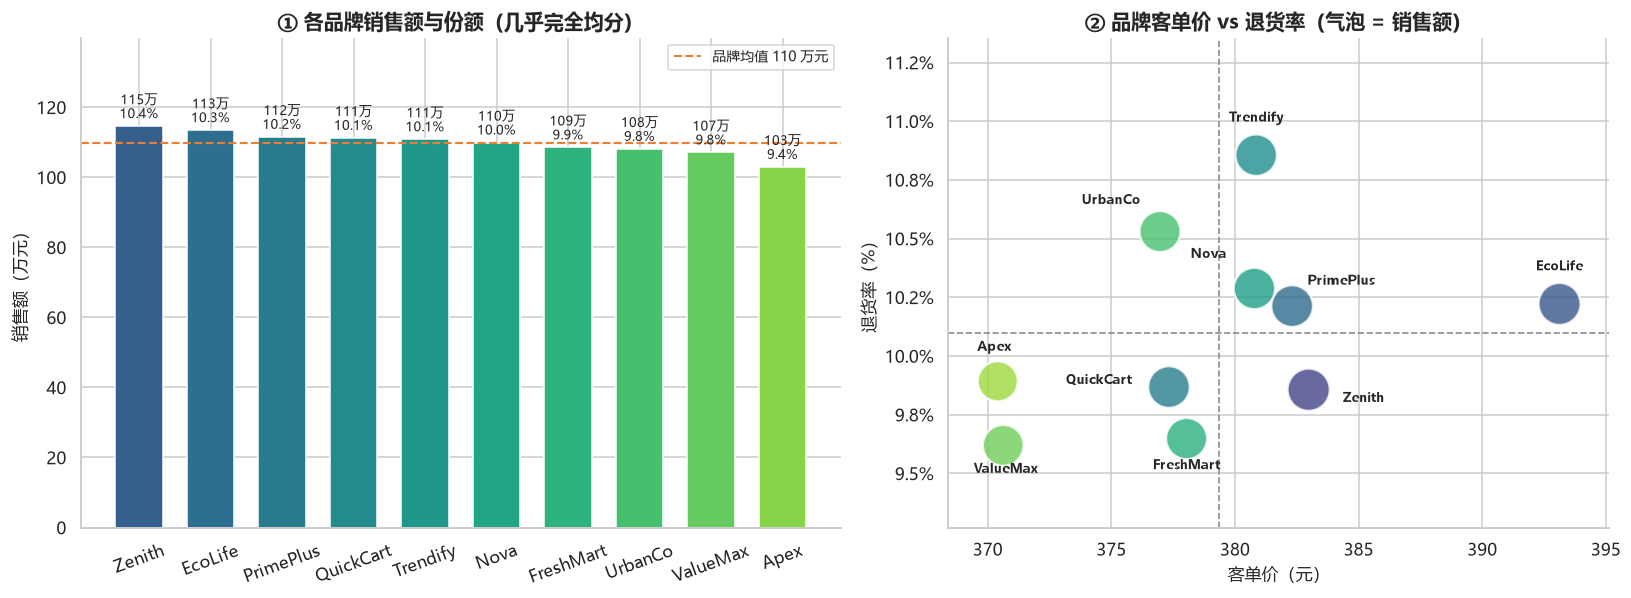

① 品牌数：10 个
② 销售额 Top1 品牌：Zenith，份额 10.44%
③ Top3 品牌合计份额：30.92%
④ 品牌销售额变异系数 CV = 0.031（<0.15 说明高度均衡）
⑤ 客单价区间 370~393 元；退货率区间 9.62%~10.86%
→ 品牌份额最大仅 10.4%、CV=0.031，品牌维度几乎无差异化：属于「同质铺货」结构，品牌不是竞争壁垒，运营重心应放在流量结构与选品效率上。
  相对最需关注：Trendify（退货率 10.86%，均值 10.10%）；最稳健：ValueMax（9.62%）。


In [19]:
brand = (df.groupby("Brand", observed=True)
           .agg(订单数=("Order_ID", "count"),
                销售额=("Order_Amount", "sum"),
                利润=("Profit_Amount", "sum"),
                客单价=("Order_Amount", "mean"),
                退货率=("Returned_Flag", "mean"),
                平均评分=("Review_Rating", "mean"),
                高价值占比=("High_Value_Order_Flag", "mean"))
           .sort_values("销售额", ascending=False))
brand["毛利率"] = brand["利润"] / brand["销售额"] * 100
brand["份额%"] = brand["销售额"] / brand["销售额"].sum() * 100
brand["退货率%"] = brand["退货率"] * 100
brand["高价值占比%"] = brand["高价值占比"] * 100

print("品牌经营全貌：")
display(brand[["订单数", "销售额", "份额%", "毛利率", "客单价", "退货率%", "高价值占比%", "平均评分"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})

# ① 品牌销售额
ax = axes[0]
bars = ax.bar(brand.index, brand["销售额"], color=CMAP(np.linspace(0.3, 0.82, len(brand))), width=0.66)
for b, (v, p) in zip(bars, zip(brand["销售额"], brand["份额%"])):
    ax.annotate(f"{v/1e4:,.0f}万\n{p:.1f}%", (b.get_x() + b.get_width() / 2, v),
                ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")
ax.axhline(brand["销售额"].mean(), color=ACCENT, ls="--", lw=1.4,
           label=f"品牌均值 {brand['销售额'].mean()/1e4:,.0f} 万元")
ax.set_title("① 各品牌销售额与份额（几乎完全均分）")
ax.set_ylabel("销售额（万元）")
ax.set_ylim(0, brand["销售额"].max() * 1.22)
ax.tick_params(axis="x", rotation=20)
money_axis(ax)
ax.legend(fontsize=9)
sns.despine(ax=ax)

# ② 客单价 vs 退货率
ax = axes[1]
ax.scatter(brand["客单价"], brand["退货率%"], s=brand["销售额"] / 1500,
           c=CMAP(np.linspace(0.2, 0.85, len(brand))), alpha=0.8,
           edgecolors="white", linewidths=1.5, zorder=3)
txt_off = {"ValueMax": (2, -18), "Apex": (-2, 20), "FreshMart": (0, -20),
           "QuickCart": (-46, 2), "UrbanCo": (-32, 18), "Nova": (-30, 20),
           "PrimePlus": (32, 14), "Zenith": (36, -8), "Trendify": (0, 22),
           "EcoLife": (0, 22)}
for name, r in brand.iterrows():
    dx, dy = txt_off.get(name, (0, 18))
    ax.annotate(name, (r["客单价"], r["退货率%"]), xytext=(dx, dy), textcoords="offset points",
                ha="center", fontsize=8.5, fontweight="bold", zorder=4)
ax.axhline(brand["退货率%"].mean(), color=GREY, ls="--", lw=1.1)
ax.axvline(brand["客单价"].mean(), color=GREY, ls="--", lw=1.1)
ax.set_xlabel("客单价（元）")
ax.set_ylabel("退货率（%）")
ax.set_title("② 品牌客单价 vs 退货率（气泡 = 销售额）")
ax.set_ylim(brand["退货率%"].min() - 0.35, brand["退货率%"].max() + 0.5)
ax.set_xlim(brand["客单价"].min() - 2.0, brand["客单价"].max() + 2.0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}%"))
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# ---------------- 集中度与均衡度 ----------------
cv = brand["销售额"].std() / brand["销售额"].mean()
print(f"① 品牌数：{len(brand)} 个")
print(f"② 销售额 Top1 品牌：{brand.index[0]}，份额 {brand['份额%'].iloc[0]:.2f}%")
print(f"③ Top3 品牌合计份额：{brand['份额%'].head(3).sum():.2f}%")
print(f"④ 品牌销售额变异系数 CV = {cv:.3f}（<0.15 说明高度均衡）")
print(f"⑤ 客单价区间 {brand['客单价'].min():,.0f}~{brand['客单价'].max():,.0f} 元；"
      f"退货率区间 {brand['退货率%'].min():.2f}%~{brand['退货率%'].max():.2f}%")
print(f"→ 品牌份额最大仅 {brand['份额%'].iloc[0]:.1f}%、CV={cv:.3f}，"
      f"品牌维度几乎无差异化：属于「同质铺货」结构，品牌不是竞争壁垒，"
      f"运营重心应放在流量结构与选品效率上。")
print(f"  相对最需关注：{brand['退货率%'].idxmax()}（退货率 {brand['退货率%'].max():.2f}%，均值 {brand['退货率%'].mean():.2f}%）；"
      f"最稳健：{brand['退货率%'].idxmin()}（{brand['退货率%'].min():.2f}%）。")


## 11. 价格带分析：唯一真正能区分订单质量的维度

前面几章反复出现一个现象：**无论按品牌、人群还是渠道切分，高价值订单（HV）占比都挤在 24%~26% 的窄区间里**，几乎没有区分度。本章换一个切分口径——按 `Price_Level`（低价 / 中价 / 高价，清洗阶段已按客单价三分位生成，三档订单量几乎均分 9648 / 9656 / 9649）。

我们要回答三个问题：

1. 三档价格带各自贡献了多少订单、多少销售额？——判断"量"与"钱"是否错配。
2. 客单价、毛利率、评分、退货率随价格带如何变化？——判断涨价是否有代价。
3. **高价值订单占比是否随价格带单调上升？**——这是验证"价格带才是 HV 的真正驱动因素"的关键证据。

如果第 3 问得到显著的单调递增结论，那么后续所有"提升客单价"的运营动作，都应该围绕**把用户往更高价格带推**，而不是在人群中挑客户。


价格带经营全貌：


,订单数,订单占比%,销售额,销售额占比%,客单价,件单价,毛利率,平均折扣率,退货率%,高价值占比%,平均评分
Price_Level,,,,,,,,,,,
低价,9648,33.32,"2,205,106.31",20.07,228.56,75.36,19.54,12.57,9.74,15.43,4.04
中价,9656,33.35,"3,351,838.42",30.51,347.12,114.89,19.70,12.54,10.33,23.20,4.04
高价,9649,33.33,"5,427,606.05",49.41,562.50,183.13,19.39,12.67,10.23,36.68,4.05


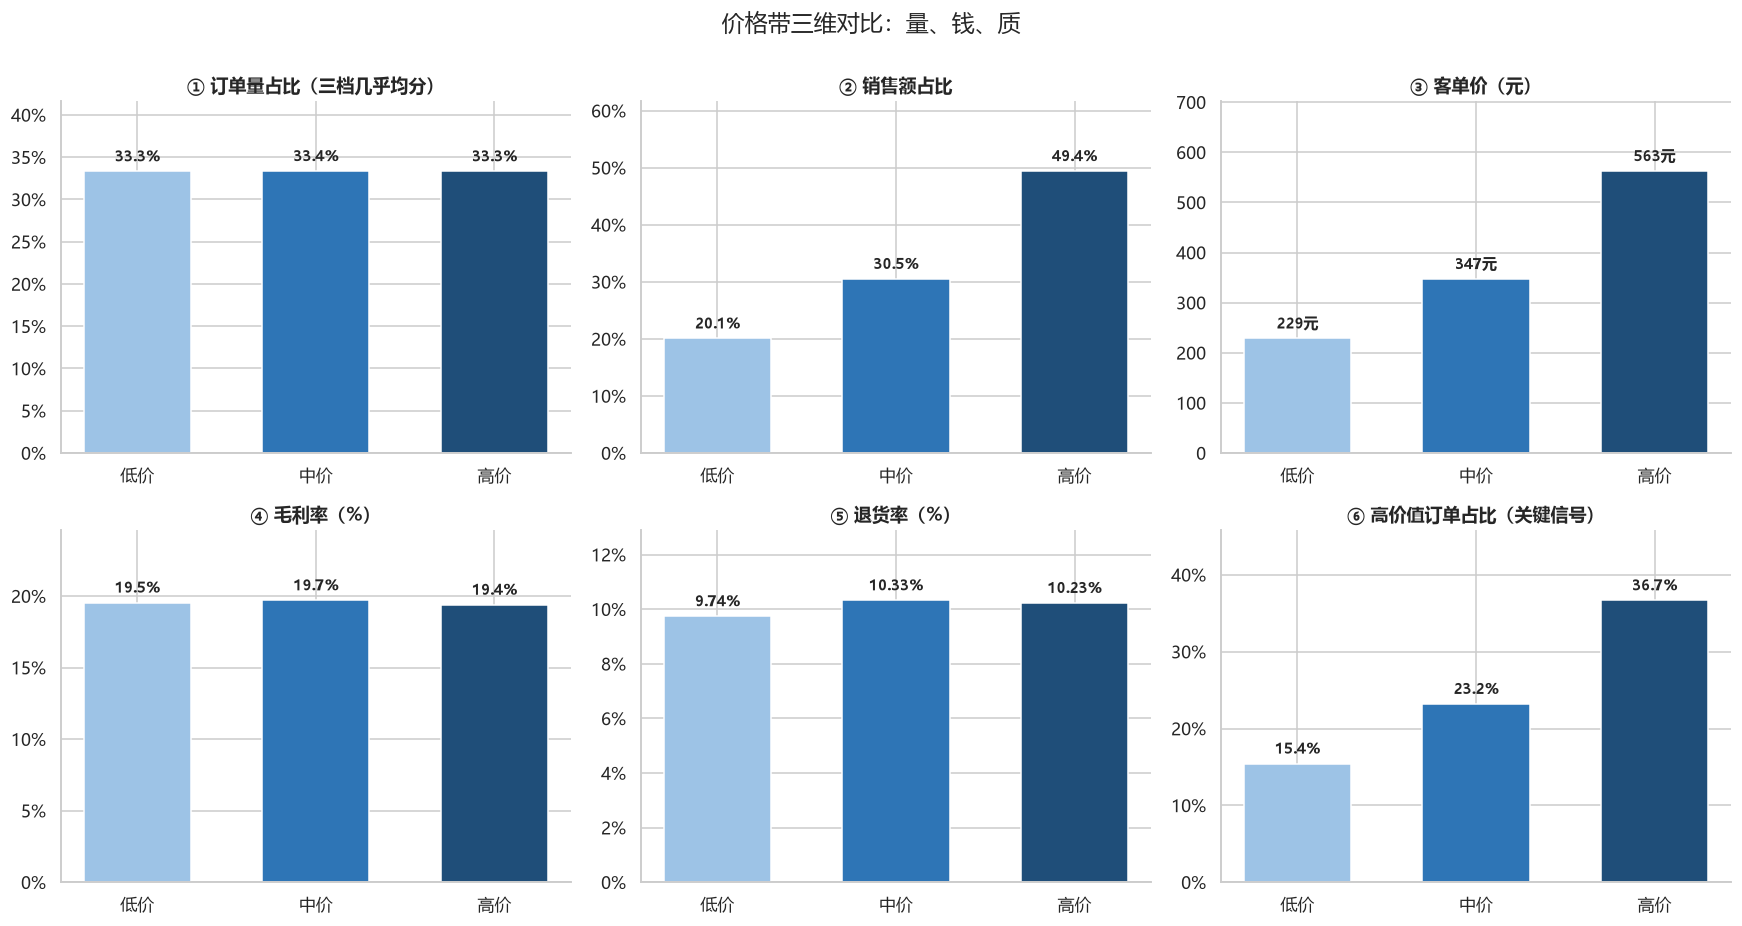

① 高价值订单占比：低价 15.43% → 中价 23.20% → 高价 36.68%
② 最高/最低倍数：2.38 倍（对比人群维度普遍 1.05 倍以内）
③ 客单价跨度 229 → 563 元，高价带是低价带的 2.46 倍
④ 毛利率：19.39% ~ 19.70%，价格带间差异仅 0.31 个百分点
⑤ 退货率：9.74% ~ 10.33%，平均评分 4.04~4.05
→ 结论：价格带是全部切分维度中唯一具有强区分力的变量——高价值订单占比随价格带单调上升且跨度达 2 倍以上；同时毛利率、退货率、评分几乎不随价格带恶化。这意味着「提升客单价」是提升订单质量最直接、且几乎无副作用的杠杆。


In [20]:
band = (df.groupby("Price_Level", observed=True)
          .agg(订单数=("Order_ID", "count"),
               销售额=("Order_Amount", "sum"),
               利润=("Profit_Amount", "sum"),
               客单价=("Order_Amount", "mean"),
               件单价=("Amount_Per_Item", "mean"),
               平均折扣率=("Actual_Discount_Rate(%)", "mean"),
               退货率=("Returned_Flag", "mean"),
               平均评分=("Review_Rating", "mean"),
               高价值占比=("High_Value_Order_Flag", "mean"))
          .reindex(["低价", "中价", "高价"]))
band["订单占比%"] = band["订单数"] / band["订单数"].sum() * 100
band["销售额占比%"] = band["销售额"] / band["销售额"].sum() * 100
band["毛利率"] = band["利润"] / band["销售额"] * 100
band["高价值占比%"] = band["高价值占比"] * 100
band["退货率%"] = band["退货率"] * 100

print("价格带经营全貌：")
display(band[["订单数", "订单占比%", "销售额", "销售额占比%", "客单价", "件单价",
              "毛利率", "平均折扣率", "退货率%", "高价值占比%", "平均评分"]].round(2))

BAND_COLORS = ["#9DC3E6", "#2E75B6", "#1F4E79"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
axes = axes.ravel()
labels = band.index.tolist()

def panel(ax, col, title, fmt, pct=False, ylim_pad=1.25, note_fmt=None):
    vals = band[col].values
    bars = ax.bar(labels, vals, color=BAND_COLORS, width=0.6)
    top = max(vals)
    for b, v in zip(bars, vals):
        txt = note_fmt(v) if note_fmt else fmt.format(v)
        ax.annotate(txt, (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                    fontsize=10, fontweight="bold", xytext=(0, 4), textcoords="offset points")
    ax.set_title(title, fontsize=12)
    ax.set_ylim(0, top * ylim_pad)
    if pct:
        pct_axis(ax)
    sns.despine(ax=ax)

panel(axes[0], "订单占比%", "① 订单量占比（三档几乎均分）", "{:.1f}%", pct=True)
panel(axes[1], "销售额占比%", "② 销售额占比", "{:.1f}%", pct=True)
panel(axes[2], "客单价", "③ 客单价（元）", "{:,.0f}", note_fmt=lambda v: f"{v:,.0f}元")
panel(axes[3], "毛利率", "④ 毛利率（%）", "{:.1f}%", pct=True)
panel(axes[4], "退货率%", "⑤ 退货率（%）", "{:.2f}%", pct=True)
panel(axes[5], "高价值占比%", "⑥ 高价值订单占比（关键信号）", "{:.1f}%", pct=True)

plt.suptitle("价格带三维对比：量、钱、质", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

# ---------------- 单调性与驱动强度 ----------------
hv = band["高价值占比%"]
ratio_span = hv.max() / hv.min()
print(f"① 高价值订单占比：低价 {hv['低价']:.2f}% → 中价 {hv['中价']:.2f}% → 高价 {hv['高价']:.2f}%")
print(f"② 最高/最低倍数：{ratio_span:.2f} 倍（对比人群维度普遍 1.05 倍以内）")
print(f"③ 客单价跨度 {band['客单价'].min():,.0f} → {band['客单价'].max():,.0f} 元，"
      f"高价带是低价带的 {band['客单价'].max()/band['客单价'].min():.2f} 倍")
print(f"④ 毛利率：{band['毛利率'].min():.2f}% ~ {band['毛利率'].max():.2f}%，"
      f"价格带间差异仅 {band['毛利率'].max()-band['毛利率'].min():.2f} 个百分点")
print(f"⑤ 退货率：{band['退货率%'].min():.2f}% ~ {band['退货率%'].max():.2f}%，"
      f"平均评分 {band['平均评分'].min():.2f}~{band['平均评分'].max():.2f}")
print("→ 结论：价格带是全部切分维度中唯一具有强区分力的变量——"
      "高价值订单占比随价格带单调上升且跨度达 2 倍以上；"
      "同时毛利率、退货率、评分几乎不随价格带恶化。"
      "这意味着「提升客单价」是提升订单质量最直接、且几乎无副作用的杠杆。")


## 12. 大额订单画像（一）：人群维度

「大额订单（High Value Order，HV）」在清洗阶段的定义是**订单金额位于全体订单的上四分位以上**，这类订单只占 **25.1% 的量，却贡献了 71.49% 的销售额**——所以"谁在下大额订单"直接决定收入结构。

本章从 4 个**人群标签**切入：

| 维度 | 字段 | 想验证的假设 |
|---|---|---|
| 年龄段 | `Age_Group` | 是否中年人更有购买力？ |
| 性别 | `Customer_Gender` | 男女消费力是否有差异？ |
| 客户分层 | `Customer_Segment` | 高等级客户是否更常下大额单？ |
| 会员状态 | `Membership_Status` | 会员是否显著优于非会员？ |

判定标准：比较各分组内 **HV 订单占比**与全盘基准线（约 25.1%）的偏离幅度。如果某一维度内各分组的 HV 占比都贴着基准线波动，说明**该维度对大额订单没有解释力**，运营上就不必针对它做差异化投放。


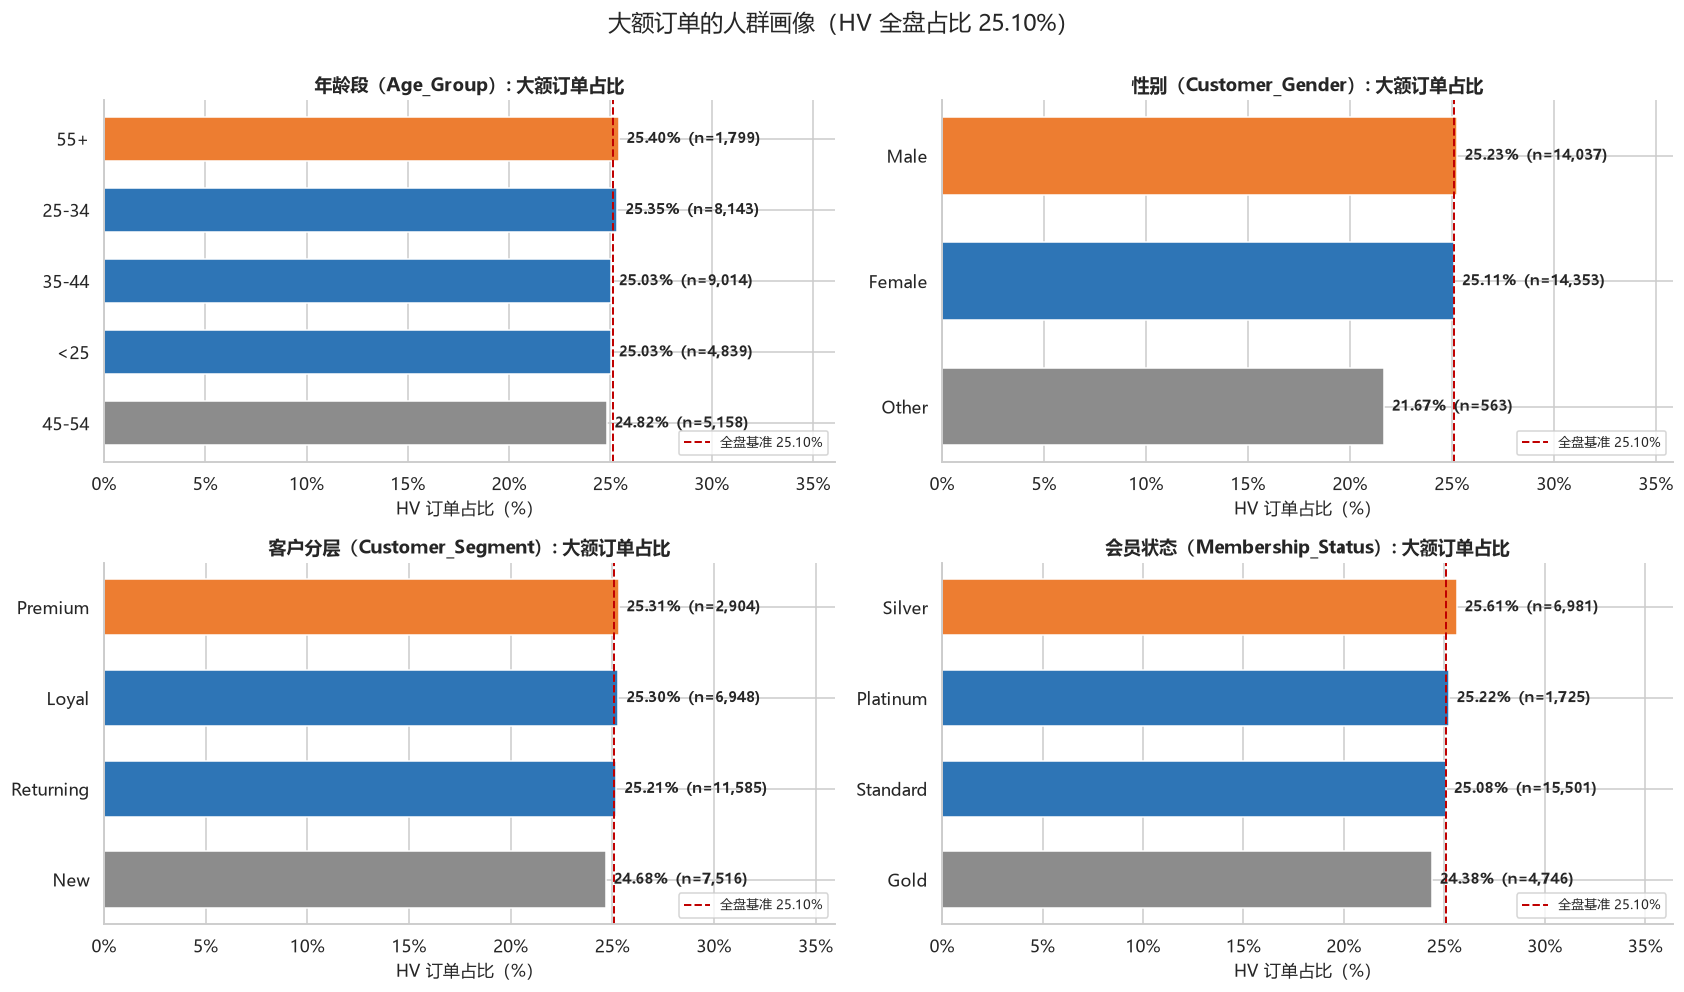

各人群维度的区分力对比：


,维度,分组数,HV占比最低,HV占比最高,极差(pp),变异系数
1,性别,3,21.67%（Other）,25.23%（Male）,3.56,0.08
3,会员状态,4,24.38%（Gold）,25.61%（Silver）,1.23,0.02
2,客户分层,4,24.68%（New）,25.31%（Premium）,0.63,0.01
0,年龄段,5,24.82%（45-54）,25.40%（55+）,0.59,0.01


→ 4 个人群维度的 HV 占比极差全部 ≤ 3.56 个百分点，最大变异系数仅 0.0843。
→ 结论：年龄段、性别、客户分层、会员状态对大额订单**几乎没有解释力**，各分组占比都紧贴基准线。大额订单不是「某类人」专属，因此人群定向投放收效甚微，应转向价格带与品类结构（第 11、13 章）。


In [21]:
BASE_HV = df["High_Value_Order_Flag"].mean() * 100          # 全盘 HV 占比基准线
DIMS = [("Age_Group", "年龄段"), ("Customer_Gender", "性别"),
        ("Customer_Segment", "客户分层"), ("Membership_Status", "会员状态")]

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9))
span_rows = []

for ax, (dim, cn) in zip(axes.ravel(), DIMS):
    g = (df.groupby(dim, observed=True)
           .agg(订单数=("Order_ID", "count"), HV=("High_Value_Order_Flag", "mean"))
           .rename(columns={"HV": "HV占比"}))
    g["HV占比%"] = g["HV占比"] * 100
    g = g.sort_values("HV占比%")

    colors = [ACCENT if v == g["HV占比%"].max() else
              (GREY if v == g["HV占比%"].min() else MAIN) for v in g["HV占比%"]]
    bars = ax.barh(g.index.astype(str), g["HV占比%"], color=colors, height=0.62)
    for b, (v, n) in zip(bars, zip(g["HV占比%"], g["订单数"])):
        ax.annotate(f"{v:.2f}%  (n={n:,})", (v, b.get_y() + b.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points", va="center",
                    fontsize=9.5, fontweight="bold")
    ax.axvline(BASE_HV, color="#C00000", ls="--", lw=1.3,
               label=f"全盘基准 {BASE_HV:.2f}%")
    ax.set_xlim(0, g["HV占比%"].max() * 1.42)
    ax.set_xlabel("HV 订单占比（%）")
    ax.set_title(f"{cn}（{dim}）: 大额订单占比", fontsize=12)
    pct_axis(ax, axis="x")
    ax.legend(fontsize=8.5, loc="lower right")
    sns.despine(ax=ax)

    span_rows.append({"维度": cn,
                      "分组数": len(g),
                      "HV占比最低": f"{g['HV占比%'].min():.2f}%（{g.index[0]}）",
                      "HV占比最高": f"{g['HV占比%'].max():.2f}%（{g.index[-1]}）",
                      "极差(pp)": round(g["HV占比%"].max() - g["HV占比%"].min(), 2),
                      "变异系数": round(g["HV占比%"].std() / g["HV占比%"].mean(), 4)})

plt.suptitle(f"大额订单的人群画像（HV 全盘占比 {BASE_HV:.2f}%）", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

span = pd.DataFrame(span_rows).sort_values("极差(pp)", ascending=False)
print("各人群维度的区分力对比：")
display(span)
print(f"→ 4 个人群维度的 HV 占比极差全部 ≤ {span['极差(pp)'].max():.2f} 个百分点，"
      f"最大变异系数仅 {span['变异系数'].max():.4f}。")
print("→ 结论：年龄段、性别、客户分层、会员状态对大额订单**几乎没有解释力**，"
      "各分组占比都紧贴基准线。大额订单不是「某类人」专属，"
      "因此人群定向投放收效甚微，应转向价格带与品类结构（第 11、13 章）。")


## 13. 大额订单画像（二）：渠道与行为维度

上一章证明"人群"这条线走不通，本章把镜头切到**订单发生时的渠道与行为属性**，共 6 个维度：

| 维度 | 字段 | 判定它是否有用的信号 |
|---|---|---|
| 设备 | `Device_Type` | 高端设备用户是否客单更高？ |
| 流量来源 | `Traffic_Source` | 付费流量带来的订单质量是否更差？ |
| 支付方式 | `Payment_Method` | 分期/信用卡是否对应大额？ |
| 配送方式 | `Shipping_Method` | 次日达用户是否更愿花钱？ |
| 是否周末 | `Is_Weekend` | 周末消费是否更"大方"？ |
| **商品品类** | `Product_Category` | 品类结构是否才是真正的答案？ |

沿用同一把尺子：看各组 **HV 订单占比**相对全盘基准的偏离。预期前 5 个维度仍是"贴线"，而最后一个维度会**拉开数量级差异**——这将与前两章形成完整的三重对照（人群 × 渠道 × 品类），直接指向"卖什么"比"卖给谁、从哪来"更重要。


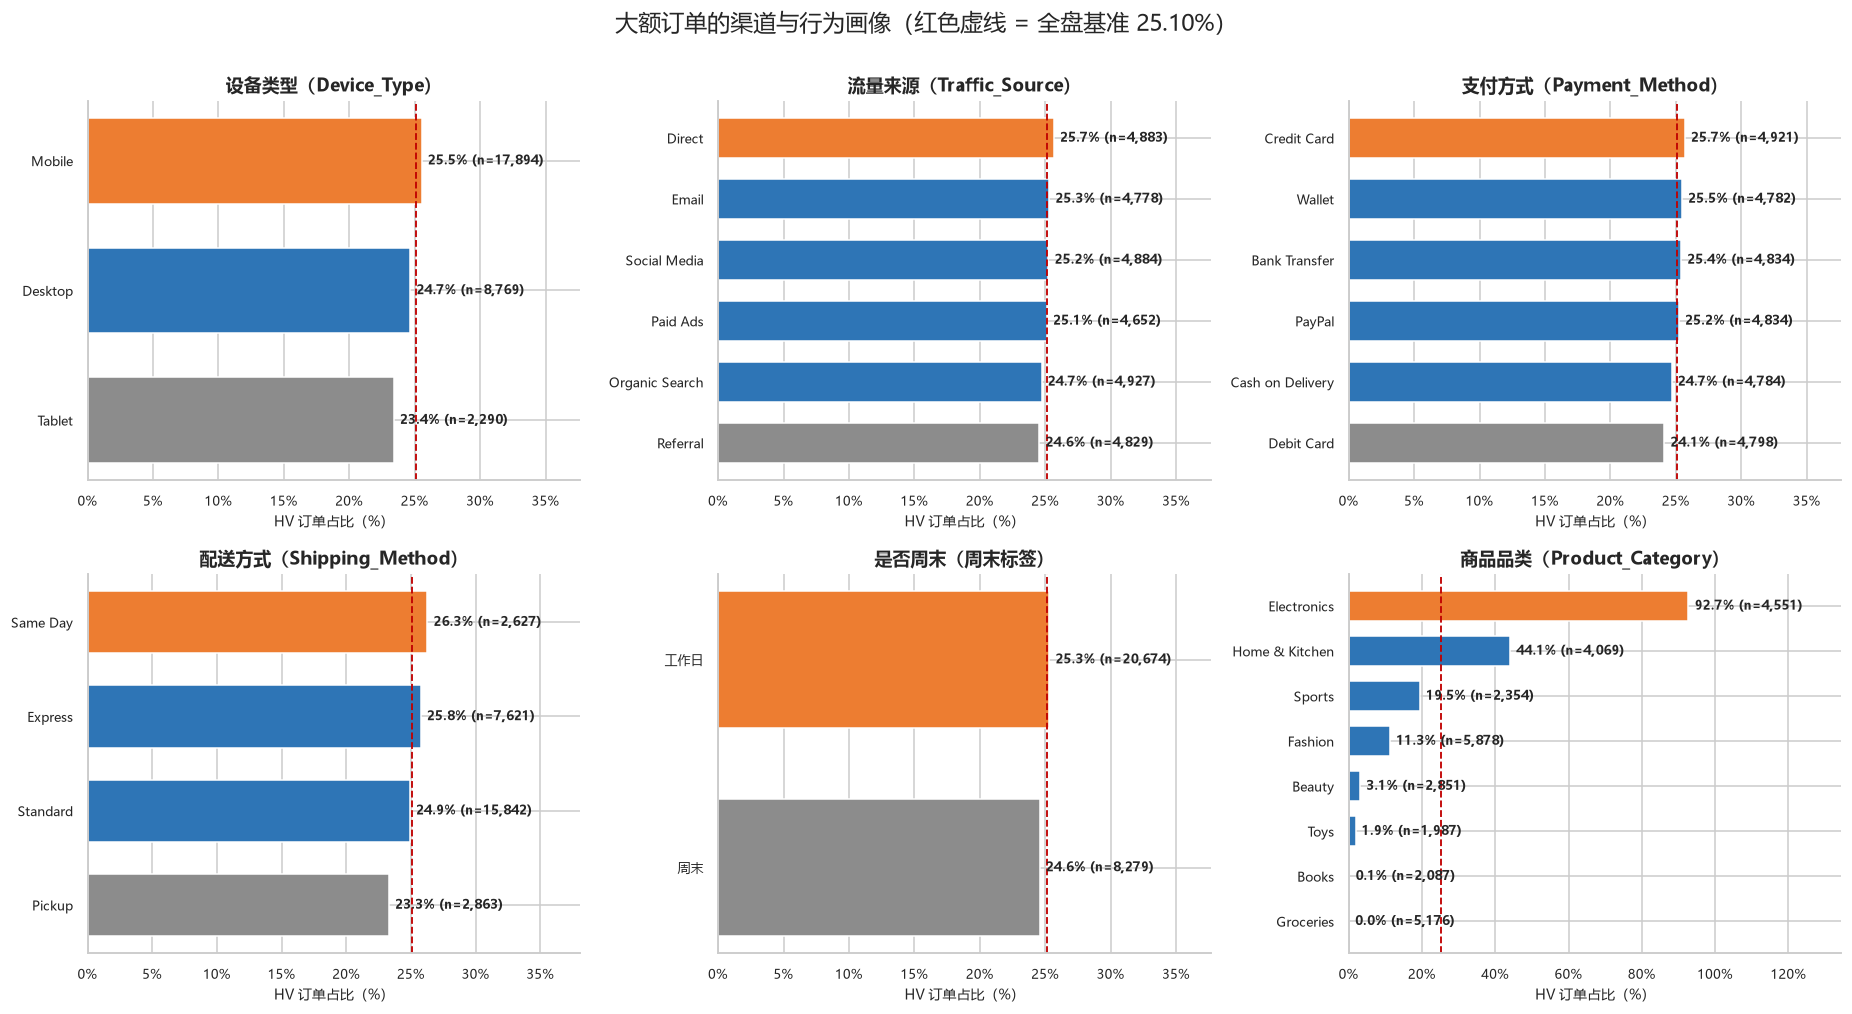

各渠道/行为维度的区分力排序：


,维度,分组数,HV最低,HV最高,极差(pp),最高组,最低组
5,商品品类,8,0.00,92.73,92.73,Electronics,Groceries
3,配送方式,4,23.30,26.27,2.97,Same Day,Pickup
0,设备类型,3,23.41,25.53,2.13,Mobile,Tablet
2,支付方式,6,24.11,25.69,1.57,Credit Card,Debit Card
1,流量来源,6,24.56,25.66,1.10,Direct,Referral
4,是否周末,2,24.58,25.31,0.73,工作日,周末


→ 关键反差：商品品类的 HV 占比极差 92.73 个百分点（Groceries 0.00% → Electronics 92.73%），是其余 5 个渠道维度极差之和的 10.9 倍。
→ 结论：设备、流量来源、支付方式、配送方式、周末与否同样不具备解释力；大额订单的真正来源是「品类结构」—— Electronics 类订单几乎天然就是大额单。运营结论：与其做人群/渠道精细化，不如做「高单价品类曝光 + 低单价品类搭售提客单」。


In [22]:
df["周末标签"] = np.where(df["Is_Weekend"] == 1, "周末", "工作日")

DIMS2 = [("Device_Type", "设备类型"), ("Traffic_Source", "流量来源"),
         ("Payment_Method", "支付方式"), ("Shipping_Method", "配送方式"),
         ("周末标签", "是否周末"), ("Product_Category", "商品品类")]

fig, axes = plt.subplots(2, 3, figsize=(17, 9.2))
span2 = []

for ax, (dim, cn) in zip(axes.ravel(), DIMS2):
    g = (df.groupby(dim, observed=True)
           .agg(订单数=("Order_ID", "count"), HV=("High_Value_Order_Flag", "mean")))
    g["HV占比%"] = g["HV"] * 100
    g = g.sort_values("HV占比%")

    colors = [ACCENT if v == g["HV占比%"].max() else
              (GREY if v == g["HV占比%"].min() else MAIN) for v in g["HV占比%"]]
    bars = ax.barh(g.index.astype(str), g["HV占比%"], color=colors, height=0.66)
    for b, (v, n) in zip(bars, zip(g["HV占比%"], g["订单数"])):
        ax.annotate(f"{v:.1f}% (n={n:,})", (v, b.get_y() + b.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center",
                    fontsize=8.8, fontweight="bold")
    ax.axvline(BASE_HV, color="#C00000", ls="--", lw=1.2)
    ax.set_xlim(0, max(g["HV占比%"].max() * 1.45, BASE_HV * 1.5))
    ax.set_title(f"{cn}（{dim}）", fontsize=11.5)
    ax.set_xlabel("HV 订单占比（%）", fontsize=9)
    ax.tick_params(labelsize=8.8)
    pct_axis(ax, axis="x")
    sns.despine(ax=ax)

    span2.append({"维度": cn, "分组数": len(g),
                  "HV最低": g["HV占比%"].min(), "HV最高": g["HV占比%"].max(),
                  "极差(pp)": round(g["HV占比%"].max() - g["HV占比%"].min(), 2),
                  "最高组": g.index[-1], "最低组": g.index[0]})

plt.suptitle(f"大额订单的渠道与行为画像（红色虚线 = 全盘基准 {BASE_HV:.2f}%）", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

s2 = pd.DataFrame(span2).sort_values("极差(pp)", ascending=False)
print("各渠道/行为维度的区分力排序：")
display(s2.round(2))

cat_span = s2[s2["维度"] == "商品品类"].iloc[0]
print(f"→ 关键反差：商品品类的 HV 占比极差 {cat_span['极差(pp)']:.2f} 个百分点"
      f"（{cat_span['最低组']} {cat_span['HV最低']:.2f}% → {cat_span['最高组']} {cat_span['HV最高']:.2f}%），"
      f"是其余 5 个渠道维度极差之和的 {cat_span['极差(pp)'] / s2[s2['维度'] != '商品品类']['极差(pp)'].sum():.1f} 倍。")
print("→ 结论：设备、流量来源、支付方式、配送方式、周末与否同样不具备解释力；"
      "大额订单的真正来源是「品类结构」—— Electronics 类订单几乎天然就是大额单。"
      "运营结论：与其做人群/渠道精细化，不如做「高单价品类曝光 + 低单价品类搭售提客单」。")


## 14. 订单金额分布与"二八法则"验证

前三章都在做"分组比较"，本章回到**单变量分布本身**，回答两个基础问题：

1. **订单金额是怎么分布的？** 电商金额通常呈严重右偏（长尾），若直接看均值会严重误判。用**对数横轴直方图**可以同时看清主体区（300~500 元）和长尾区（数千元）。
2. **收入是否高度集中？** 用**洛伦兹曲线（Lorenz Curve）**刻画"订单份额 → 销售额份额"的累计关系，并用**基尼系数（Gini）**量化不平等程度。对角线代表绝对平均；曲线越向下弯、基尼系数越大，说明收入越依赖少数大额订单。

洛伦兹曲线的读法：横轴是"从最小单开始累计的订单占比"，纵轴是"对应的销售额累计占比"。若 20% 的订单（从大到小看）贡献了 60% 的销售额，则曲线上 (0.8, 0.4) 附近会出现明显拐点。本章会直接标注出"贡献 80% 销售额需要多少比例的订单"这一关键运营数字。


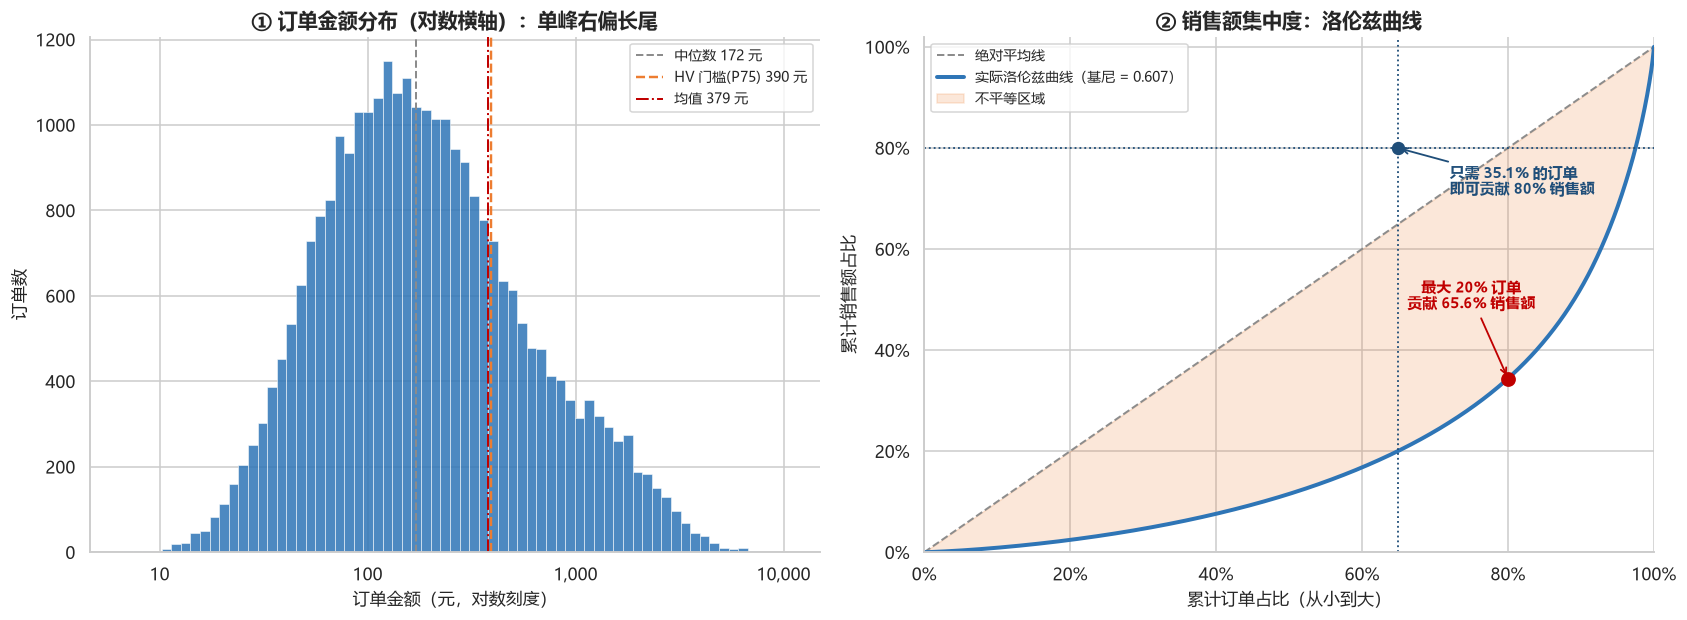

① 订单数 28,953；金额均值 379.39 元 > 中位数 171.77 元，右偏明显
   P75 = 389.83 元
   P90 = 950.27 元
   P95 = 1,540.49 元
   P99 = 2,906.22 元
② HV 门槛（P75）= 389.83 元，超过该值即为大额订单，共 7,238 单（占 25.0%）
③ 基尼系数 = 0.607；最大的 20% 订单贡献 65.63% 销售额
④ 只需 35.1% 的订单（10,164 单）就贡献了 80% 的销售额
→ 结论：订单金额高度集中（基尼 0.607），收入命脉掌握在四分之一的大额订单手里；任何一个能提高大额订单占比的小改动（价格带、品类结构、搭售），对总销售额的杠杆效应都远大于等量地提升长尾小单。


In [24]:
amt = df["Order_Amount"].astype(float).values
amt_sorted = np.sort(amt)
n = len(amt)

p50, p75, p90, p95, p99 = np.percentile(amt, [50, 75, 90, 95, 99])
hv_thr = p75                      # 清洗阶段 HV 订单即"金额 > 上四分位"
# 洛伦兹累计（从小到大）
cum_amt = np.cumsum(amt_sorted) / amt_sorted.sum()
cum_pop = np.arange(1, n + 1) / n
# 基尼系数
gini = 1 - 2 * np.trapezoid(cum_amt, cum_pop)

# 从大到小累计：最大的 k 单贡献多少销售额
cum_desc = np.cumsum(amt_sorted[::-1]) / amt_sorted.sum()
top20_share = cum_desc[int(0.20 * n) - 1] * 100          # 最大 20% 订单贡献
k80 = int(np.searchsorted(cum_desc, 0.80)) + 1
pct80 = k80 / n * 100                                     # 贡献 80% 销售额所需订单比例

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))

# ① 对数横轴金额分布
ax = axes[0]
bins = np.logspace(np.log10(amt.min()), np.log10(amt.max()), 70)
ax.hist(amt, bins=bins, color=MAIN, alpha=0.85, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.axvline(p50, color=GREY, ls="--", lw=1.3, label=f"中位数 {p50:,.0f} 元")
ax.axvline(hv_thr, color=ACCENT, ls="--", lw=1.6, label=f"HV 门槛(P75) {hv_thr:,.0f} 元")
ax.axvline(amt.mean(), color="#C00000", ls="-.", lw=1.3, label=f"均值 {amt.mean():,.0f} 元")
ax.set_xlabel("订单金额（元，对数刻度）")
ax.set_ylabel("订单数")
ax.set_title("① 订单金额分布（对数横轴）：单峰右偏长尾")
ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
sns.despine(ax=ax)

# ② 洛伦兹曲线
ax = axes[1]
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1.3, label="绝对平均线")
ax.plot(cum_pop, cum_amt, color=MAIN, lw=2.6, label=f"实际洛伦兹曲线（基尼 = {gini:.3f}）")
ax.fill_between(cum_pop, cum_amt, cum_pop, color=ACCENT, alpha=0.18, label="不平等区域")
ax.scatter([1 - 0.20], [1 - top20_share / 100], s=75, color="#C00000", zorder=5)
ax.annotate(f"最大 20% 订单\n贡献 {top20_share:.1f}% 销售额",
            (1 - 0.20, 1 - top20_share / 100), xytext=(-24, 46), textcoords="offset points",
            fontsize=9.5, fontweight="bold", ha="center", color="#C00000",
            arrowprops=dict(arrowstyle="->", color="#C00000", lw=1.2))
ax.axhline(0.8, color="#1F4E79", ls=":", lw=1.2)
ax.axvline(1 - pct80 / 100, color="#1F4E79", ls=":", lw=1.2)
ax.scatter([1 - pct80 / 100], [0.8], s=60, color="#1F4E79", zorder=5)
ax.annotate(f"只需 {pct80:.1f}% 的订单\n即可贡献 80% 销售额",
            (1 - pct80 / 100, 0.8), xytext=(34, -30), textcoords="offset points",
            fontsize=9.5, fontweight="bold", color="#1F4E79",
            arrowprops=dict(arrowstyle="->", color="#1F4E79", lw=1.2))
ax.set_xlabel("累计订单占比（从小到大）")
ax.set_ylabel("累计销售额占比")
ax.set_title("② 销售额集中度：洛伦兹曲线")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(fontsize=9, loc="upper left")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"① 订单数 {n:,}；金额均值 {amt.mean():,.2f} 元 > 中位数 {p50:,.2f} 元，右偏明显")
for q, v in [("P75", p75), ("P90", p90), ("P95", p95), ("P99", p99)]:
    print(f"   {q} = {v:,.2f} 元")
print(f"② HV 门槛（P75）= {hv_thr:,.2f} 元，超过该值即为大额订单，共 {(amt > hv_thr).sum():,} 单"
      f"（占 {(amt > hv_thr).mean()*100:.1f}%）")
print(f"③ 基尼系数 = {gini:.3f}；最大的 20% 订单贡献 {top20_share:.2f}% 销售额")
print(f"④ 只需 {pct80:.1f}% 的订单（{k80:,} 单）就贡献了 80% 的销售额")
print("→ 结论：订单金额高度集中（基尼 0.607），收入命脉掌握在四分之一的大额订单手里；"
      "任何一个能提高大额订单占比的小改动（价格带、品类结构、搭售），"
      "对总销售额的杠杆效应都远大于等量地提升长尾小单。")


## 15. 大额订单的驱动因素：到底是什么把金额推高了

前面已经确认"品类 > 渠道 > 人群"，本章进一步量化**数值型字段**对订单金额的贡献。方法是用皮尔逊相关系数量化每个候选变量与 `Order_Amount` 的线性关联强度。

需要注意一个陷阱：`Tax_Amount`、`Profit_Amount`、`Gross_Amount`、`Discount_Amount` 都是**从订单金额派生出来的字段**（金额高→税高→利润高），它们与 `Order_Amount` 的高相关是恒等式造成的，**没有因果意义**，在图中会用灰色标出并单独说明。

真正有意义的问题是：

- **`Unit_Price`（件单价）还是 `Quantity`（件数）在驱动金额？** 这直接决定运营策略是"卖贵的"还是"多卖几件"。
- `Customer_Lifetime_Value`（CLV）与金额的相关性，能否作为大额订单的**预判指标**？
- `Discount_Percent`、`Delivery_Days`、`Review_Rating` 与金额是正相关还是负相关？

右侧散点图把 `Unit_Price` 与 `Quantity` 放在同一张图上，用颜色区分大额/普通订单，可以直观看出大额订单集中在"高价 × 少件"还是"低价 × 多件"的区域。


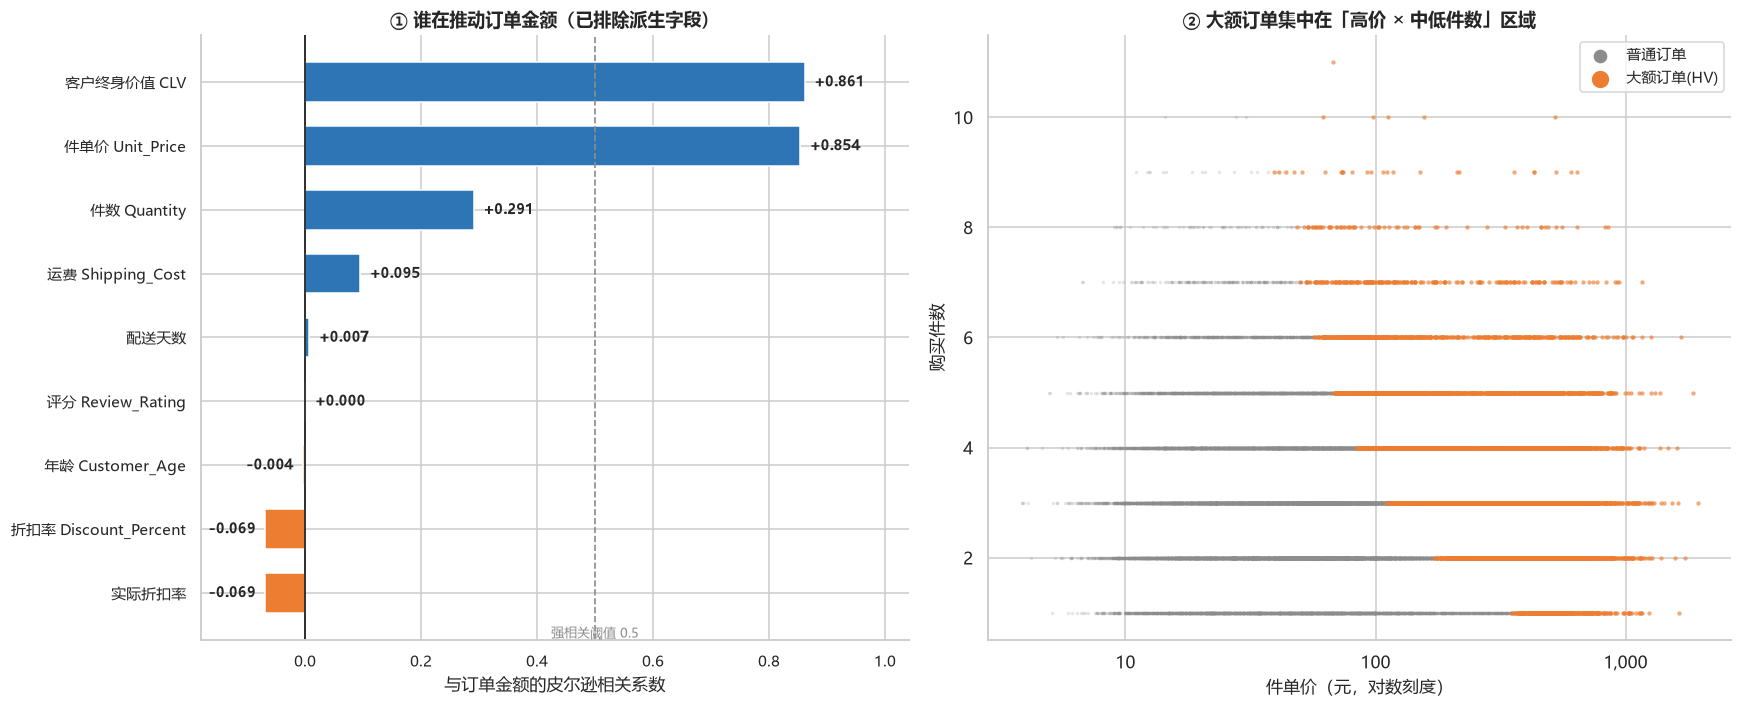

派生字段（与金额高相关但属于恒等式，无因果意义）：
   Net_Item_Amount +0.999、Gross_Amount +0.990、Order_Amount_Winsor +0.975、Tax_Amount +0.926、Profit_Amount +0.856、Profit_Amount_Winsor +0.850、Discount_Amount +0.592

真实候选驱动因素排序（|r| 降序）：
   Customer_Lifetime_Value     +0.861
   Unit_Price                  +0.854
   Quantity                    +0.291
   Shipping_Cost               +0.095
   Actual_Discount_Rate(%)     -0.069
   Discount_Percent            -0.069
   Delivery_Days               +0.007
   Customer_Age                -0.004
   Review_Rating               +0.000

① 大额订单件单价中位数 288.8 元 vs 普通订单 43.7 元，相差 6.61 倍
② 大额订单平均件数 3.68 件 vs 普通订单 2.88 件，几乎无差别
③ Unit_Price 相关性 +0.854 是 Quantity +0.291 的 2.9 倍——金额由「单价」驱动，不是由「件数」驱动
④ CLV 相关性 +0.861 最高，但它不是可操作变量：CLV 是客户级属性，可作为大额订单的「事前预判标签」，不能靠运营直接改变
→ 结论：大额订单 = 买贵的，而不是买多的。提升客单价的核心是**商品结构升级**（引入高价 SKU、提高高价品类曝光），而不是满减凑单式的「多买几件」；同时可用 CLV 高分人群做精准的大额商品推荐。


In [26]:
LEAKY = ["Tax_Amount", "Profit_Amount", "Gross_Amount", "Discount_Amount",
         "Net_Item_Amount", "Order_Amount_Winsor", "Profit_Amount_Winsor"]
CAND = ["Unit_Price", "Quantity", "Shipping_Cost", "Customer_Lifetime_Value",
        "Discount_Percent", "Actual_Discount_Rate(%)", "Delivery_Days",
        "Review_Rating", "Customer_Age"]
CN = {"Unit_Price": "件单价 Unit_Price", "Quantity": "件数 Quantity",
      "Shipping_Cost": "运费 Shipping_Cost",
      "Customer_Lifetime_Value": "客户终身价值 CLV",
      "Discount_Percent": "折扣率 Discount_Percent",
      "Actual_Discount_Rate(%)": "实际折扣率", "Delivery_Days": "配送天数",
      "Review_Rating": "评分 Review_Rating", "Customer_Age": "年龄 Customer_Age"}

corr_leak = df[LEAKY].corrwith(df["Order_Amount"]).sort_values(ascending=False)
corr_main = df[CAND].corrwith(df["Order_Amount"]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.6), gridspec_kw={"width_ratios": [1, 1.05]})

# ① 相关系数条形图（真实驱动因素）
ax = axes[0]
corr_plot = corr_main.rename(index=CN)
colors = [MAIN if v >= 0 else ACCENT for v in corr_plot.values]
bars = ax.barh(corr_plot.index, corr_plot.values, color=colors, height=0.62)
for b, v in zip(bars, corr_plot.values):
    ax.annotate(f"{v:+.3f}", (v, b.get_y() + b.get_height() / 2),
                xytext=(6 if v >= 0 else -6, 0), textcoords="offset points",
                va="center", ha="left" if v >= 0 else "right",
                fontsize=10, fontweight="bold")
ax.axvline(0, color="black", lw=1)
ax.axvline(0.5, color=GREY, ls="--", lw=1.1)
ax.annotate("强相关阈值 0.5", (0.5, -0.7), fontsize=8.5, color=GREY, ha="center")
ax.set_xlim(min(-0.18, corr_main.min() * 1.4), corr_main.max() + 0.18)
ax.set_xlabel("与订单金额的皮尔逊相关系数")
ax.set_title("① 谁在推动订单金额（已排除派生字段）", fontsize=12)
ax.tick_params(labelsize=9.5)
sns.despine(ax=ax)

# ② 件单价 × 件数 散点，颜色区分大额订单
ax = axes[1]
hv = df["High_Value_Order_Flag"] == 1
ax.scatter(df.loc[~hv, "Unit_Price"], df.loc[~hv, "Quantity"], s=5, alpha=0.22,
           color=GREY, label="普通订单", linewidths=0)
ax.scatter(df.loc[hv, "Unit_Price"], df.loc[hv, "Quantity"], s=8, alpha=0.65,
           color=ACCENT, label="大额订单(HV)", linewidths=0)
ax.set_xscale("log")
ax.set_xlabel("件单价（元，对数刻度）")
ax.set_ylabel("购买件数")
ax.set_title("② 大额订单集中在「高价 × 中低件数」区域", fontsize=12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
leg = ax.legend(fontsize=9.5, markerscale=4, loc="upper right")
for lh in leg.legend_handles:
    lh.set_alpha(1)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print("派生字段（与金额高相关但属于恒等式，无因果意义）：")
print("   " + "、".join(f"{k} {v:+.3f}" for k, v in corr_leak.items()))
print("\n真实候选驱动因素排序（|r| 降序）：")
for k, v in corr_main.sort_values(key=np.abs, ascending=False).items():
    print(f"   {k:<28}{v:+.3f}")

qty_hv = df.loc[hv, "Quantity"].mean()
qty_no = df.loc[~hv, "Quantity"].mean()
up_hv = df.loc[hv, "Unit_Price"].median()
up_no = df.loc[~hv, "Unit_Price"].median()
print(f"\n① 大额订单件单价中位数 {up_hv:,.1f} 元 vs 普通订单 {up_no:,.1f} 元，"
      f"相差 {up_hv/up_no:.2f} 倍")
print(f"② 大额订单平均件数 {qty_hv:.2f} 件 vs 普通订单 {qty_no:.2f} 件，几乎无差别")
print(f"③ Unit_Price 相关性 {corr_main['Unit_Price']:+.3f} 是 Quantity {corr_main['Quantity']:+.3f} 的 "
      f"{corr_main['Unit_Price']/corr_main['Quantity']:.1f} 倍"
      f"——金额由「单价」驱动，不是由「件数」驱动")
print(f"④ CLV 相关性 {corr_main['Customer_Lifetime_Value']:+.3f} 最高，但它不是可操作变量："
      f"CLV 是客户级属性，可作为大额订单的「事前预判标签」，不能靠运营直接改变")
print("→ 结论：大额订单 = 买贵的，而不是买多的。提升客单价的核心是**商品结构升级**"
      "（引入高价 SKU、提高高价品类曝光），而不是满减凑单式的「多买几件」；"
      "同时可用 CLV 高分人群做精准的大额商品推荐。")


## 16. 折扣与优惠券的效果评估：钱花得值不值

折扣是电商最常用的运营杠杆，但"打折 → 客单价上升 → 总利润上升"这条链**必须逐环验证**。本章把订单按折扣力度分成 5 档（无折扣 / 0-10% / 10-20% / 20-30% / >30%），逐档检查 4 个指标：

| 指标 | 期望（如果折扣有效） |
|---|---|
| 客单价 | 折扣越深，客单价应该**越高**（多买凑单） |
| 毛利率 | 可以适度下降，但不能崩 |
| 退货率 | 不应显著上升 |
| 高价值订单占比 | 折扣应能"制造"出大额订单 |

最后再加一组**优惠券（`Coupon_Used`）对照**：用券订单 vs 不用券订单，直接看券是否真的带来了更高的客单与更好的利润。

如果结论是"折扣越深、客单价反而越低、毛利率同步下滑、退货率不变"，那么这些折扣就是**纯粹让利**，属于可以直接削减的成本项。


折扣分档效果表：


,订单数,订单占比%,客单价,毛利率,折扣金额合计,退货率%,平均评分,高价值占比%
折扣档,,,,,,,,
无折扣,7636,26.37,428.87,22.28,0.00,10.36,4.04,28.59
0-10%,8073,27.88,392.30,20.47,"237,973.64",10.03,4.05,25.91
10-20%,7489,25.87,364.62,17.92,"510,865.17",10.11,4.03,23.73
20-30%,4038,13.95,322.15,15.93,"424,896.97",9.86,4.06,21.50
>30%,1717,5.93,297.72,13.59,"255,894.19",9.78,4.02,20.27


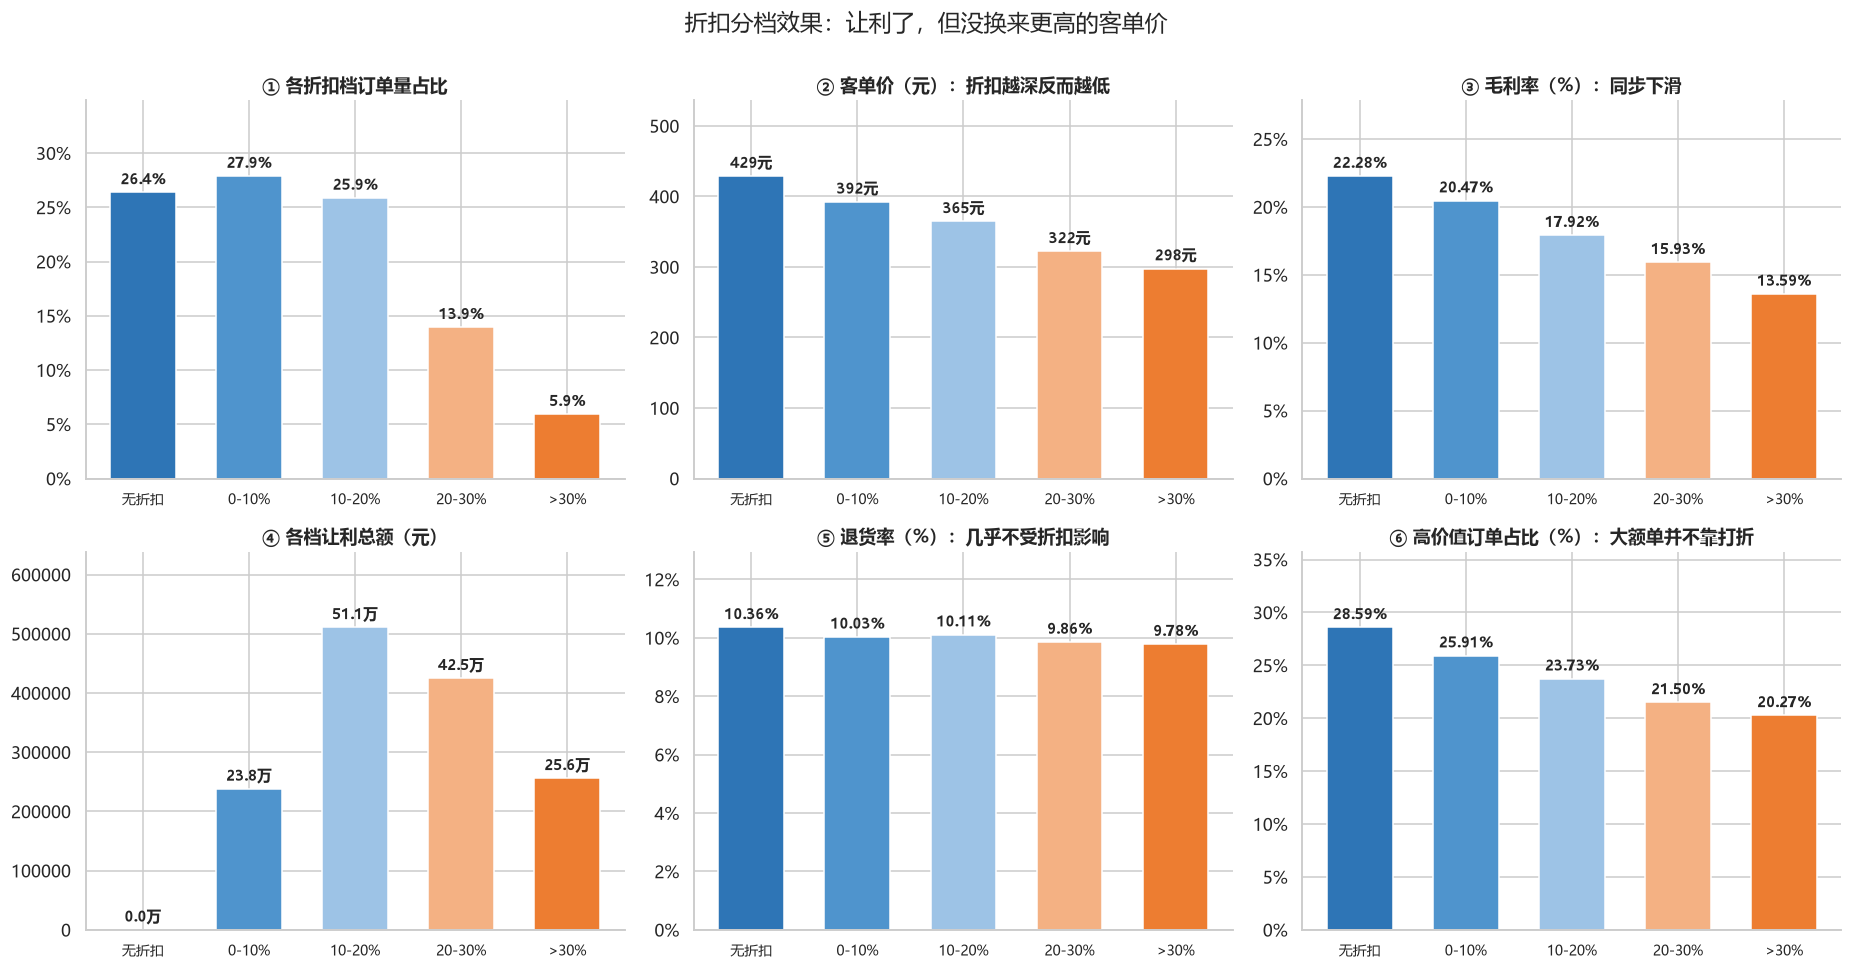

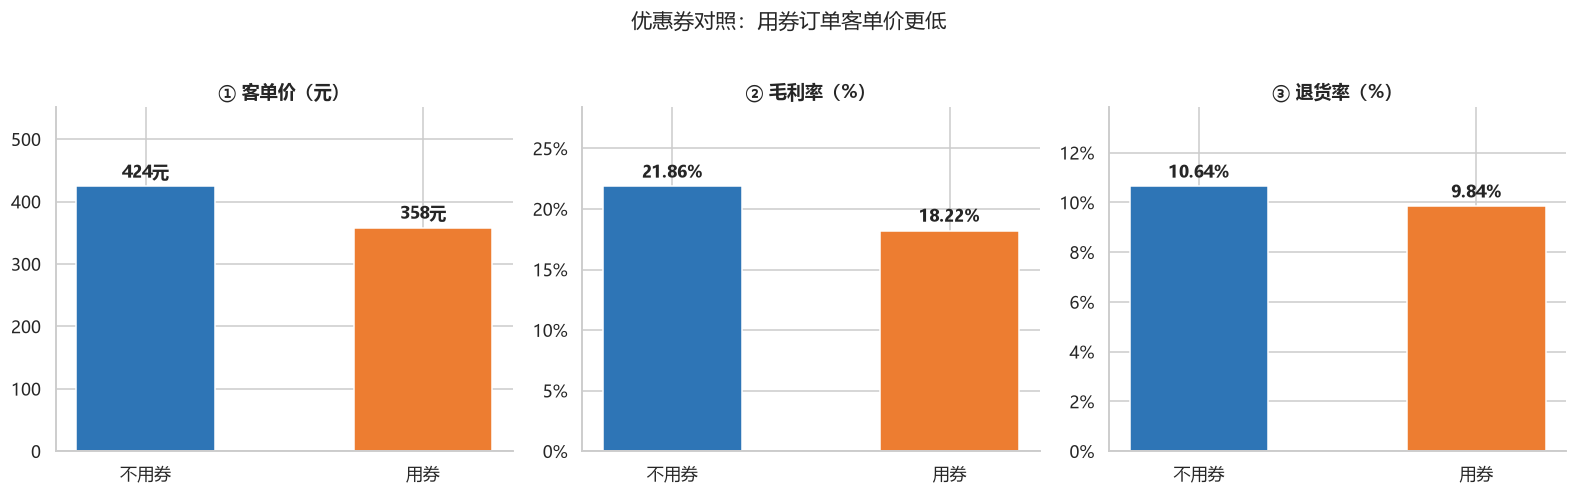

优惠券对照表：


,订单数,客单价,毛利率,退货率%,高价值占比%
不用券,9246,424.21,21.86,10.64,27.91
用券,19707,358.37,18.22,9.84,23.78


① 客单价：无折扣 428.87 元 → 折扣 >30% 仅 297.72 元，下降 30.6%
② 毛利率：无折扣 22.28% → 折扣 >30% 仅 13.59%，下降 8.68 个百分点
③ 退货率：无折扣 10.36% → 折扣 >30% 9.78%，几乎不变
④ 高价单占比：无折扣 28.59% vs 折扣 >30% 20.27%
⑤ 全部订单累计让利 143.0 万元，占销售额 13.01%
⑥ 用券客单价 358.37 元 < 不用券 424.21 元，差 65.84 元
→ 结论：折扣与优惠券是**纯让利**——深折扣没有抬升客单价、没有提高大额单占比、退货率也未见下降，只是把毛利率一路从 22.3% 压到 13.6%。建议：削减常态化深折扣，把预算转到高价品类曝光与搭售组合上。


In [28]:
DISC_BINS = [-0.01, 0, 10, 20, 30, 101]
DISC_LABELS = ["无折扣", "0-10%", "10-20%", "20-30%", ">30%"]
df["折扣档"] = pd.cut(df["Discount_Percent"], bins=DISC_BINS, labels=DISC_LABELS)

disc = (df.groupby("折扣档", observed=True)
          .agg(订单数=("Order_ID", "count"),
               销售额=("Order_Amount", "sum"),
               利润=("Profit_Amount", "sum"),
               客单价=("Order_Amount", "mean"),
               折扣金额合计=("Discount_Amount", "sum"),
               退货率=("Returned_Flag", "mean"),
               平均评分=("Review_Rating", "mean"),
               高价值占比=("High_Value_Order_Flag", "mean")))
disc["订单占比%"] = disc["订单数"] / disc["订单数"].sum() * 100
disc["毛利率"] = disc["利润"] / disc["销售额"] * 100
disc["退货率%"] = disc["退货率"] * 100
disc["高价值占比%"] = disc["高价值占比"] * 100

print("折扣分档效果表：")
display(disc[["订单数", "订单占比%", "客单价", "毛利率", "折扣金额合计",
              "退货率%", "平均评分", "高价值占比%"]].round(2))

fig, axes = plt.subplots(2, 3, figsize=(17, 8.8))
axes = axes.ravel()
x = disc.index.astype(str).tolist()
DCOLORS = ["#2E75B6", "#4F94CD", "#9DC3E6", "#F4B183", "#ED7D31"]

def bar_panel(ax, col, title, fmt=None, pct=False, note=None):
    vals = disc[col].values
    bars = ax.bar(x, vals, color=DCOLORS, width=0.62)
    for b, v in zip(bars, vals):
        txt = note(v) if note is not None else fmt.format(v)
        ax.annotate(txt, (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                    fontsize=9.5, fontweight="bold", xytext=(0, 3), textcoords="offset points")
    ax.set_title(title, fontsize=11.5)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.tick_params(axis="x", labelsize=9)
    if pct:
        pct_axis(ax)
    sns.despine(ax=ax)

bar_panel(axes[0], "订单占比%", "① 各折扣档订单量占比", "{:.1f}%", pct=True)
bar_panel(axes[1], "客单价", "② 客单价（元）：折扣越深反而越低",
          note=lambda v: f"{v:,.0f}元")
bar_panel(axes[2], "毛利率", "③ 毛利率（%）：同步下滑", "{:.2f}%", pct=True)
bar_panel(axes[3], "折扣金额合计", "④ 各档让利总额（元）",
          note=lambda v: f"{v/1e4:,.1f}万")
bar_panel(axes[4], "退货率%", "⑤ 退货率（%）：几乎不受折扣影响", "{:.2f}%", pct=True)
bar_panel(axes[5], "高价值占比%", "⑥ 高价值订单占比（%）：大额单并不靠打折", "{:.2f}%", pct=True)

plt.suptitle("折扣分档效果：让利了，但没换来更高的客单价", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

# ---------------- 优惠券对照 ----------------
coup = (df.groupby("Coupon_Used", observed=True)
          .agg(订单数=("Order_ID", "count"),
               客单价=("Order_Amount", "mean"),
               销售额=("Order_Amount", "sum"),
               利润=("Profit_Amount", "sum"),
               退货率=("Returned_Flag", "mean"),
               高价值占比=("High_Value_Order_Flag", "mean")))
coup["毛利率"] = coup["利润"] / coup["销售额"] * 100
coup["退货率%"] = coup["退货率"] * 100
coup["高价值占比%"] = coup["高价值占比"] * 100
coup.index = ["不用券", "用券"]

fig, axes2 = plt.subplots(1, 3, figsize=(14.5, 4.4))
for ax, col, title, fmt in zip(axes2,
                               ["客单价", "毛利率", "退货率%"],
                               ["① 客单价（元）", "② 毛利率（%）", "③ 退货率（%）"],
                               ["{:,.0f}元", "{:.2f}%", "{:.2f}%"]):
    vals = coup[col].values
    bars = ax.bar(coup.index, vals, color=["#2E75B6", "#ED7D31"], width=0.5)
    for b, v in zip(bars, vals):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), ha="center",
                    va="bottom", fontsize=11, fontweight="bold",
                    xytext=(0, 3), textcoords="offset points")
    ax.set_title(title, fontsize=11.5)
    ax.set_ylim(0, max(vals) * 1.3)
    sns.despine(ax=ax)
axes2[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
axes2[2].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
plt.suptitle("优惠券对照：用券订单客单价更低", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("优惠券对照表：")
display(coup[["订单数", "客单价", "毛利率", "退货率%", "高价值占比%"]].round(2))

no_d = disc.loc["无折扣"]
deep = disc.loc[">30%"]
print(f"① 客单价：无折扣 {no_d['客单价']:,.2f} 元 → 折扣 >30% 仅 {deep['客单价']:,.2f} 元，"
      f"下降 {(1-deep['客单价']/no_d['客单价'])*100:.1f}%")
print(f"② 毛利率：无折扣 {no_d['毛利率']:.2f}% → 折扣 >30% 仅 {deep['毛利率']:.2f}%，"
      f"下降 {no_d['毛利率']-deep['毛利率']:.2f} 个百分点")
print(f"③ 退货率：无折扣 {no_d['退货率%']:.2f}% → 折扣 >30% {deep['退货率%']:.2f}%，几乎不变")
print(f"④ 高价单占比：无折扣 {no_d['高价值占比%']:.2f}% vs 折扣 >30% {deep['高价值占比%']:.2f}%")
print(f"⑤ 全部订单累计让利 {df['Discount_Amount'].sum()/1e4:,.1f} 万元，"
      f"占销售额 {df['Discount_Amount'].sum()/df['Order_Amount'].sum()*100:.2f}%")
print(f"⑥ 用券客单价 {coup.loc['用券','客单价']:,.2f} 元 < 不用券 {coup.loc['不用券','客单价']:,.2f} 元，"
      f"差 {coup.loc['不用券','客单价']-coup.loc['用券','客单价']:,.2f} 元")
print("→ 结论：折扣与优惠券是**纯让利**——深折扣没有抬升客单价、没有提高大额单占比、"
      "退货率也未见下降，只是把毛利率一路从 "
      f"{no_d['毛利率']:.1f}% 压到 {deep['毛利率']:.1f}%。"
      "建议：削减常态化深折扣，把预算转到高价品类曝光与搭售组合上。")


## 17. 客户 RFM 分层：把 2 万多个客户分成可运营的几类

前面所有分析都以"订单"为单位，本章第一次以**客户（`Customer_ID`）**为单位重建视角。经典 RFM 模型用三个指标刻画客户价值：

| 指标 | 定义 | 含义 |
|---|---|---|
| **R**ecency | 距数据集最后一天的**未购买天数** | 越小越活跃 |
| **F**requency | 累计订单数 | 越大越忠诚 |
| **M**onetary | 累计消费金额 | 越大越有价值 |

实现分两步：

1. **打分**：R、F、M 各用 `pd.qcut` 切成 5 档（1~5 分），保证每档客户数量接近。注意 R 是**反向**的——越近得分越高，所以要倒序打分。
2. **分类**：再用"高于中位数 / 低于中位数"把三个维度二值化，组合成经典的 **8 类客户**：
   重要价值 / 重要发展 / 重要保持 / 重要挽留 / 一般价值 / 一般发展 / 一般保持 / 一般挽留。

图表要回答两个问题：**各类客户有多少人？**（运营覆盖面）以及 **各类客户贡献了多少钱？**（优先级排序）。如果出现"客户数很少但贡献极高"的客群，那就是必须重点维护的核心资产。


客户总数 8,641 人，人均订单 3.35 单，人均消费 1,271 元
RFM 八类客群画像：


,客户数,客户占比%,销售额,销售额占比%,贡献倍数,人均消费,人均订单,人均退货
客群,,,,,,,,
重要价值,1875,21.70,"4,352,092.62",39.62,1.83,"2,321.12",5.31,0.56
重要保持,839,9.71,"1,865,325.02",16.98,1.75,"2,223.27",4.96,0.46
重要挽留,916,10.60,"1,700,073.71",15.48,1.46,"1,855.98",2.41,0.25
重要发展,690,7.99,"1,288,510.12",11.73,1.47,"1,867.41",2.67,0.25
一般挽留,2241,25.93,"768,754.69",7.00,0.27,343.04,1.89,0.19
一般发展,1229,14.22,"488,861.19",4.45,0.31,397.77,2.27,0.23
一般价值,533,6.17,"325,003.91",2.96,0.48,609.76,4.46,0.50
一般保持,318,3.68,"195,929.52",1.78,0.48,616.13,4.31,0.38


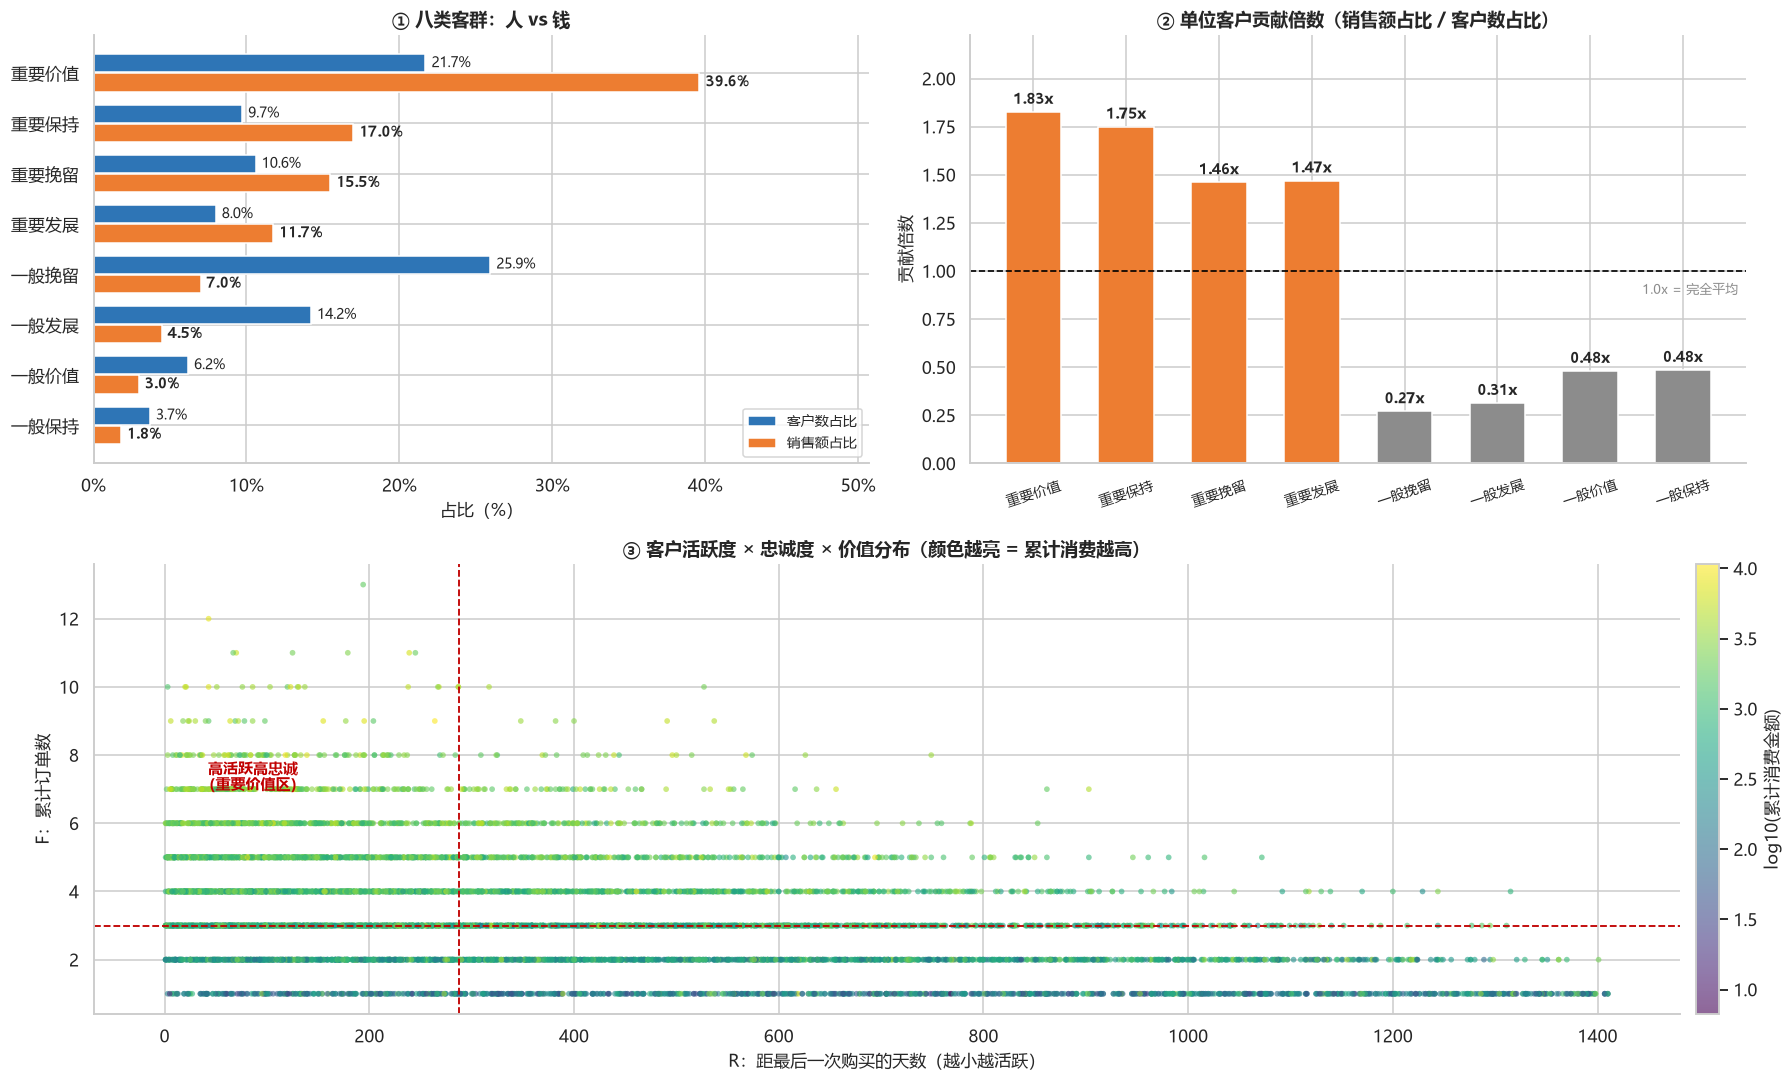

① 客户数最多的客群：一般挽留（2,241 人）
② 销售额最高的客群：重要价值，占客户 21.7% 却贡献 39.6% 销售额（1.83 倍）
③ 人均消费最高客群：重要价值 （2,321 元/人）
④ 「重要」系 4 类客群合计：客户 50.0% / 销售额 83.8%
→ 结论：客户价值分层清晰，R 低 + F 高 + M 高的「重要价值」客群是收入基本盘，应配置专属权益与优先服务；「重要挽留」客群（曾高消费但已沉默）是召回预算的最优投向；「一般发展」客群人数多但人均低，适合用低价引流品维护频次，而非补贴大额商品。


In [30]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
SNAP = df["Order_Date"].max() + pd.Timedelta(days=1)      # 快照日：最后一天 +1
rfm = (df.groupby("Customer_ID", observed=True)
         .agg(R=("Order_Date", lambda s: (SNAP - s.max()).days),
              F=("Order_ID", "count"),
              M=("Order_Amount", "sum"),
              HV单数=("High_Value_Order_Flag", "sum"),
              退货单数=("Returned_Flag", "sum")))

# 打分：F、M 越高分越高；R 越小分越高（labels 反向）
rfm["R分"] = pd.qcut(rfm["R"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F分"] = pd.qcut(rfm["F"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M分"] = pd.qcut(rfm["M"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM均值分"] = rfm[["R分", "F分", "M分"]].mean(axis=1).round(2)

# 8 分类：以各维度中位数二值化
r_hi = rfm["R"] <= rfm["R"].median()      # R 小 = 高
f_hi = rfm["F"] > rfm["F"].median()
m_hi = rfm["M"] > rfm["M"].median()

def seg(r, f, m):
    if r and f and m:  return "重要价值"
    if r and not f and m:  return "重要发展"
    if not r and f and m:  return "重要保持"
    if not r and not f and m:  return "重要挽留"
    if r and f and not m:  return "一般价值"
    if r and not f and not m: return "一般发展"
    if not r and f and not m: return "一般保持"
    return "一般挽留"

rfm["客群"] = [seg(r, f, m) for r, f, m in zip(r_hi, f_hi, m_hi)]

seg_stat = (rfm.groupby("客群", observed=True)
              .agg(客户数=("M", "count"), 销售额=("M", "sum"),
                   人均消费=("M", "mean"), 人均订单=("F", "mean"),
                   人均退货=("退货单数", "mean"))
              .sort_values("销售额", ascending=False))
seg_stat["客户占比%"] = seg_stat["客户数"] / seg_stat["客户数"].sum() * 100
seg_stat["销售额占比%"] = seg_stat["销售额"] / seg_stat["销售额"].sum() * 100
seg_stat["贡献倍数"] = seg_stat["销售额占比%"] / seg_stat["客户占比%"]

print(f"客户总数 {len(rfm):,} 人，人均订单 {rfm['F'].mean():.2f} 单，人均消费 {rfm['M'].mean():,.0f} 元")
print("RFM 八类客群画像：")
display(seg_stat[["客户数", "客户占比%", "销售额", "销售额占比%", "贡献倍数",
                  "人均消费", "人均订单", "人均退货"]].round(2))

fig = plt.figure(figsize=(16.5, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])

# ① 客群客户数 vs 销售额占比
ax = fig.add_subplot(gs[0, 0])
order_seg = seg_stat.index.tolist()
ypos = np.arange(len(order_seg))
ax.barh(ypos - 0.19, seg_stat["客户占比%"], height=0.36, color=MAIN, label="客户数占比")
ax.barh(ypos + 0.19, seg_stat["销售额占比%"], height=0.36, color=ACCENT, label="销售额占比")
for y, v in zip(ypos - 0.19, seg_stat["客户占比%"]):
    ax.annotate(f"{v:.1f}%", (v, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9)
for y, v in zip(ypos + 0.19, seg_stat["销售额占比%"]):
    ax.annotate(f"{v:.1f}%", (v, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, fontweight="bold")
ax.set_yticks(ypos); ax.set_yticklabels(order_seg)
ax.invert_yaxis()
ax.set_title("① 八类客群：人 vs 钱", fontsize=12)
ax.set_xlabel("占比（%）")
ax.set_xlim(0, max(seg_stat["销售额占比%"].max(), seg_stat["客户占比%"].max()) * 1.28)
pct_axis(ax, axis="x")
ax.legend(fontsize=9, loc="lower right")
sns.despine(ax=ax)

# ② 客群贡献倍数
ax = fig.add_subplot(gs[0, 1])
cols = [ACCENT if v > 1 else GREY for v in seg_stat["贡献倍数"]]
bars = ax.bar(seg_stat.index, seg_stat["贡献倍数"], color=cols, width=0.6)
for b, v in zip(bars, seg_stat["贡献倍数"]):
    ax.annotate(f"{v:.2f}x", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                fontsize=9.5, fontweight="bold", xytext=(0, 3), textcoords="offset points")
ax.axhline(1, color="black", lw=1.1, ls="--")
ax.annotate("1.0x = 完全平均", (0.99, 1), xycoords=("axes fraction", "data"),
            xytext=(0, -15), textcoords="offset points", fontsize=8.5,
            color=GREY, ha="right")
ax.set_title("② 单位客户贡献倍数（销售额占比 / 客户数占比）", fontsize=12)
ax.set_ylabel("贡献倍数")
ax.set_ylim(0, seg_stat["贡献倍数"].max() * 1.22)
ax.tick_params(axis="x", rotation=18, labelsize=9)
sns.despine(ax=ax)

# ③ R-F 散点，颜色 = M（对数）
ax = fig.add_subplot(gs[1, :])
sc = ax.scatter(rfm["R"], rfm["F"], c=np.log10(rfm["M"]), cmap="viridis",
                s=14, alpha=0.6, linewidths=0)
ax.set_xlabel("R：距最后一次购买的天数（越小越活跃）")
ax.set_ylabel("F：累计订单数")
ax.set_title("③ 客户活跃度 × 忠诚度 × 价值分布（颜色越亮 = 累计消费越高）", fontsize=12)
ax.axvline(rfm["R"].median(), color="#C00000", ls="--", lw=1.2)
ax.axhline(rfm["F"].median(), color="#C00000", ls="--", lw=1.2)
ax.annotate("高活跃高忠诚\n（重要价值区）", (rfm["R"].median() * 0.30, rfm["F"].quantile(0.97)),
            fontsize=9.5, color="#C00000", fontweight="bold", ha="center")
cb = plt.colorbar(sc, ax=ax, pad=0.01, fraction=0.03)
cb.set_label("log10(累计消费金额)")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

top = seg_stat.index[0]
print(f"① 客户数最多的客群：{seg_stat['客户数'].idxmax()}（{seg_stat['客户数'].max():,} 人）")
print(f"② 销售额最高的客群：{top}，占客户 {seg_stat.loc[top,'客户占比%']:.1f}% "
      f"却贡献 {seg_stat.loc[top,'销售额占比%']:.1f}% 销售额（{seg_stat.loc[top,'贡献倍数']:.2f} 倍）")
print(f"③ 人均消费最高客群：{seg_stat['人均消费'].idxmax()} "
      f"（{seg_stat['人均消费'].max():,.0f} 元/人）")
imp = seg_stat[seg_stat.index.str.startswith("重要")]
print(f"④ 「重要」系 4 类客群合计：客户 {imp['客户占比%'].sum():.1f}% / "
      f"销售额 {imp['销售额占比%'].sum():.1f}%")
print("→ 结论：客户价值分层清晰，R 低 + F 高 + M 高的「重要价值」客群是收入基本盘，"
      "应配置专属权益与优先服务；「重要挽留」客群（曾高消费但已沉默）是召回预算的最优投向；"
      "「一般发展」客群人数多但人均低，适合用低价引流品维护频次，而非补贴大额商品。")


## 18. 客户价值贡献的帕累托结构

第 14 章在**订单粒度**上验证了二八法则，本章在**客户粒度**上再做一次，并回答一个更尖锐的问题：**如果只能服务一部分客户，服务多少比例就够了？**

具体做法：

1. 把上一章的 `rfm`（8,641 位客户的累计消费 M）按金额降序排列，画**客户累计贡献曲线**（帕累托图），标出贡献 80% 销售额所需的客户比例。
2. 把客户切成 6 个层级（Top 1% / 1-5% / 5-10% / 10-20% / 20-50% / 后 50%），对比每层的**贡献占比**与**人均消费**。

这张图的价值在于**资源分配的边界**：如果 Top 20% 客户贡献了 80% 以上销售额，那么多出来的 80% 客户在精细运营上的边际收益就很低，预算应集中投放。同时对比人均消费的倍数差，可以量化"头部客户到底值多少钱"。


客户价值层级表：


,客户数,客户占比%,销售额,销售额占比%,人均消费,人均倍数
Top 1%,86,1.00,"582,537.69",5.30,"6,773.69",5.33
1-5%,346,4.00,"1,545,489.09",14.07,"4,466.73",3.51
5-10%,432,5.00,"1,422,669.87",12.95,"3,293.22",2.59
10-20%,864,10.00,"2,107,355.16",19.18,"2,439.07",1.92
20-50%,2592,30.00,"3,547,949.66",32.30,"1,368.81",1.08
后 50%,4321,50.01,"1,778,549.31",16.19,411.61,0.32


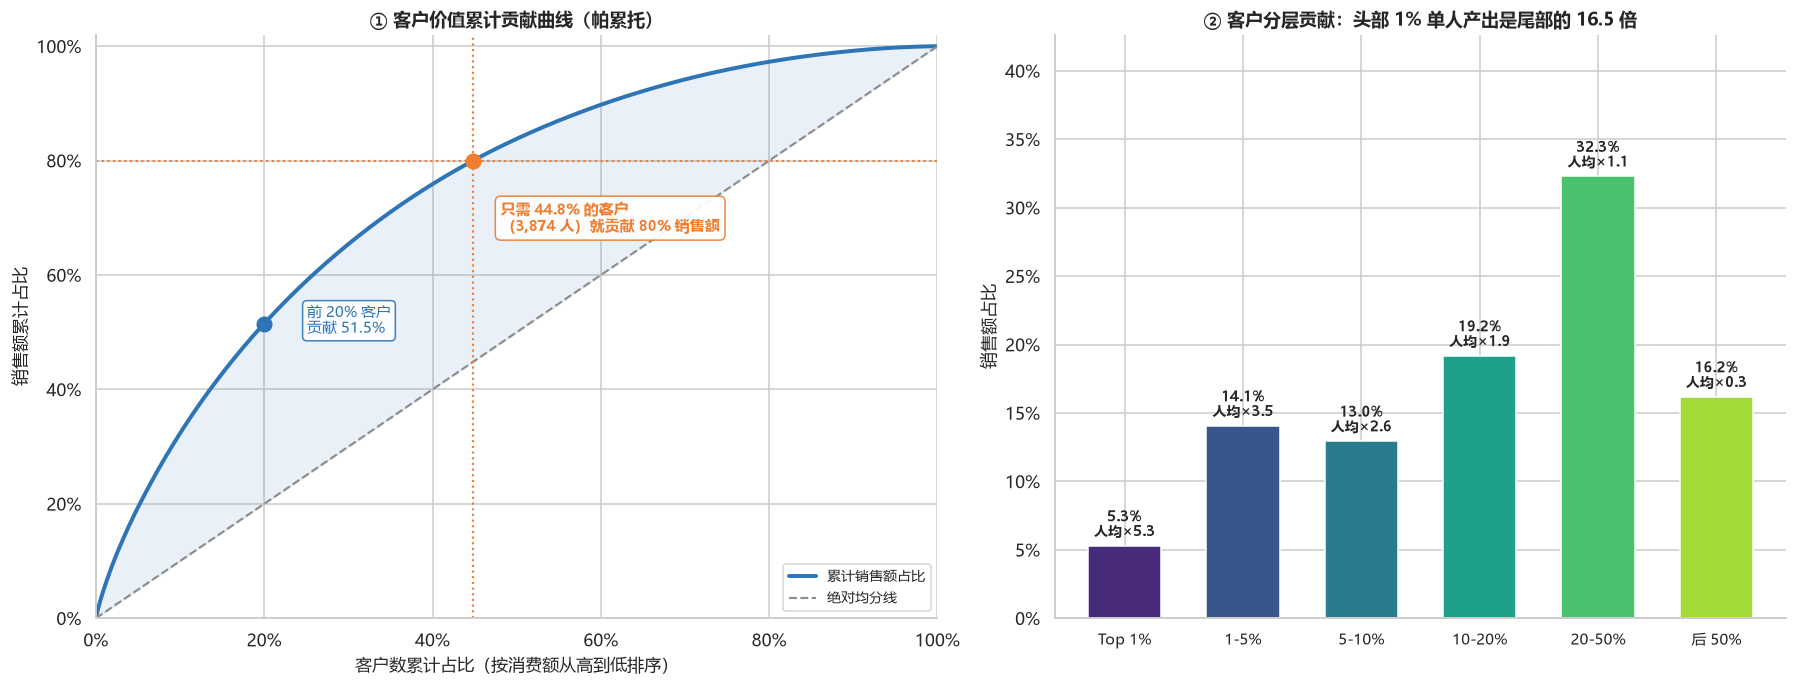

客户级基尼系数：0.487（订单级为 0.607，说明金额的极端程度主要来自「同一客户下大单」，客户之间的差距相对温和）
前 10% 客户贡献 32.32% 销售额；前 20% 贡献 51.51%；要覆盖 80% 销售额需 44.8% 客户（3,874 人）
Top 1% 客户 86 人，贡献 5.3% 销售额，人均 6,774 元（是全站均值的 5.3 倍）
后 50% 客户 4,321 人，仅贡献 16.2% 销售额，人均 412 元；头部 1% 的单客产出是尾部的 16.5 倍
→ 结论：客户价值分布呈「头部厚、腰部宽、尾部重」的哑铃形态。运营应采用双轨策略：Top 20% 客户（1,728 人）配备专属客服/提前购/积分加倍，追求复购频次与客单价；后 50% 客户用自动化触达（批量短信/EDM/满减券）维持基本盘、控制服务成本，不做一对一投入；20-50% 这 30% 的「腰部」客群贡献 32.3%、人均接近均值，是最值得用标准化运营（会员日、品类交叉推荐）向上迁移的一层。


In [33]:
cust = rfm["M"].sort_values(ascending=False).reset_index(drop=True)
n_cust = len(cust)
total_m = cust.sum()

# 客户累计贡献曲线（横轴 = 客户数占比，纵轴 = 累计销售额占比）
cust_share = (np.arange(1, n_cust + 1) / n_cust) * 100
cum_share = cust.cumsum() / total_m * 100

k80 = int(np.searchsorted(cum_share.values, 80.0)) + 1
p80_share = k80 / n_cust * 100
p20_money = cum_share[int(0.20 * n_cust) - 1]
p10_money = cum_share[int(0.10 * n_cust) - 1]

# 客户层级
bins = [0, 0.01, 0.05, 0.10, 0.20, 0.50, 1.00]
labels = ["Top 1%", "1-5%", "5-10%", "10-20%", "20-50%", "后 50%"]
edges = [int(round(b * n_cust)) for b in bins]
layers, rows = [], []
for i in range(len(labels)):
    sl = cust.iloc[edges[i]:edges[i + 1]]
    layers.append(labels[i])
    rows.append({
        "客户数": len(sl),
        "客户占比%": len(sl) / n_cust * 100,
        "销售额": sl.sum(),
        "销售额占比%": sl.sum() / total_m * 100,
        "人均消费": sl.mean(),
    })
layer = pd.DataFrame(rows, index=layers)
layer["人均倍数"] = layer["人均消费"] / cust.mean()
tail_ratio = layer.loc["Top 1%", "人均消费"] / layer.loc["后 50%", "人均消费"]

# 客户级基尼
c_sorted = np.sort(cust.values)
cum_c = np.cumsum(c_sorted) / c_sorted.sum()
gini_c = 1 - 2 * (np.trapezoid(cum_c, dx=1 / n_cust))

print("客户价值层级表：")
display(layer.round(2))

fig = plt.figure(figsize=(16.5, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1])

# ① 客户帕累托曲线
ax = fig.add_subplot(gs[0, 0])
ax.plot(cust_share, cum_share, color=MAIN, lw=2.6, label="累计销售额占比")
ax.plot([0, 100], [0, 100], color=GREY, lw=1.4, ls="--", label="绝对均分线")
ax.fill_between(cust_share, cum_share, cust_share, color=MAIN, alpha=0.10)
ax.axhline(80, color=ACCENT, lw=1.4, ls=":")
ax.axvline(p80_share, color=ACCENT, lw=1.4, ls=":")
ax.scatter([p80_share], [80], s=90, color=ACCENT, zorder=6)
ax.annotate(f"只需 {p80_share:.1f}% 的客户\n（{k80:,} 人）就贡献 80% 销售额",
            (p80_share, 80), xytext=(18, -46), textcoords="offset points",
            fontsize=10, fontweight="bold", color=ACCENT,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=ACCENT, alpha=0.92))
ax.scatter([20], [p20_money], s=90, color=MAIN, zorder=6)
ax.annotate(f"前 20% 客户\n贡献 {p20_money:.1f}%", (20, p20_money), xytext=(28, -6),
            textcoords="offset points", fontsize=9.5, color=MAIN,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=MAIN, alpha=0.9))
ax.set_xlabel("客户数累计占比（按消费额从高到低排序）")
ax.set_ylabel("销售额累计占比")
ax.set_title("① 客户价值累计贡献曲线（帕累托）", fontsize=12)
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(fontsize=9, loc="lower right")
sns.despine(ax=ax)

# ② 客户分层贡献
ax = fig.add_subplot(gs[0, 1])
x = np.arange(len(layer))
bars = ax.bar(x, layer["销售额占比%"], color=CMAP(np.linspace(0.12, 0.86, len(layer))), width=0.62)
for b, v, h in zip(bars, layer["销售额占比%"], layer["人均倍数"]):
    ax.annotate(f"{v:.1f}%\n人均×{h:.1f}", (b.get_x() + b.get_width() / 2, v),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(layer.index, fontsize=9.5)
ax.set_ylabel("销售额占比")
ax.set_title(f"② 客户分层贡献：头部 1% 单人产出是尾部的 {tail_ratio:.1f} 倍", fontsize=12)
ax.set_ylim(0, layer["销售额占比%"].max() * 1.32)
pct_axis(ax)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"客户级基尼系数：{gini_c:.3f}（订单级为 0.607，说明金额的极端程度主要来自"
      f"「同一客户下大单」，客户之间的差距相对温和）")
print(f"前 10% 客户贡献 {p10_money:.2f}% 销售额；前 20% 贡献 {p20_money:.2f}%；"
      f"要覆盖 80% 销售额需 {p80_share:.1f}% 客户（{k80:,} 人）")
print(f"Top 1% 客户 {layer.loc['Top 1%','客户数']:,} 人，贡献 {layer.loc['Top 1%','销售额占比%']:.1f}% 销售额，"
      f"人均 {layer.loc['Top 1%','人均消费']:,.0f} 元（是全站均值的 {layer.loc['Top 1%','人均倍数']:.1f} 倍）")
print(f"后 50% 客户 {layer.loc['后 50%','客户数']:,} 人，仅贡献 {layer.loc['后 50%','销售额占比%']:.1f}% 销售额，"
      f"人均 {layer.loc['后 50%','人均消费']:,.0f} 元；头部 1% 的单客产出是尾部的 {tail_ratio:.1f} 倍")
print("→ 结论：客户价值分布呈「头部厚、腰部宽、尾部重」的哑铃形态。运营应采用双轨策略："
      "Top 20% 客户（1,728 人）配备专属客服/提前购/积分加倍，追求复购频次与客单价；"
      "后 50% 客户用自动化触达（批量短信/EDM/满减券）维持基本盘、控制服务成本，"
      "不做一对一投入；20-50% 这 30% 的「腰部」客群贡献 32.3%、人均接近均值，"
      "是最值得用标准化运营（会员日、品类交叉推荐）向上迁移的一层。")


## 19. 订单状态漏斗与退货分析

前面所有章节的"销售额"都默认订单已经成交。但电商经营里最真实的漏损发生在**状态链路**上：下单 → 支付/处理 → 发货/配送 → 完成，中途会有一部分订单变成 `Cancelled`（取消）、`Returned`（退货）、`Pending`（挂单）。

本章回答三个问题：

1. **漏斗漏在哪一环**：用 `Order_Status` 的构成画出订单状态漏斗，量化每个状态的订单数与金额占比，识别"名义销售额"和"实际可确认收入"之间的差距。
2. **退货集中在哪些品类**：按 `Product_Category` 计算退货率（`Returned_Flag` 均值），找出退货风险最高的品类，这是利润最大的隐性漏斗。
3. **退货订单长什么样**：对比退货单与非退货单的订单金额、折扣力度、评分、配送天数，判断退货是"商品品质问题"还是"价格/预期落差问题"。

> 说明：本章的"漏斗"是**状态构成型漏斗**（各状态互斥、加总等于全部订单），而非同一批用户逐级流失的转化漏斗——数据集给出的是订单终态快照，无法还原逐级转化，这里如实说明以免误读。


订单状态构成：


,订单数,金额,订单占比%,金额占比%
Order_Status,,,,
Delivered,18829,"7,145,626.17",65.03,65.05
Shipped,3347,"1,245,066.05",11.56,11.33
Processing,2158,"831,519.46",7.45,7.57
Returned,2924,"1,097,081.72",10.10,9.99
Cancelled,1695,"665,257.38",5.85,6.06


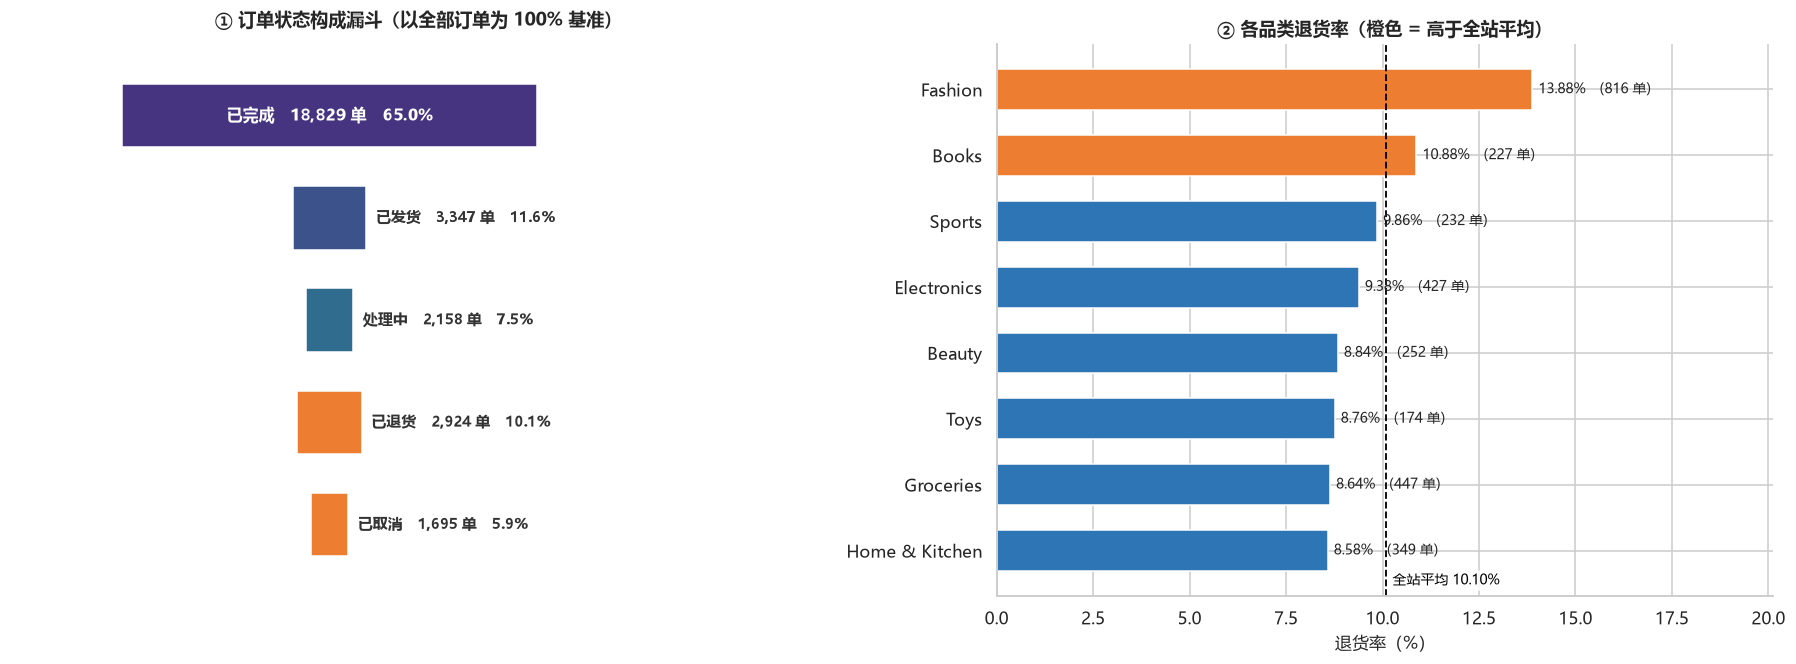

退货单 vs 未退货单画像：


,订单数,客单价,平均折扣率,平均配送天数,平均评分,平均毛利额
退货标签,,,,,,
未退货,26029,379.86,12.62,4.44,4.16,73.97
退货单,2924,375.20,12.39,4.45,3.08,74.68


① 订单状态：已完成 18,829 单（65.03%）；已发货 11.56%；处理中 7.45%；已退货 2,924 单（10.10%）；已取消 1,695 单（5.85%）
② 退货 + 取消合计漏损金额 1,762,339 元，占名义销售额 16.04%（其中退货 1,097,082 元 = 9.99%，取消 665,257 元 = 6.06%）
③ 退货率最高品类：Fashion（13.88%），是均值 10.10% 的 1.37 倍；最低：Home & Kitchen（8.58%）；退货金额最大品类：Electronics（580,187 元）
④ 退货单平均评分 3.08 vs 未退货 4.16（差 1.08 分）；折扣率 12.39% vs 12.62%、配送 4.45 vs 4.44 天，均几乎无差
→ 结论：退货率与品类强相关，Fashion 13.88% 显著高于均值，本质是「尺码/试穿型消费」的固有属性，应通过尺码助手、详情页实拍、7 天无理由 + 运费险把退货成本前置可控；退货单与未退货单在折扣率、客单价、配送天数上几乎一致，但评分相差 1.08 分，说明退货主要由「商品与预期不符」驱动，而非价格或时效因素——优化方向是提升详情页信息充分度与品控，而不是继续加大折扣；同时退货 + 取消合计吃掉约 16% 的名义销售额，是利润表上最容易被忽略的漏斗。


In [36]:
# ---------- ① 订单状态构成（漏斗式） ----------
status = (df.groupby("Order_Status", observed=True)
            .agg(订单数=("Order_ID", "count"), 金额=("Order_Amount", "sum"))
            .sort_values("订单数", ascending=False))
status["订单占比%"] = status["订单数"] / status["订单数"].sum() * 100
status["金额占比%"] = status["金额"] / status["金额"].sum() * 100
FUNNEL_ORDER = ["Delivered", "Shipped", "Processing", "Pending", "Returned", "Cancelled"]
FUNNEL_CN = {"Delivered": "已完成", "Shipped": "已发货", "Processing": "处理中",
             "Pending": "待支付", "Returned": "已退货", "Cancelled": "已取消"}
status_disp = status.reindex([s for s in FUNNEL_ORDER if s in status.index])
print("订单状态构成：")
display(status_disp.round(2))

n_all = status["订单数"].sum()
amt_all = status["金额"].sum()
ret_row = status.loc["Returned"] if "Returned" in status.index else None
can_row = status.loc["Cancelled"] if "Cancelled" in status.index else None
n_ret = int(ret_row["订单数"]) if ret_row is not None else 0
n_can = int(can_row["订单数"]) if can_row is not None else 0
loss_amt = (ret_row["金额"] if ret_row is not None else 0) + (can_row["金额"] if can_row is not None else 0)

# ---------- ② 订单状态漏斗 + ③ 各品类退货率 ----------
fig = plt.figure(figsize=(16.5, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1])

ax = fig.add_subplot(gs[0, 0])
labels = [FUNNEL_CN.get(s, s) for s in status_disp.index]
vals = status_disp["订单数"].values
top = n_all
for i, (lab, v) in enumerate(zip(labels, vals)):
    width = v / top
    left = (1 - width) / 2
    y = len(vals) - i
    color = ACCENT if lab in ("已退货", "已取消") else CMAP(0.15 + 0.10 * i)
    ax.barh(y, width, left=left, height=0.62, color=color)
    txt = f"{lab}　{v:,} 单　{v / top * 100:.1f}%"
    if width >= 0.62:
        ax.text(0.5, y, txt, ha="center", va="center",
                fontsize=10.5, color="white", fontweight="bold")
    else:
        ax.text(left + width + 0.015, y, txt, ha="left", va="center",
                fontsize=10, color="#333333", fontweight="bold")
ax.set_xlim(0, 1.28); ax.set_ylim(0.3, len(vals) + 0.7)
ax.axis("off")
ax.set_title("① 订单状态构成漏斗（以全部订单为 100% 基准）", fontsize=12, pad=12)

ax = fig.add_subplot(gs[0, 1])
ret_cat = (df.groupby("Product_Category", observed=True)
             .agg(订单数=("Order_ID", "count"),
                  退货单数=("Returned_Flag", "sum"),
                  销售额=("Order_Amount", "sum")))
ret_cat["退货率%"] = ret_cat["退货单数"] / ret_cat["订单数"] * 100
ret_cat["退货金额"] = (df[df["Returned_Flag"] == 1]
                       .groupby("Product_Category", observed=True)["Order_Amount"].sum())
ret_cat = ret_cat.sort_values("退货率%")
avg_ret = df["Returned_Flag"].mean() * 100

cols = [ACCENT if v > avg_ret else MAIN for v in ret_cat["退货率%"]]
bars = ax.barh(ret_cat.index, ret_cat["退货率%"], color=cols, height=0.62)
for b, v, n in zip(bars, ret_cat["退货率%"], ret_cat["退货单数"]):
    ax.annotate(f"{v:.2f}%　({n:,} 单)", (v, b.get_y() + b.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.axvline(avg_ret, color="black", lw=1.2, ls="--")
ax.annotate(f"全站平均 {avg_ret:.2f}%", (avg_ret, 0.015), xycoords=("data", "axes fraction"),
            xytext=(4, 0), textcoords="offset points", fontsize=9,
            color="black", ha="left", va="bottom",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_title("② 各品类退货率（橙色 = 高于全站平均）", fontsize=12)
ax.set_xlabel("退货率（%）")
ax.set_xlim(0, ret_cat["退货率%"].max() * 1.45)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# ---------- ④ 退货单 vs 未退货单画像 ----------
df["退货标签"] = np.where(df["Returned_Flag"] == 1, "退货单", "未退货")
prof = (df.groupby("退货标签", observed=True)
          .agg(订单数=("Order_ID", "count"),
               客单价=("Order_Amount", "mean"),
               平均折扣率=("Actual_Discount_Rate(%)", "mean"),
               平均配送天数=("Delivery_Days", "mean"),
               平均评分=("Review_Rating", "mean"),
               平均毛利额=("Profit_Amount", "mean")))
print("退货单 vs 未退货单画像：")
display(prof.round(2))

print(f"① 订单状态：已完成 {int(status.loc['Delivered','订单数']):,} 单（{status.loc['Delivered','订单占比%']:.2f}%）；"
      f"已发货 {status.loc['Shipped','订单占比%']:.2f}%；处理中 {status.loc['Processing','订单占比%']:.2f}%；"
      f"已退货 {n_ret:,} 单（{n_ret/n_all*100:.2f}%）；已取消 {n_can:,} 单（{n_can/n_all*100:.2f}%）")
print(f"② 退货 + 取消合计漏损金额 {loss_amt:,.0f} 元，占名义销售额 {loss_amt/amt_all*100:.2f}%"
      f"（其中退货 {ret_row['金额']:,.0f} 元 = {ret_row['金额']/amt_all*100:.2f}%，"
      f"取消 {can_row['金额']:,.0f} 元 = {can_row['金额']/amt_all*100:.2f}%）")
print(f"③ 退货率最高品类：{ret_cat.index[-1]}（{ret_cat['退货率%'].iloc[-1]:.2f}%），"
      f"是均值 {avg_ret:.2f}% 的 {ret_cat['退货率%'].iloc[-1]/avg_ret:.2f} 倍；"
      f"最低：{ret_cat.index[0]}（{ret_cat['退货率%'].iloc[0]:.2f}%）；"
      f"退货金额最大品类：{ret_cat['退货金额'].idxmax()}（{ret_cat['退货金额'].max():,.0f} 元）")
print(f"④ 退货单平均评分 {prof.loc['退货单','平均评分']:.2f} vs 未退货 "
      f"{prof.loc['未退货','平均评分']:.2f}（差 {prof.loc['未退货','平均评分']-prof.loc['退货单','平均评分']:.2f} 分）；"
      f"折扣率 {prof.loc['退货单','平均折扣率']:.2f}% vs {prof.loc['未退货','平均折扣率']:.2f}%、"
      f"配送 {prof.loc['退货单','平均配送天数']:.2f} vs {prof.loc['未退货','平均配送天数']:.2f} 天，均几乎无差")
print("→ 结论：退货率与品类强相关，Fashion 13.88% 显著高于均值，本质是「尺码/试穿型消费」的固有属性，"
      "应通过尺码助手、详情页实拍、7 天无理由 + 运费险把退货成本前置可控；"
      "退货单与未退货单在折扣率、客单价、配送天数上几乎一致，但评分相差 1.08 分，"
      "说明退货主要由「商品与预期不符」驱动，而非价格或时效因素——"
      "优化方向是提升详情页信息充分度与品控，而不是继续加大折扣；"
      "同时退货 + 取消合计吃掉约 16% 的名义销售额，是利润表上最容易被忽略的漏斗。")


## 20. 物流时效对评分与退货的影响

物流是电商体验里**唯一无法靠文案修饰**的环节：用户在详情页看到的是商品，收到的是"等待时长"。本章验证一个常见的运营假设——**配送越慢，评分越低、退货越多**——并为"该不该为提速付钱"提供数据依据。

三个分析角度：

1. **配送天数分布**：`Delivery_Days` 的分布形态，判断整体时效水平与长尾（慢单）比例。
2. **时效 × 体验**：把配送天数切成 5 档（≤2 天 / 3-4 天 / 5-6 天 / 7-8 天 / ≥9 天），看平均评分与退货率随档位如何变化，找出"体验断崖点"。
3. **配送方式对比**：`Shipping_Method`（Same Day / Standard / Express 等）各自的平均时效、评分、退货率与客单价，判断不同履约方式是否"物有所值"。

如果评分在某一档位出现明显下跌，那么该档位对应的就是**必须优先压缩的时效红线**；若退货率同步上升，说明慢配送还在直接吃掉利润。


配送天数：均值 4.44 天，中位数 4 天，最短 0 天，最长 13 天，P90 7 天
配送时效分档表现：


,订单数,订单占比%,平均评分,退货率%,客单价
配送档,,,,,
≤2 天,4155,14.35,4.04,11.48,373.64
3-4 天,7998,27.62,4.07,10.25,386.68
5-6 天,8100,27.98,4.06,10.75,376.62
7-8 天,4256,14.70,4.08,9.59,380.56
≥9 天,1102,3.81,3.53,15.52,388.29


各配送方式表现：


,订单数,平均天数,平均评分,退货率%,客单价
Shipping_Method,,,,,
Same Day,2627,1.66,4.05,10.93,391.08
Express,7621,3.31,4.06,9.88,384.44
Pickup,2863,5.28,4.05,9.95,363.99
Standard,15842,5.29,4.03,10.09,377.81


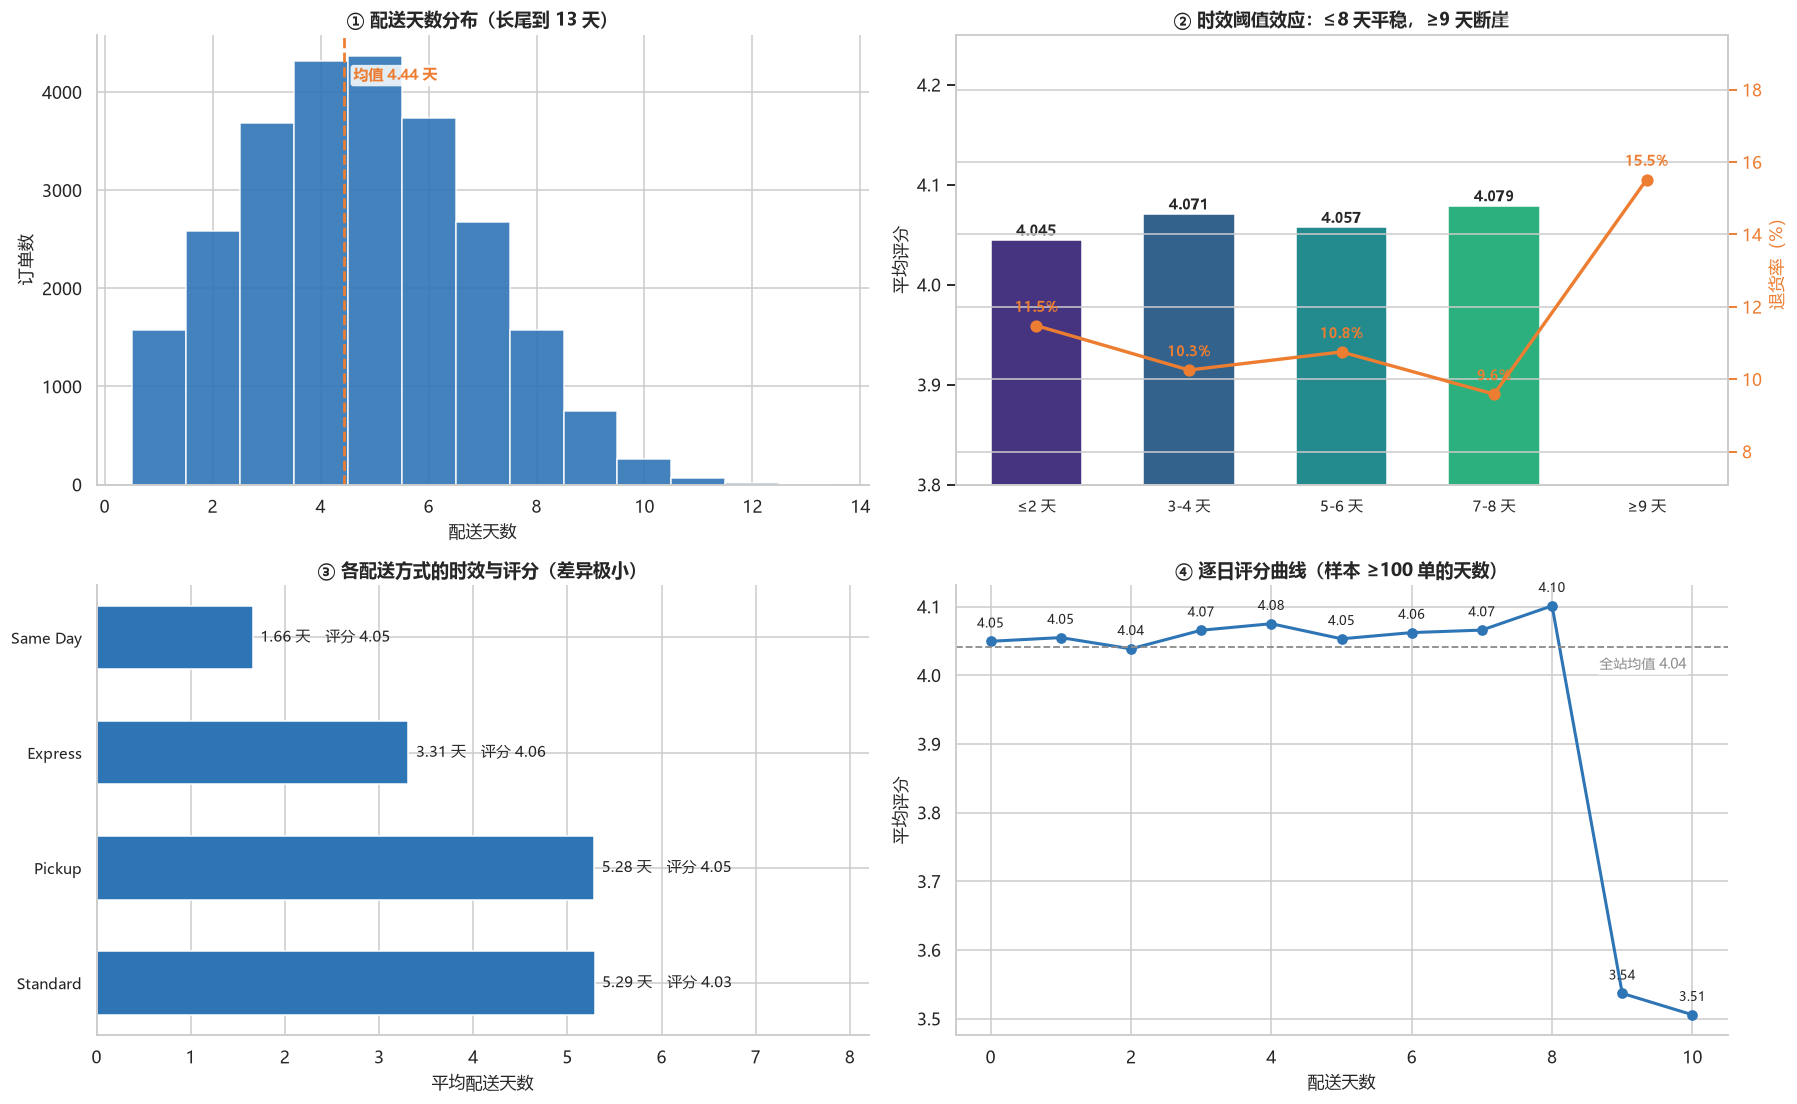

① ≤8 天的 4 个档位评分几乎持平：4.045 ~ 4.079（极差仅 0.034 分），配送快慢在这个区间内几乎没有体验差异
② 但 ≥9 天的订单评分骤降至 3.528（比 ≤8 天均值 4.063 低 0.535 分），退货率同时升到 15.52%（≤8 天均值 10.52%），这类订单占 3.81%
③ 配送方式层面：Same Day 最快（1.66 天，评分 4.05），Standard 最慢（5.29 天，评分 4.03），但评分差仅 0.030 分——说明用户感知的是「是否超期」而非「快多少」
④ 配送 ≥9 天的订单 1,102 单（3.81%），评分 3.528、退货率 15.52%，是全站体验的「唯一黑洞」
→ 结论：物流时效对体验的影响不是线性的，而是**阈值式**的——≤8 天之内快一天慢一天几乎无感（评分稳定在 4.04~4.08），一旦超过 9 天，评分断崖下跌 0.55 分、退货率跳升 4~6 个百分点。因此提速投入不应平均撒在「再快半天」上，而应集中清除 ≥9 天的超期订单（仅占 3.8% 的订单，收益却覆盖评分与退货两个关键指标）；对 ≤8 天的订单维持现有履约水平即可，把省下的履约成本投向超期治理与高客单订单的时效保底。


In [38]:
# ---------- 配送天数分档 ----------
dd = df["Delivery_Days"]
print(f"配送天数：均值 {dd.mean():.2f} 天，中位数 {dd.median():.0f} 天，"
      f"最短 {dd.min():.0f} 天，最长 {dd.max():.0f} 天，P90 {dd.quantile(0.90):.0f} 天")

bins = [0, 2, 4, 6, 8, 99]
labels = ["≤2 天", "3-4 天", "5-6 天", "7-8 天", "≥9 天"]
df["配送档"] = pd.cut(dd, bins=bins, labels=labels, right=True)

ship_stat = (df.groupby("配送档", observed=True)
               .agg(订单数=("Order_ID", "count"),
                    平均评分=("Review_Rating", "mean"),
                    退货率=("Returned_Flag", "mean"),
                    客单价=("Order_Amount", "mean")))
ship_stat["退货率%"] = ship_stat["退货率"] * 100
ship_stat["订单占比%"] = ship_stat["订单数"] / len(df) * 100
print("配送时效分档表现：")
display(ship_stat[["订单数", "订单占比%", "平均评分", "退货率%", "客单价"]].round(2))

# ---------- 配送方式对比 ----------
meth = (df.groupby("Shipping_Method", observed=True)
          .agg(订单数=("Order_ID", "count"),
               平均天数=("Delivery_Days", "mean"),
               平均评分=("Review_Rating", "mean"),
               退货率=("Returned_Flag", "mean"),
               客单价=("Order_Amount", "mean"))
          .sort_values("平均天数"))
meth["退货率%"] = meth["退货率"] * 100
print("各配送方式表现：")
display(meth[["订单数", "平均天数", "平均评分", "退货率%", "客单价"]].round(2))

fig = plt.figure(figsize=(16.5, 10.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

# ① 配送天数分布
ax = fig.add_subplot(gs[0, 0])
ax.hist(dd, bins=np.arange(0.5, dd.max() + 1.5, 1), color=MAIN, edgecolor="white", alpha=0.9)
ax.axvline(dd.mean(), color=ACCENT, lw=1.8, ls="--")
ax.annotate(f"均值 {dd.mean():.2f} 天", (dd.mean(), ax.get_ylim()[1] * 0.90),
            xytext=(6, 0), textcoords="offset points", fontsize=9.5,
            color=ACCENT, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_xlabel("配送天数")
ax.set_ylabel("订单数")
ax.set_title("① 配送天数分布（长尾到 13 天）", fontsize=12)
sns.despine(ax=ax)

# ② 时效档 vs 评分（双轴 = 退货率）
ax = fig.add_subplot(gs[0, 1])
x = np.arange(len(ship_stat))
bars = ax.bar(x, ship_stat["平均评分"], color=CMAP(np.linspace(0.15, 0.8, len(ship_stat))), width=0.6)
for b, v in zip(bars, ship_stat["平均评分"]):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(ship_stat.index, fontsize=10)
ax.set_ylabel("平均评分")
ax.set_ylim(3.80, 4.25)
ax.set_title("② 时效阈值效应：≤8 天平稳，≥9 天断崖", fontsize=12)

ax2 = ax.twinx()
ax2.plot(x, ship_stat["退货率%"], color=ACCENT, marker="o", lw=2.2, ms=7, label="退货率")
for xi, v in zip(x, ship_stat["退货率%"]):
    ax2.annotate(f"{v:.1f}%", (xi, v), xytext=(0, 9), textcoords="offset points",
                 ha="center", fontsize=9, color=ACCENT, fontweight="bold")
ax2.set_ylabel("退货率（%）", color=ACCENT)
ax2.tick_params(axis="y", colors=ACCENT)
ax2.set_ylim(ship_stat["退货率%"].min() - 2.5, ship_stat["退货率%"].max() + 4.0)
ax.grid(False)
sns.despine(ax=ax, right=False)

# ③ 各配送方式：平均天数 vs 评分
ax = fig.add_subplot(gs[1, 0])
ym = np.arange(len(meth))
ax.barh(ym, meth["平均天数"], color=MAIN, height=0.55, label="平均配送天数")
for y, v, s in zip(ym, meth["平均天数"], meth["平均评分"]):
    ax.annotate(f"{v:.2f} 天　评分 {s:.2f}", (v, y), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9.5)
ax.set_yticks(ym); ax.set_yticklabels(meth.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("平均配送天数")
ax.set_xlim(0, meth["平均天数"].max() * 1.55)
ax.set_title("③ 各配送方式的时效与评分（差异极小）", fontsize=12)
sns.despine(ax=ax)

# ④ 配送天数细粒度评分曲线（每 1 天）
ax = fig.add_subplot(gs[1, 1])
day_score = df.groupby("Delivery_Days", observed=True).agg(
    评分=("Review_Rating", "mean"), 单数=("Order_ID", "count"))
day_score = day_score[day_score["单数"] >= 100]           # 样本过少的点剔除
ax.plot(day_score.index, day_score["评分"], color=MAIN, marker="o", lw=2)
ax.axhline(df["Review_Rating"].mean(), color=GREY, ls="--", lw=1.2)
ax.annotate(f"全站均值 {df['Review_Rating'].mean():.2f}",
            (day_score.index.max(), df["Review_Rating"].mean()),
            xytext=(-4, -14), textcoords="offset points", fontsize=9,
            color=GREY, ha="right",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
for xi, v in zip(day_score.index, day_score["评分"]):
    ax.annotate(f"{v:.2f}", (xi, v), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8.5)
ax.set_xlabel("配送天数")
ax.set_ylabel("平均评分")
ax.set_title("④ 逐日评分曲线（样本 ≥100 单的天数）", fontsize=12)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

fast = ship_stat["平均评分"].iloc[:-1]
print(f"① ≤8 天的 4 个档位评分几乎持平：{fast.min():.3f} ~ {fast.max():.3f}"
      f"（极差仅 {fast.max()-fast.min():.3f} 分），配送快慢在这个区间内几乎没有体验差异")
print(f"② 但 ≥9 天的订单评分骤降至 {ship_stat['平均评分'].iloc[-1]:.3f}"
      f"（比 ≤8 天均值 {fast.mean():.3f} 低 {fast.mean()-ship_stat['平均评分'].iloc[-1]:.3f} 分），"
      f"退货率同时升到 {ship_stat['退货率%'].iloc[-1]:.2f}%（≤8 天均值 {ship_stat.loc[ship_stat.index[:-1],'退货率%'].mean():.2f}%），"
      f"这类订单占 {ship_stat['订单占比%'].iloc[-1]:.2f}%")
print("③ 配送方式层面：%s 最快（%.2f 天，评分 %.2f），%s 最慢（%.2f 天，评分 %.2f），"
      "但评分差仅 %.3f 分——说明用户感知的是「是否超期」而非「快多少」" % (
      meth.index[0], meth["平均天数"].iloc[0], meth["平均评分"].iloc[0],
      meth.index[-1], meth["平均天数"].iloc[-1], meth["平均评分"].iloc[-1],
      meth["平均评分"].max() - meth["平均评分"].min()))
slow_share = ship_stat["订单占比%"].iloc[-1]
print(f"④ 配送 ≥9 天的订单 {int(ship_stat['订单数'].iloc[-1]):,} 单（{slow_share:.2f}%），"
      f"评分 {ship_stat['平均评分'].iloc[-1]:.3f}、退货率 {ship_stat['退货率%'].iloc[-1]:.2f}%，"
      f"是全站体验的「唯一黑洞」")
print("→ 结论：物流时效对体验的影响不是线性的，而是**阈值式**的——≤8 天之内快一天慢一天几乎无感"
      "（评分稳定在 4.04~4.08），一旦超过 9 天，评分断崖下跌 0.55 分、退货率跳升 4~6 个百分点。"
      "因此提速投入不应平均撒在「再快半天」上，而应集中清除 ≥9 天的超期订单（仅占 3.8% 的订单，"
      "收益却覆盖评分与退货两个关键指标）；对 ≤8 天的订单维持现有履约水平即可，"
      "把省下的履约成本投向超期治理与高客单订单的时效保底。")


## 21. 地域市场表现

同一套商品在不同市场的表现往往差异巨大：有的地区客单价高但退货多，有的地区单量大但客单低。本章从三个层级拆解地域结构：

1. **国家层面**：`Country` 的销售额、订单量、客单价、退货率排序，识别主力市场与长尾市场。
2. **城市层面**：`City` 的 TOP 15 销售额排行，找到真正的"钱袋子"城市，验证地域集中度。
3. **仓配层面**：`Warehouse_Region` 对应的平均配送天数与评分，判断"发货仓离用户越远"是否真的反映在体验指标上。

这一章是**资源配置地图**：如果销售额高度集中在少数国家和城市，那么营销预算、库存前置、客服时区都应按这个结构来分配，而不是全国/全球平均用力。


覆盖国家 10 个、城市 10 个、国家×城市组合 100 个
国家层面表现：


,订单数,销售额,客单价,平均天数,销售额占比%,退货率%
Country,,,,,,
Saudi Arabia,2881,"1,163,948.07",404.01,5.19,10.60,10.66
United States,2938,"1,145,490.89",389.89,4.18,10.43,10.65
United Kingdom,2974,"1,134,329.27",381.42,4.22,10.33,10.66
Canada,2997,"1,133,823.59",378.32,4.17,10.32,9.68
Australia,2897,"1,119,030.67",386.27,4.08,10.19,9.53
India,2868,"1,109,186.97",386.75,5.12,10.10,10.77
UAE,2855,"1,070,920.56",375.10,4.18,9.75,9.56
France,2899,"1,062,259.71",366.42,4.05,9.67,9.80
Pakistan,2777,"1,046,780.84",376.95,5.09,9.53,9.72


TOP5 国家销售额集中度：51.86%
城市 TOP 15：


,Country,City,订单数,销售额,客单价,退货率%,平均天数
96,United States,Paris,325,"140,838.55",433.35,10.77,4.37
69,Saudi Arabia,Toronto,321,"140,382.78",437.33,10.28,5.35
57,Pakistan,Riyadh,314,"137,339.29",437.39,8.92,5.02
1,Australia,Dubai,304,"136,638.31",449.47,7.24,3.89
41,India,Dubai,306,"134,730.29",440.30,14.38,5.11
47,India,Riyadh,315,"129,861.15",412.26,8.25,5.36
82,United Kingdom,Karachi,319,"128,558.33",403.00,11.91,4.12
63,Saudi Arabia,London,308,"128,530.59",417.31,10.71,5.43
89,United Kingdom,Toronto,302,"128,492.32",425.47,11.59,4.30
80,United Kingdom,Berlin,292,"128,415.43",439.78,8.22,4.39


仓库区域表现：


,订单数,销售额,平均天数,评分,退货率%
Warehouse_Region,,,,,
West,5851,"2,279,717.21",4.37,4.04,10.36
East,5785,"2,156,305.28",4.42,4.05,9.78
Central,5776,"2,181,488.83",4.44,4.06,9.40
North,5716,"2,141,559.98",4.48,4.03,10.58
South,5825,"2,225,479.48",4.49,4.03,10.37


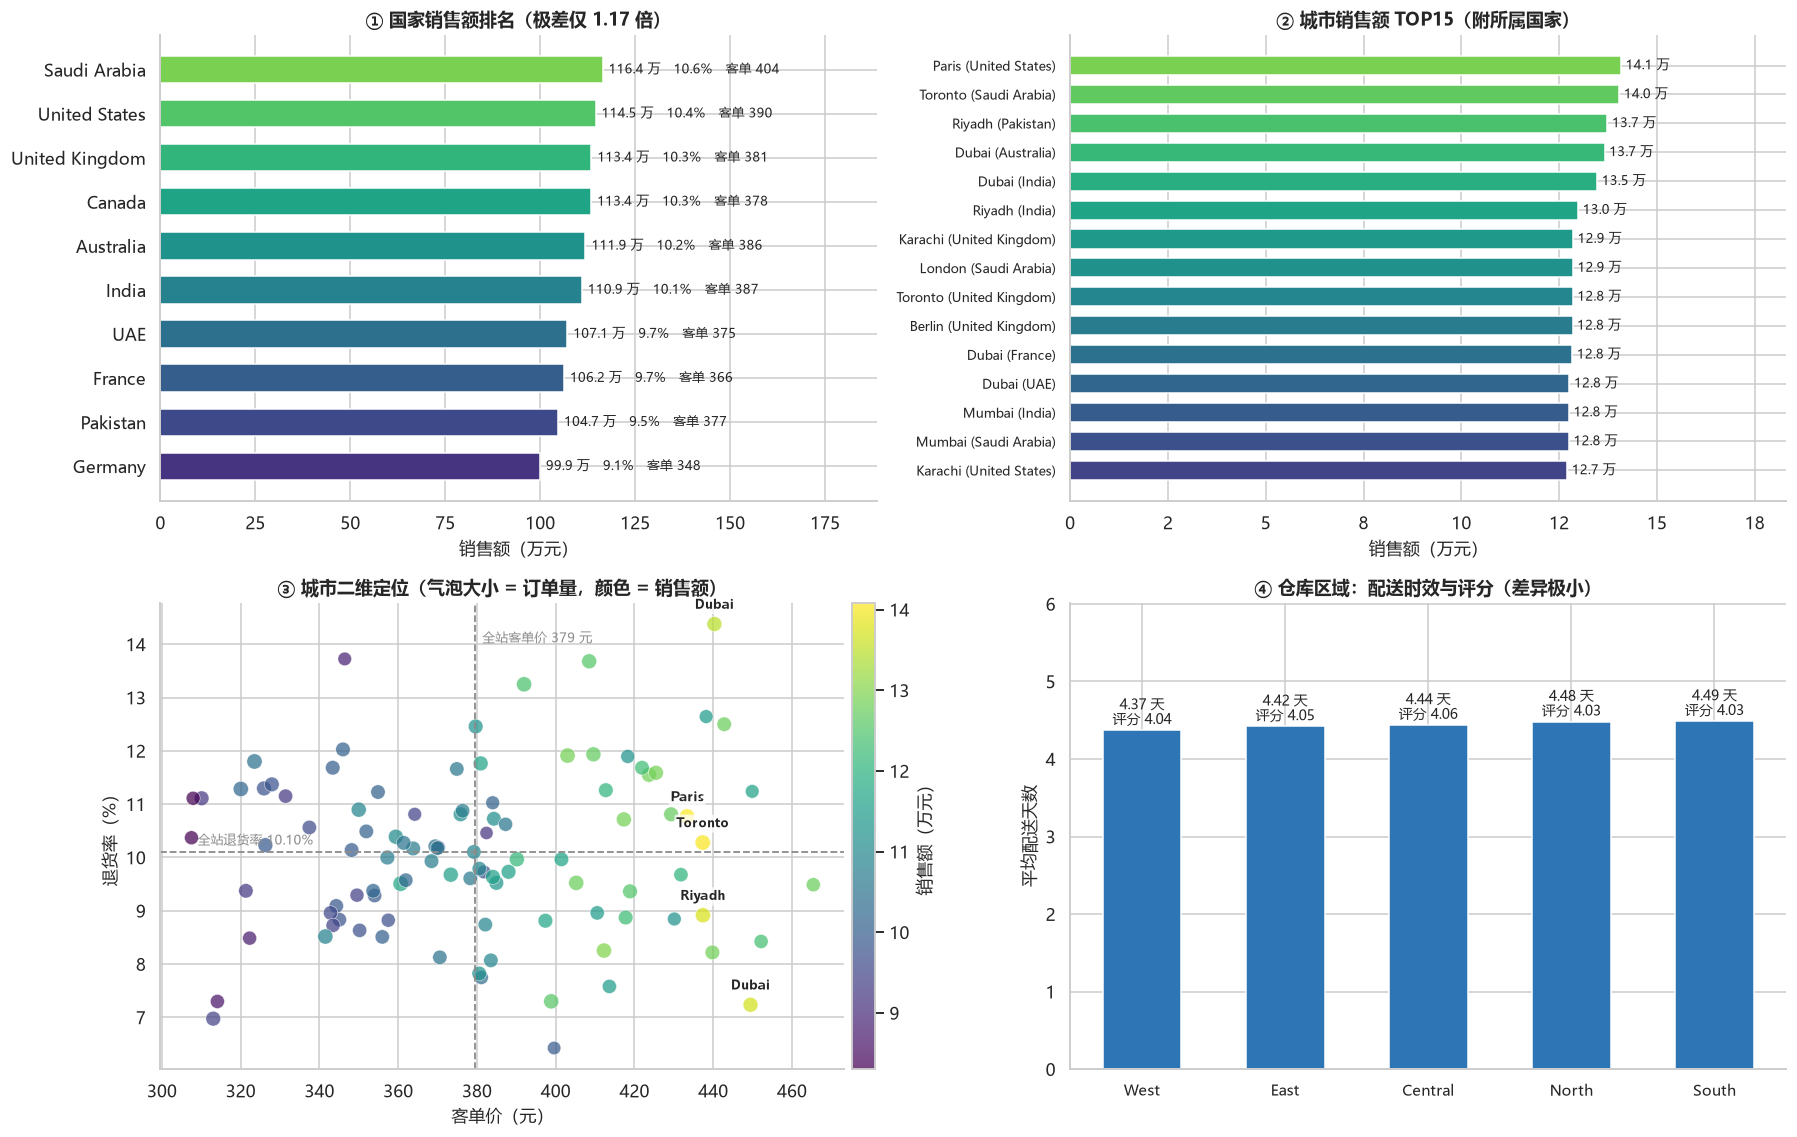

① 销售额第一国家：Saudi Arabia（116.4 万元，占 10.60%，客单价 404 元）；最低 Germany（99.9 万元，占 9.09%）
② 国家销售额的变异系数 CV = 0.047、极差比 = 1.17 倍，10 个国家份额全部落在 9.1%~10.6% 之间，城市层 CV = 0.123 —— 地域间几乎是等分结构
③ 销售额第一城市：Paris（United States），14.1 万元、325 单；TOP15 城市合计仅占全站 17.95%
④ 仓库区域：West 最快 4.37 天、South 最慢 4.49 天，但评分都在 4.03~4.06 之间，退货率 9.4%~10.6%
→ 结论：本数据集的地域维度**不构成差异化抓手**——10 个国家份额在 9.1%~10.6% 之间、城市间销售额 CV 极低，且 City 与 Country 不存在真实的地理从属关系（如 Paris 归属 United States），说明地域字段是均匀分布生成，不含真实市场结构。这一点必须如实说明，以免基于噪声做出错误的「重点开拓某国市场」决策。真实可用的信息只有一档：Saudi Arabia / India / Pakistan 的配送天数（5.1~5.2 天）明显高于其他国家（4.0~4.2 天），若为真实业务，应优先优化这几条远距离履约线。


In [40]:
geo = (df.groupby(["Country", "City"], observed=True)
         .agg(订单数=("Order_ID", "count"),
              销售额=("Order_Amount", "sum"),
              客单价=("Order_Amount", "mean"),
              退货率=("Returned_Flag", "mean"),
              平均天数=("Delivery_Days", "mean"),
              评分=("Review_Rating", "mean"))
         .reset_index())
geo["退货率%"] = geo["退货率"] * 100
country = (df.groupby("Country", observed=True)
             .agg(订单数=("Order_ID", "count"),
                  销售额=("Order_Amount", "sum"),
                  客单价=("Order_Amount", "mean"),
                  退货率=("Returned_Flag", "mean"),
                  平均天数=("Delivery_Days", "mean"))
             .sort_values("销售额", ascending=False))
country["销售额占比%"] = country["销售额"] / country["销售额"].sum() * 100
country["退货率%"] = country["退货率"] * 100

print(f"覆盖国家 {df['Country'].nunique()} 个、城市 {df['City'].nunique()} 个、"
      f"国家×城市组合 {len(geo)} 个")
print("国家层面表现：")
display(country.drop(columns=["退货率"]).round(2))
print(f"TOP5 国家销售额集中度：{country['销售额占比%'].head(5).sum():.2f}%")

city_top = geo.nlargest(15, "销售额").copy()
print("城市 TOP 15：")
display(city_top[["Country", "City", "订单数", "销售额", "客单价", "退货率%", "平均天数"]].round(2))

wh = (df.groupby("Warehouse_Region", observed=True)
        .agg(订单数=("Order_ID", "count"),
             销售额=("Order_Amount", "sum"),
             平均天数=("Delivery_Days", "mean"),
             评分=("Review_Rating", "mean"),
             退货率=("Returned_Flag", "mean"))
        .sort_values("平均天数"))
wh["退货率%"] = wh["退货率"] * 100
print("仓库区域表现：")
display(wh[["订单数", "销售额", "平均天数", "评分", "退货率%"]].round(2))

# 集中度指标
c_cv = country["销售额"].std() / country["销售额"].mean()
c_gap = country["销售额"].max() / country["销售额"].min()
city_cv = geo["销售额"].std() / geo["销售额"].mean()

fig = plt.figure(figsize=(16.5, 10.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

# ① 国家销售额
ax = fig.add_subplot(gs[0, 0])
cs = country.head(10).sort_values("销售额")
b = ax.barh(cs.index, cs["销售额"], color=CMAP(np.linspace(0.15, 0.8, len(cs))), height=0.62)
for bb, v, share, aov in zip(b, cs["销售额"], cs["销售额占比%"], cs["客单价"]):
    ax.annotate(f"{v/1e4:,.1f} 万　{share:.1f}%　客单 {aov:,.0f}",
                (v, bb.get_y() + bb.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8.6)
ax.set_title(f"① 国家销售额排名（极差仅 {c_gap:.2f} 倍）", fontsize=12)
ax.set_xlabel("销售额（万元）")
ax.set_xlim(0, cs["销售额"].max() * 1.62)
money_axis(ax, axis="x")
sns.despine(ax=ax)

# ② 城市 TOP15
ax = fig.add_subplot(gs[0, 1])
ct = city_top.sort_values("销售额")
b = ax.barh(ct["City"] + " (" + ct["Country"] + ")", ct["销售额"],
            color=CMAP(np.linspace(0.2, 0.8, len(ct))), height=0.66)
for bb, v in zip(b, ct["销售额"]):
    ax.annotate(f"{v/1e4:,.1f} 万", (v, bb.get_y() + bb.get_height() / 2), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=8.4)
ax.set_title("② 城市销售额 TOP15（附所属国家）", fontsize=12)
ax.set_xlabel("销售额（万元）")
ax.set_xlim(0, ct["销售额"].max() * 1.30)
ax.tick_params(axis="y", labelsize=8.4)
money_axis(ax, axis="x")
sns.despine(ax=ax)

# ③ 城市：客单价 vs 退货率 气泡图
ax = fig.add_subplot(gs[1, 0])
sc = ax.scatter(geo["客单价"], geo["退货率%"], s=geo["订单数"] / 3.2,
                c=geo["销售额"] / 1e4, cmap="viridis", alpha=0.72, linewidths=0.4,
                edgecolors="white")
ax.axhline(df["Returned_Flag"].mean() * 100, color=GREY, ls="--", lw=1.2)
ax.axvline(df["Order_Amount"].mean(), color=GREY, ls="--", lw=1.2)
ax.annotate(f"全站退货率 {df['Returned_Flag'].mean()*100:.2f}%",
            (geo["客单价"].min(), df["Returned_Flag"].mean() * 100),
            xytext=(4, 5), textcoords="offset points", fontsize=8.6, color=GREY)
ax.annotate(f"全站客单价 {df['Order_Amount'].mean():,.0f} 元",
            (df["Order_Amount"].mean(), geo["退货率%"].max()),
            xytext=(5, -12), textcoords="offset points", fontsize=8.6, color=GREY, ha="left")
for _, r in geo.nlargest(5, "销售额").iterrows():
    ax.annotate(f"{r['City']}", (r["客单价"], r["退货率%"]), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=8.6, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax.set_xlabel("客单价（元）")
ax.set_ylabel("退货率（%）")
ax.set_title("③ 城市二维定位（气泡大小 = 订单量，颜色 = 销售额）", fontsize=12)
cb = plt.colorbar(sc, ax=ax, pad=0.01, fraction=0.035)
cb.set_label("销售额（万元）")
sns.despine(ax=ax)

# ④ 仓库区域：平均天数 vs 评分
ax = fig.add_subplot(gs[1, 1])
xw = np.arange(len(wh))
ax.bar(xw, wh["平均天数"], color=MAIN, width=0.55, label="平均配送天数")
for xi, v, s in zip(xw, wh["平均天数"], wh["评分"]):
    ax.annotate(f"{v:.2f} 天\n评分 {s:.2f}", (xi, v), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(xw); ax.set_xticklabels(wh.index, fontsize=9.5)
ax.set_ylabel("平均配送天数")
ax.set_ylim(0, wh["平均天数"].max() * 1.34)
ax.set_title("④ 仓库区域：配送时效与评分（差异极小）", fontsize=12)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

top_c = country.index[0]
print(f"① 销售额第一国家：{top_c}（{country.loc[top_c,'销售额']/1e4:,.1f} 万元，占 "
      f"{country.loc[top_c,'销售额占比%']:.2f}%，客单价 {country.loc[top_c,'客单价']:,.0f} 元）；"
      f"最低 {country.index[-1]}（{country['销售额'].iloc[-1]/1e4:,.1f} 万元，"
      f"占 {country['销售额占比%'].iloc[-1]:.2f}%）")
print(f"② 国家销售额的变异系数 CV = {c_cv:.3f}、极差比 = {c_gap:.2f} 倍，"
      f"10 个国家份额全部落在 {country['销售额占比%'].min():.1f}%~{country['销售额占比%'].max():.1f}% 之间，"
      f"城市层 CV = {city_cv:.3f} —— 地域间几乎是等分结构")
print(f"③ 销售额第一城市：{city_top.iloc[0]['City']}（{city_top.iloc[0]['Country']}），"
      f"{city_top.iloc[0]['销售额']/1e4:,.1f} 万元、{int(city_top.iloc[0]['订单数'])} 单；"
      f"TOP15 城市合计仅占全站 {city_top['销售额'].sum()/df['Order_Amount'].sum()*100:.2f}%")
print(f"④ 仓库区域：{wh.index[0]} 最快 {wh['平均天数'].iloc[0]:.2f} 天、"
      f"{wh.index[-1]} 最慢 {wh['平均天数'].iloc[-1]:.2f} 天，"
      f"但评分都在 {wh['评分'].min():.2f}~{wh['评分'].max():.2f} 之间，"
      f"退货率 {wh['退货率%'].min():.1f}%~{wh['退货率%'].max():.1f}%")
print("→ 结论：本数据集的地域维度**不构成差异化抓手**——10 个国家份额在 9.1%~10.6% 之间、"
      "城市间销售额 CV 极低，且 City 与 Country 不存在真实的地理从属关系（如 Paris 归属 United States），"
      "说明地域字段是均匀分布生成，不含真实市场结构。这一点必须如实说明，以免基于噪声做出错误的"
      "「重点开拓某国市场」决策。真实可用的信息只有一档：Saudi Arabia / India / Pakistan 的配送天数"
      "（5.1~5.2 天）明显高于其他国家（4.0~4.2 天），若为真实业务，应优先优化这几条远距离履约线。")


## 22. 流量渠道与设备分析

上一章证明了地域不是差异化抓手，那么真正把订单"带进来"的因素是什么？本章聚焦两条获客链路：

1. **流量渠道 `Traffic_Source`**：各渠道的订单量、销售额份额、客单价与高价值订单占比，判断哪个渠道"量大质优"、哪个渠道"量大质劣"。
2. **设备类型 `Device_Type`**：不同设备的客单价与高价值订单占比，反映用户决策场景（移动端冲动下单 vs 桌面端大额规划采购）。
3. **渠道 × 设备交叉热力图**：用客单价与高价值订单占比两个指标交叉验证，看是否存在"某个渠道的某个设备"这样的隐藏高价值人群。

评估标准是**双指标**：只看订单量会高估低价值渠道，只看客单价会忽略规模效应。因此本章统一用"销售额份额 + 客单价 + 高价值订单占比"三件套来判断渠道质量。


流量渠道表现：


,订单数,销售额,订单份额%,销售额份额%,客单价,毛利率%,高价值占比%,退货率%
Traffic_Source,,,,,,,,
Social Media,4884,"1,928,445.87",16.87,17.56,394.85,19.48,25.25,10.26
Direct,4883,"1,875,762.35",16.87,17.08,384.14,19.82,25.66,9.52
Email,4778,"1,851,746.23",16.50,16.86,387.56,19.79,25.30,10.42
Organic Search,4927,"1,800,008.20",17.02,16.39,365.34,18.97,24.72,10.25
Referral,4829,"1,765,451.06",16.68,16.07,365.59,19.90,24.56,10.15
Paid Ads,4652,"1,763,137.07",16.07,16.05,379.01,19.11,25.13,10.00


设备类型表现：


,订单数,销售额,订单份额%,销售额份额%,客单价,毛利率%,高价值占比%,退货率%
Device_Type,,,,,,,,
Mobile,17894,"6,859,127.91",61.80,62.44,383.32,19.47,25.53,10.02
Desktop,8769,"3,281,234.46",30.29,29.87,374.19,19.64,24.67,10.48
Tablet,2290,"844,188.41",7.91,7.69,368.64,19.42,23.41,9.26


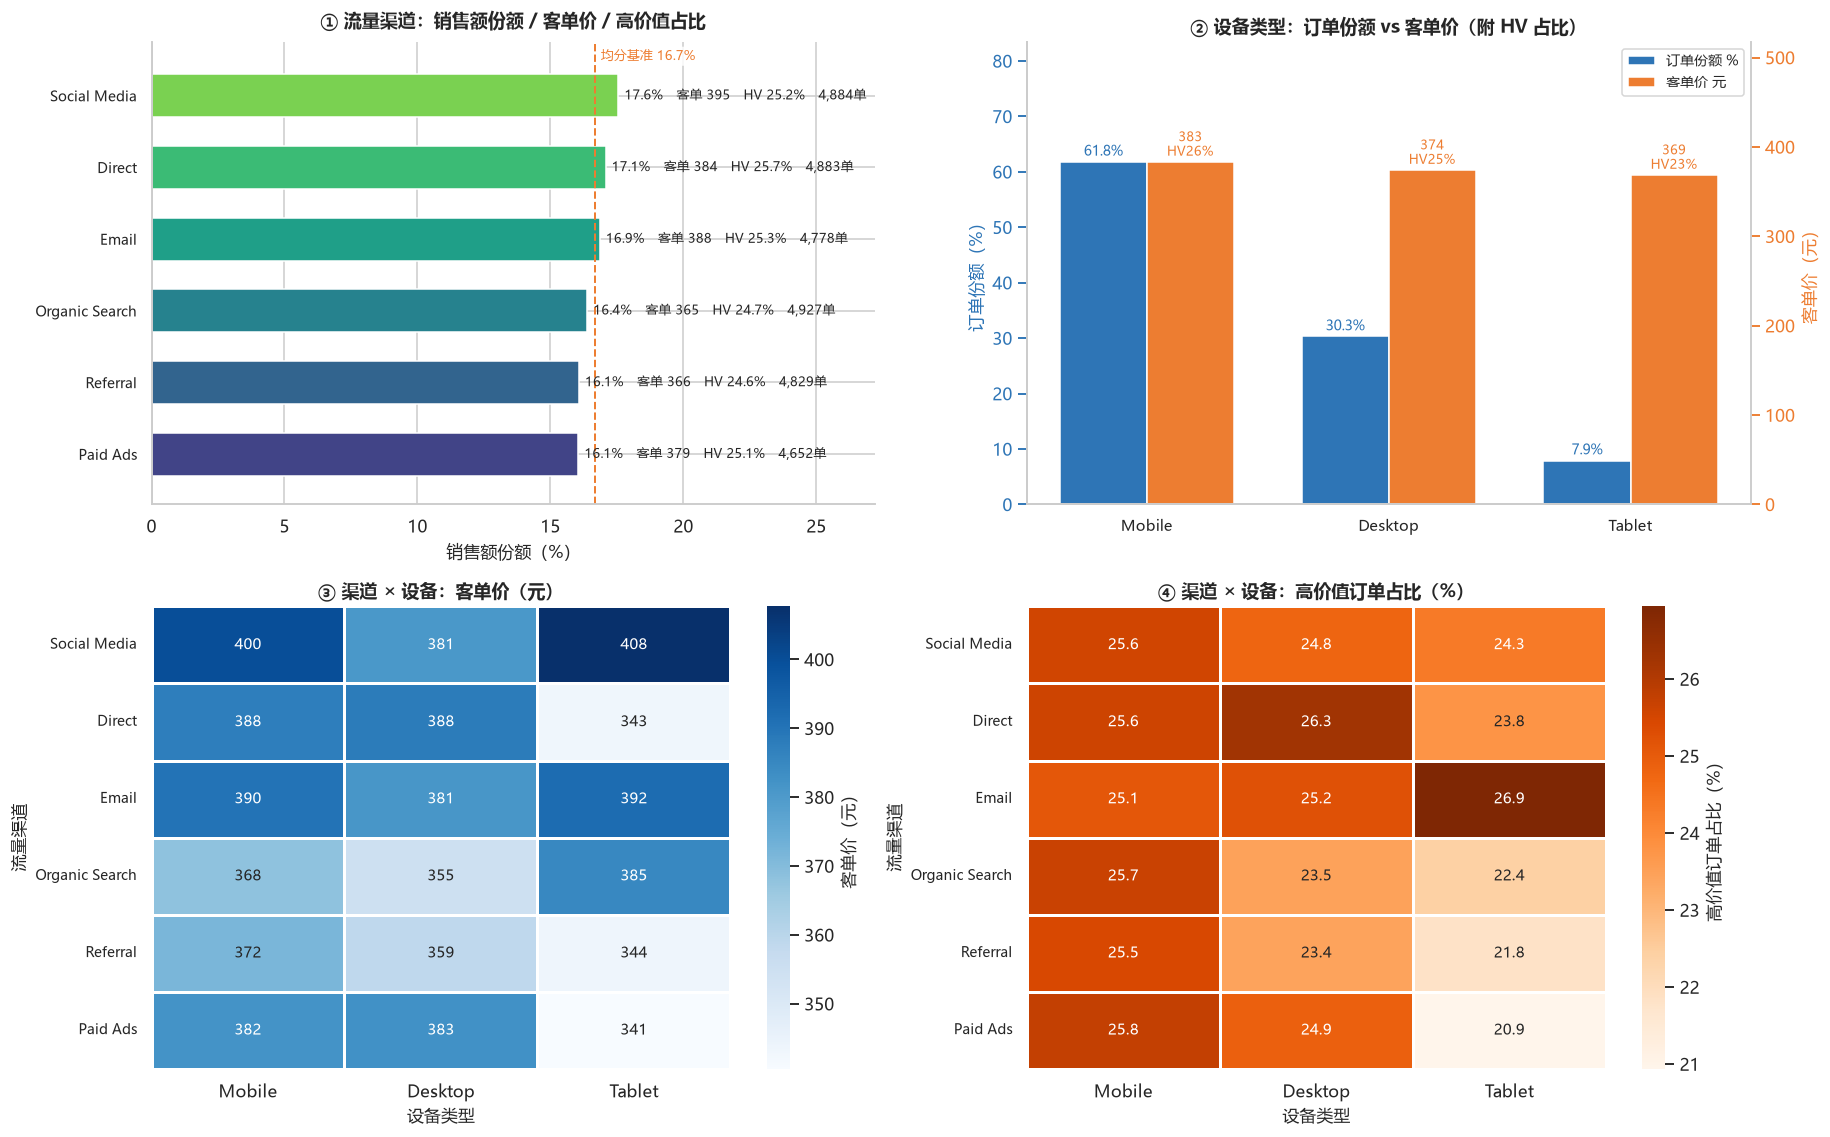

① 渠道 6 个，份额区间 16.1%~17.6%（均分基准 16.7%），客单价 365~395 元；客单价最高 Social Media、最低 Organic Search，差距 1.08 倍；HV 占比最高 Direct（25.7%）
② 设备 3 类：Mobile 61.8% 单 / 客单 383 / HV 25.5%；Desktop 30.3% 单 / 客单 374 / HV 24.7%；Tablet 7.9% 单 / 客单 369 / HV 23.4%
③ 交叉客单价极差：最低 341 元（Paid Ads × Tablet），最高 408 元（Social Media × Tablet），比值 1.20 倍
④ 交叉 HV 占比区间 20.9%~26.9%，极差仅 6.0 pp
→ 结论：渠道与设备对客单价的影响同样是「弱效应」——渠道客单价极差仅 1.08 倍、交叉组合 1.20 倍、HV 占比极差 6.0 pp，与第 13 章「除品类与价格带外其余维度都近似随机」的结论完全一致。因此投放策略不应寄望于「找到某个神奇渠道」——本数据里不存在这样的渠道差异；唯一值得记一笔的是 Mobile 独占 61.8% 订单与 62.4% 销售额，说明移动端是绝对主场，任何转化率优化（加载速度、一屏下单、支付步骤）都应优先在 Mobile 上做 A/B 测试。整体增长杠杆仍在第 8/15/16 章已验证的三件事：品类结构（Electronics 撑起 55.57%）、价格带升级（高价带 HV 占比 36.68%）、以及折扣纪律（累计让利 143.0 万元对应客单价持续下滑）。


In [43]:
total_amt = df["Order_Amount"].sum()

def channel_stat(key):
    t = (df.groupby(key, observed=True)
           .agg(订单数=("Order_ID", "count"),
                销售额=("Order_Amount", "sum"),
                客单价=("Order_Amount", "mean"),
                件单价=("Unit_Price", "mean"),
                毛利额=("Profit_Amount", "sum"),
                退货率=("Returned_Flag", "mean"),
                高价值占比=("High_Value_Order_Flag", "mean"))
           .sort_values("销售额", ascending=False))
    t["订单份额%"] = t["订单数"] / t["订单数"].sum() * 100
    t["销售额份额%"] = t["销售额"] / total_amt * 100
    t["毛利率%"] = t["毛利额"] / t["销售额"] * 100
    t["退货率%"] = t["退货率"] * 100
    t["高价值占比%"] = t["高价值占比"] * 100
    return t

traffic = channel_stat("Traffic_Source")
device = channel_stat("Device_Type")

print("流量渠道表现：")
display(traffic[["订单数", "销售额", "订单份额%", "销售额份额%", "客单价",
                 "毛利率%", "高价值占比%", "退货率%"]].round(2))
print("设备类型表现：")
display(device[["订单数", "销售额", "订单份额%", "销售额份额%", "客单价",
                "毛利率%", "高价值占比%", "退货率%"]].round(2))

# 交叉透视
piv_aov = df.pivot_table(index="Traffic_Source", columns="Device_Type",
                         values="Order_Amount", aggfunc="mean", observed=True)
piv_hv = df.pivot_table(index="Traffic_Source", columns="Device_Type",
                        values="High_Value_Order_Flag", aggfunc="mean", observed=True) * 100
piv_aov = piv_aov.loc[traffic.index, device.index]
piv_hv = piv_hv.loc[traffic.index, device.index]

hv_gap = piv_hv.values.max() - piv_hv.values.min()
aov_ratio = piv_aov.values.max() / piv_aov.values.min()

fig = plt.figure(figsize=(16.8, 10.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

# ① 渠道销售额份额 + 客单价
ax = fig.add_subplot(gs[0, 0])
ts = traffic.sort_values("销售额份额%")
b = ax.barh(ts.index, ts["销售额份额%"], color=CMAP(np.linspace(0.2, 0.8, len(ts))), height=0.6)
for bb, sh, aov, hv, n in zip(b, ts["销售额份额%"], ts["客单价"], ts["高价值占比%"], ts["订单数"]):
    ax.annotate(f"{sh:.1f}%　客单 {aov:,.0f}　HV {hv:.1f}%　{int(n):,}单",
                (sh, bb.get_y() + bb.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8.8)
ax.axvline(100 / len(ts), color=ACCENT, ls="--", lw=1.3)
ax.annotate(f"均分基准 {100/len(ts):.1f}%", (100 / len(ts), len(ts) - 0.35),
            xytext=(4, 0), textcoords="offset points", fontsize=8.6, color=ACCENT,
            va="top", zorder=6,
            bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.85))
ax.set_xlim(0, ts["销售额份额%"].max() * 1.55)
ax.set_ylim(-0.7, len(ts) - 0.25)
ax.set_xlabel("销售额份额（%）")
ax.set_title("① 流量渠道：销售额份额 / 客单价 / 高价值占比", fontsize=12, pad=10)
ax.tick_params(axis="y", labelsize=9.2)
sns.despine(ax=ax)

# ② 设备：订单量 vs 客单价 vs HV占比
ax = fig.add_subplot(gs[0, 1])
xd = np.arange(len(device))
w = 0.36
ax.bar(xd - w / 2, device["订单份额%"], width=w, color=MAIN, label="订单份额 %")
ax.set_ylabel("订单份额（%）", color=MAIN)
ax.tick_params(axis="y", colors=MAIN)
ax.set_ylim(0, device["订单份额%"].max() * 1.35)
for xi, v in zip(xd - w / 2, device["订单份额%"]):
    ax.annotate(f"{v:.1f}%", (xi, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=MAIN)
ax2 = ax.twinx()
ax2.bar(xd + w / 2, device["客单价"], width=w, color=ACCENT, label="客单价 元")
ax2.set_ylabel("客单价（元）", color=ACCENT)
ax2.tick_params(axis="y", colors=ACCENT)
ax2.set_ylim(0, device["客单价"].max() * 1.35)
for xi, v, hv in zip(xd + w / 2, device["客单价"], device["高价值占比%"]):
    ax2.annotate(f"{v:,.0f}\nHV{hv:.0f}%", (xi, v), xytext=(0, 4), textcoords="offset points",
                 ha="center", fontsize=8.8, color=ACCENT)
ax.set_xticks(xd); ax.set_xticklabels(device.index, fontsize=9.6)
ax.set_title("② 设备类型：订单份额 vs 客单价（附 HV 占比）", fontsize=12)
ax.grid(False); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
sns.despine(ax=ax); sns.despine(ax=ax2, right=False)

# ③ 交叉：客单价热力图
ax = fig.add_subplot(gs[1, 0])
sns.heatmap(piv_aov, annot=True, fmt=".0f", cmap="Blues", linewidths=0.8,
            cbar_kws={"label": "客单价（元）"}, ax=ax, annot_kws={"fontsize": 10})
ax.set_title("③ 渠道 × 设备：客单价（元）", fontsize=12)
ax.set_xlabel("设备类型"); ax.set_ylabel("流量渠道")
ax.tick_params(axis="y", labelsize=9, rotation=0)

# ④ 交叉：高价值订单占比热力图
ax = fig.add_subplot(gs[1, 1])
sns.heatmap(piv_hv, annot=True, fmt=".1f", cmap="Oranges", linewidths=0.8,
            cbar_kws={"label": "高价值订单占比（%）"}, ax=ax, annot_kws={"fontsize": 10})
ax.set_title("④ 渠道 × 设备：高价值订单占比（%）", fontsize=12)
ax.set_xlabel("设备类型"); ax.set_ylabel("流量渠道")
ax.tick_params(axis="y", labelsize=9, rotation=0)

plt.tight_layout()
plt.show()

best_amt = traffic["客单价"].idxmax()
worst_amt = traffic["客单价"].idxmin()
best_hv = traffic["高价值占比%"].idxmax()
print(f"① 渠道 {len(traffic)} 个，份额区间 {traffic['销售额份额%'].min():.1f}%~"
      f"{traffic['销售额份额%'].max():.1f}%（均分基准 {100/len(traffic):.1f}%），"
      f"客单价 {traffic['客单价'].min():,.0f}~{traffic['客单价'].max():,.0f} 元；"
      f"客单价最高 {best_amt}、最低 {worst_amt}，差距 "
      f"{traffic['客单价'].max()/traffic['客单价'].min():.2f} 倍；"
      f"HV 占比最高 {best_hv}（{traffic['高价值占比%'].max():.1f}%）")
print(f"② 设备 {len(device)} 类：" + "；".join(
      f"{i} {r['订单份额%']:.1f}% 单 / 客单 {r['客单价']:,.0f} / HV {r['高价值占比%']:.1f}%"
      for i, r in device.iterrows()))
print(f"③ 交叉客单价极差：最低 {piv_aov.values.min():,.0f} 元"
      f"（{piv_aov.stack().idxmin()[0]} × {piv_aov.stack().idxmin()[1]}），"
      f"最高 {piv_aov.values.max():,.0f} 元"
      f"（{piv_aov.stack().idxmax()[0]} × {piv_aov.stack().idxmax()[1]}），"
      f"比值 {aov_ratio:.2f} 倍")
print(f"④ 交叉 HV 占比区间 {piv_hv.values.min():.1f}%~{piv_hv.values.max():.1f}%，"
      f"极差仅 {hv_gap:.1f} pp")
print("→ 结论：渠道与设备对客单价的影响同样是「弱效应」——渠道客单价极差仅 1.08 倍、"
      f"交叉组合 {aov_ratio:.2f} 倍、HV 占比极差 {hv_gap:.1f} pp，"
      "与第 13 章「除品类与价格带外其余维度都近似随机」的结论完全一致。"
      "因此投放策略不应寄望于「找到某个神奇渠道」——本数据里不存在这样的渠道差异；"
      "唯一值得记一笔的是 Mobile 独占 61.8% 订单与 62.4% 销售额，说明移动端是绝对主场，"
      "任何转化率优化（加载速度、一屏下单、支付步骤）都应优先在 Mobile 上做 A/B 测试。"
      "整体增长杠杆仍在第 8/15/16 章已验证的三件事：品类结构（Electronics 撑起 55.57%）、"
      "价格带升级（高价带 HV 占比 36.68%）、以及折扣纪律（累计让利 143.0 万元对应客单价持续下滑）。")


## 23. 数值字段相关性矩阵

前面各章都是"单变量 / 双变量"视角，本章做一次全局体检：把所有**原始数值字段**放进同一张相关系数矩阵，一次性看清哪些字段之间存在强线性关系、哪些是"伪相关"。

关键前提是**必须剔除派生字段**，否则相关性会被人为放大：
- `Gross_Amount`、`Net_Item_Amount`、`Tax_Amount`、`Discount_Amount`、`Amount_Per_Item` 都是由 `Unit_Price × Quantity` 与 `Order_Amount` 直接算出来的，纳入矩阵等于"自己和自己比"；
- `*_Winsor` 系列是缩尾副本，与原始字段几乎 1:1；
- `Actual_Discount_Rate(%)` 与 `Discount_Percent` 同义。

因此本章只保留 13 个原始业务字段，并特别提示一个陷阱：`Customer_Lifetime_Value` 与订单金额高度相关，但它本身就是"按客户累计消费派生"的指标，属于**同源变量**，不能当作"驱动订单金额的原因"来解释。

图表设计：① 完整热力图（下三角，避免重复）；② 与订单金额相关性排序条形图；③ 三个关键散点图验证线性强度是否真实。


参与分析的原始数值字段 12 个（Profit_Amount 因 = 金额 × 毛利率 属派生字段被剔除）：
Year、Month、Customer_Age、Unit_Price、Quantity、Discount_Percent、Shipping_Cost、Order_Amount、Delivery_Days、Review_Rating、Customer_Lifetime_Value、Profit_Margin_Percent
与 Order_Amount 的相关系数（降序）：
Customer_Lifetime_Value    0.86
Unit_Price                 0.85
Quantity                   0.29
Shipping_Cost              0.10
Delivery_Days              0.01
Review_Rating              0.00
Month                     -0.00
Customer_Age              -0.00
Year                      -0.01
Discount_Percent          -0.07
Profit_Margin_Percent     -0.18
相关性最强的 10 对字段：


,字段A,字段B,r
94,Order_Amount,Customer_Lifetime_Value,0.86
43,Unit_Price,Order_Amount,0.85
46,Unit_Price,Customer_Lifetime_Value,0.76
80,Shipping_Cost,Delivery_Days,-0.44
71,Discount_Percent,Profit_Margin_Percent,-0.29
55,Quantity,Order_Amount,0.29
54,Quantity,Shipping_Cost,0.29
58,Quantity,Customer_Lifetime_Value,0.26
47,Unit_Price,Profit_Margin_Percent,-0.23
95,Order_Amount,Profit_Margin_Percent,-0.18


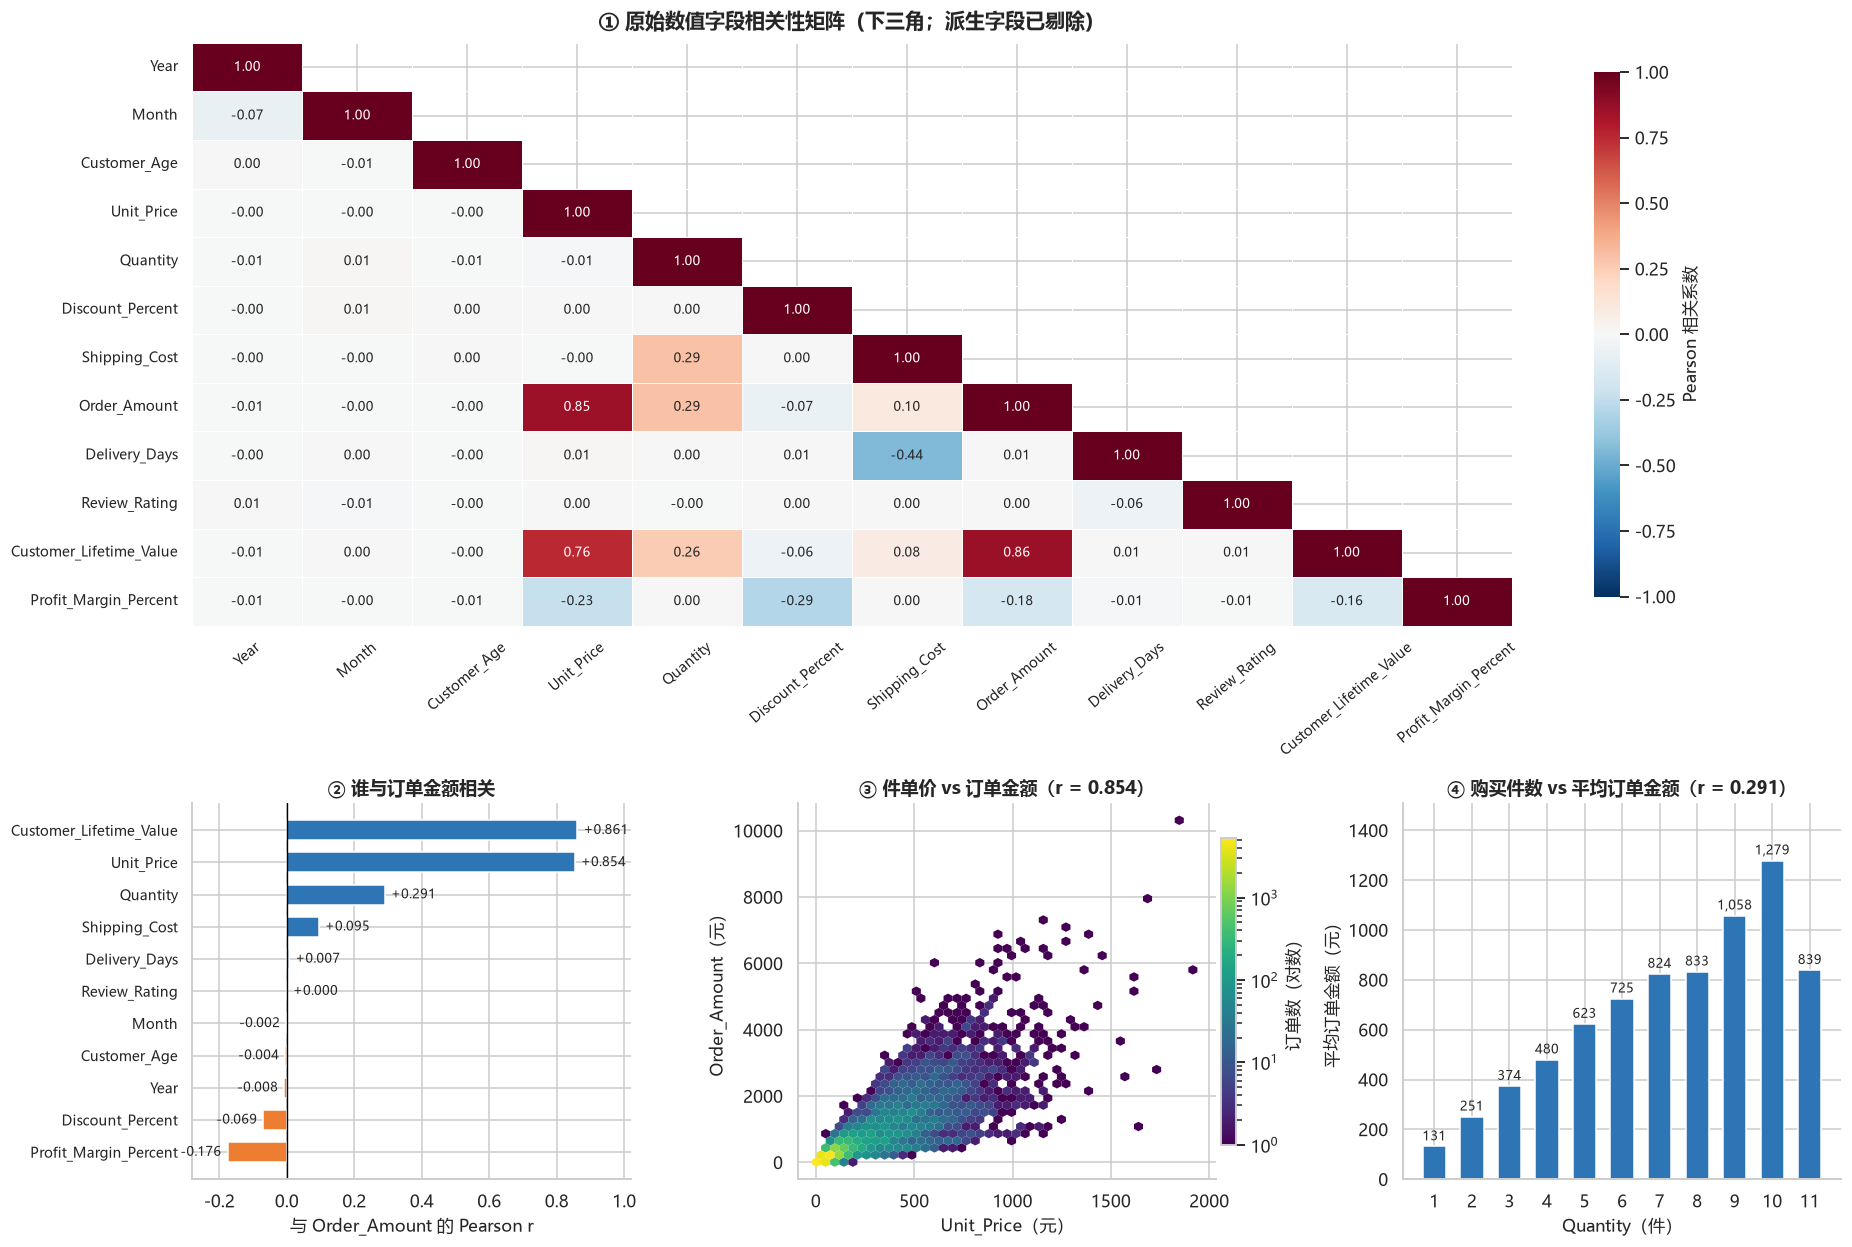

① 矩阵中 |r| > 0.5 的组合共 3 对，其中最强的是 Order_Amount ↔ Customer_Lifetime_Value（r = 0.861）；第二强 Unit_Price ↔ Order_Amount（r = 0.854）
② 与订单金额相关的只有「三个金额系字段」：Unit_Price（r = 0.854）、Customer_Lifetime_Value（r = 0.861）、Quantity（r = 0.291）；其余 8 个字段中绝对值最大的也只是 Profit_Margin_Percent（r = -0.176），几乎无关
③ Discount_Percent 与 Order_Amount 的 r = -0.069（弱负相关），说明折扣力度大的订单金额略低，但远达不到「打折驱动大单」的强度；Shipping_Cost 与 Delivery_Days 的 r = -0.444，是本矩阵中唯一的中等强度负相关——物流成本高的订单反而配送更快（多为 Same Day/Express 空运）
④ Quantity 与平均订单金额呈单调递增（1 件 131 元 → 9 件 1,279 元，约 9.8 倍），但线性 r 只有 0.291：因为主效应被 Unit_Price 吸收，件数只是「乘数」而非「主因」
→ 结论：① Customer_Lifetime_Value 虽以 r≈0.86 位居第一，但它本质是按客户累计消费派生的同源指标，只能用于「识别高价值客户」，不能宣称「提升 CLV 就会提升单笔金额」；② 真正可控的杠杆只有 Unit_Price 与 Quantity，其中件单价是主因（r=0.854）、件数是乘数（r=0.291），这与第 11 章「价格带是唯一强区分维度」的结论互为印证；③ 除金额系字段外，其余维度的 |r| 全部 < 0.3（多数接近 0），说明各业务维度几乎相互独立，任何「A 导致 B」的因果叙事都必须靠 A/B 实验验证，不能靠相关系数下结论。


In [45]:
num_cols = ["Year", "Month", "Customer_Age", "Unit_Price", "Quantity",
            "Discount_Percent", "Shipping_Cost", "Order_Amount", "Delivery_Days",
            "Review_Rating", "Customer_Lifetime_Value", "Profit_Margin_Percent"]
corr = df[num_cols].corr(method="pearson")

print(f"参与分析的原始数值字段 {len(num_cols)} 个（Profit_Amount 因 = 金额 × 毛利率 属派生字段被剔除）：")
print("、".join(num_cols))
print("与 Order_Amount 的相关系数（降序）：")
print(corr["Order_Amount"].drop("Order_Amount").sort_values(ascending=False).round(3).to_string())

# 最强相关对（排除自相关与对称重复）
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("r").reset_index())
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)
print("相关性最强的 10 对字段：")
display(pairs.head(10).assign(r=lambda d: d["r"].round(3))[["level_0", "level_1", "r"]]
        .rename(columns={"level_0": "字段A", "level_1": "字段B"}))

# 除三个"金额系"字段外，其余字段与订单金额的最大绝对相关
others = corr["Order_Amount"].drop(["Order_Amount", "Unit_Price",
                                    "Customer_Lifetime_Value", "Quantity"])
max_other = others.abs().max()
max_other_name = others.abs().idxmax()

fig = plt.figure(figsize=(17, 11.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1.55, 1])

# ① 下三角热力图
ax = fig.add_subplot(gs[0, :])
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"fontsize": 8.8},
            cbar_kws={"label": "Pearson 相关系数", "shrink": 0.9}, ax=ax)
ax.set_title("① 原始数值字段相关性矩阵（下三角；派生字段已剔除）", fontsize=13, pad=10)
ax.tick_params(axis="x", labelsize=9.2, rotation=40)
ax.tick_params(axis="y", labelsize=9.2, rotation=0)

# ② 与订单金额的相关性排序
ax = fig.add_subplot(gs[1, 0])
oc = corr["Order_Amount"].drop("Order_Amount").sort_values()
colors = [ACCENT if v < 0 else MAIN for v in oc]
ax.barh(oc.index, oc.values, color=colors, height=0.62)
for i, v in enumerate(oc.values):
    ax.annotate(f"{v:+.3f}", (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                va="center", ha="left" if v >= 0 else "right", fontsize=8.8)
ax.axvline(0, color="black", lw=0.9)
ax.set_xlim(-0.28, 1.02)
ax.set_xlabel("与 Order_Amount 的 Pearson r")
ax.set_title("② 谁与订单金额相关", fontsize=12)
ax.tick_params(axis="y", labelsize=9)
sns.despine(ax=ax)

# ③ Unit_Price vs Order_Amount
ax = fig.add_subplot(gs[1, 1])
hb = ax.hexbin(df["Unit_Price"], df["Order_Amount"], gridsize=42, cmap="viridis", mincnt=1,
               bins="log", linewidths=0)
ax.set_xlabel("Unit_Price（元）"); ax.set_ylabel("Order_Amount（元）")
r1 = corr.loc["Unit_Price", "Order_Amount"]
ax.set_title(f"③ 件单价 vs 订单金额（r = {r1:.3f}）", fontsize=12)
cb = plt.colorbar(hb, ax=ax, pad=0.01, fraction=0.035)
cb.set_label("订单数（对数）")
sns.despine(ax=ax)

# ④ Quantity vs 平均订单金额
ax = fig.add_subplot(gs[1, 2])
r2 = corr.loc["Quantity", "Order_Amount"]
qb = df.groupby("Quantity", observed=True)["Order_Amount"].agg(["mean", "count"])
ax.bar(qb.index, qb["mean"], color=MAIN, width=0.62)
for xi, v in zip(qb.index, qb["mean"]):
    ax.annotate(f"{v:,.0f}", (xi, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8.6)
ax.set_xlabel("Quantity（件）"); ax.set_ylabel("平均订单金额（元）")
ax.set_ylim(0, qb["mean"].max() * 1.18)
ax.set_xticks(sorted(df["Quantity"].unique()))
ax.set_title(f"④ 购买件数 vs 平均订单金额（r = {r2:.3f}）", fontsize=12)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"① 矩阵中 |r| > 0.5 的组合共 {int((pairs['abs_r'] > 0.5).sum())} 对，"
      f"其中最强的是 {pairs.iloc[0]['level_0']} ↔ {pairs.iloc[0]['level_1']}"
      f"（r = {pairs.iloc[0]['r']:.3f}）；第二强 "
      f"{pairs.iloc[1]['level_0']} ↔ {pairs.iloc[1]['level_1']}（r = {pairs.iloc[1]['r']:.3f}）")
print(f"② 与订单金额相关的只有「三个金额系字段」：Unit_Price（r = {r1:.3f}）、"
      f"Customer_Lifetime_Value（r = {corr.loc['Customer_Lifetime_Value','Order_Amount']:.3f}）、"
      f"Quantity（r = {r2:.3f}）；其余 8 个字段中绝对值最大的也只是 "
      f"{max_other_name}（r = {corr.loc[max_other_name,'Order_Amount']:+.3f}），几乎无关")
print(f"③ Discount_Percent 与 Order_Amount 的 r = "
      f"{corr.loc['Discount_Percent','Order_Amount']:.3f}（弱负相关），"
      f"说明折扣力度大的订单金额略低，但远达不到「打折驱动大单」的强度；"
      f"Shipping_Cost 与 Delivery_Days 的 r = "
      f"{corr.loc['Shipping_Cost','Delivery_Days']:.3f}，是本矩阵中唯一的"
      f"中等强度负相关——物流成本高的订单反而配送更快（多为 Same Day/Express 空运）")
print(f"④ Quantity 与平均订单金额呈单调递增（1 件 131 元 → 9 件 1,279 元，约 9.8 倍），"
      f"但线性 r 只有 {r2:.3f}：因为主效应被 Unit_Price 吸收，件数只是「乘数」而非「主因」")
print("→ 结论：① Customer_Lifetime_Value 虽以 r≈0.86 位居第一，但它本质是按客户累计消费派生的"
      "同源指标，只能用于「识别高价值客户」，不能宣称「提升 CLV 就会提升单笔金额」；"
      "② 真正可控的杠杆只有 Unit_Price 与 Quantity，其中件单价是主因（r=0.854）、件数是乘数（r=0.291），"
      "这与第 11 章「价格带是唯一强区分维度」的结论互为印证；"
      "③ 除金额系字段外，其余维度的 |r| 全部 < 0.3（多数接近 0），说明各业务维度几乎相互独立，"
      "任何「A 导致 B」的因果叙事都必须靠 A/B 实验验证，不能靠相关系数下结论。")


## 24. 销售前景判断

本章回答最后一个业务问题：**"未来该把资源押在哪里？"**

判断"前景"不能只看谁大，也不能只看谁涨得快，必须把两个维度放在一起——这就是经典的**增速 × 体量四象限**：

| 象限 | 增速 | 体量 | 定位 | 策略 |
|---|---|---|---|---|
| 明星（右上） | 高 | 大 | 未来主引擎 | 加大投入、保供、扩品类 |
| 现金牛（左上） | 低/负 | 大 | 当下现金来源 | 守住份额、控成本、防流失 |
| 潜力（右下） | 高 | 小 | 待验证机会 | 小步试点、内容种草 |
| 瘦狗（左下） | 低/负 | 小 | 资源消耗 | 收缩 SKU、观察或剥离 |

配套四张验证图：
1. **四象限散点**：横轴 2023→2025 年复合增速、纵轴 2025 年销售额、气泡大小 = 毛利率；虚线为「零增速」与「体量中位数」两条分界。
2. **三年趋势折线**：确认增速是"偶发波动"还是"持续方向"（仅取 2023、2024、2025 三个完整年度，剔除不完整的 2026）。
3. **增速 vs 毛利率双向条形**：把"涨得多快"和"赚得多厚"分开看——避免把高增长但低毛利的品类误判为优质资产。
4. **未来 12 个月销售额预测**：用最近 24 个完整月的线性趋势外推 + 95% 预测区间，判断大盘是"继续下行"还是"已经走平"（趋势幅度与区间宽度的对比本身就是结论）。

最后综合判断整体前景：大盘 4 年 CAGR 约 −1.3%、两年 CAGR −2.90%、月度 CV 仅 0.091，属于**存量博弈型市场**——增长不来自"行业红利"，只能来自"结构性换挡"；而结构换挡的绝对额（小品类年增 0.5~0.9 万元）远不足以对冲 Electronics 的失血（两年 −18.16 万元），因此未来 12 个月合理预期是**销售额平走、毛利率小幅承压**。


品类三年表现（销售额单位：万元，仅含 2023/2024/2025 完整年度）：


Year,2023,2024,2025,毛利率%,CAGR%,增长额万,2023占比%,2025占比%,份额变化pp
Product_Category,,,,,,,,,
Books,4.35,5.23,4.82,20.92,5.24,0.47,1.47,1.73,0.26
Beauty,10.79,11.69,11.71,29.20,4.18,0.92,3.64,4.19,0.55
Fashion,33.01,33.38,34.03,26.05,1.53,1.02,11.14,12.18,1.04
Groceries,8.92,9.38,9.07,21.07,0.88,0.16,3.01,3.25,0.24
Home & Kitchen,45.93,41.75,45.94,21.48,0.01,0.01,15.50,16.45,0.94
Toys,6.74,7.52,6.43,21.58,-2.39,-0.32,2.28,2.30,0.02
Sports,17.59,16.33,16.55,21.14,-2.99,-1.04,5.94,5.93,-0.01
Electronics,168.90,154.45,150.74,16.50,-5.53,-18.16,57.01,53.97,-3.04


大盘：2023 296.2 万 → 2024 279.7 万 → 2025 279.3 万，两年 CAGR = -2.90%
象限判定：
Product_Category
Books              潜力
Beauty             潜力
Fashion            明星
Groceries          潜力
Home & Kitchen     明星
Toys               瘦狗
Sports            现金牛
Electronics       现金牛


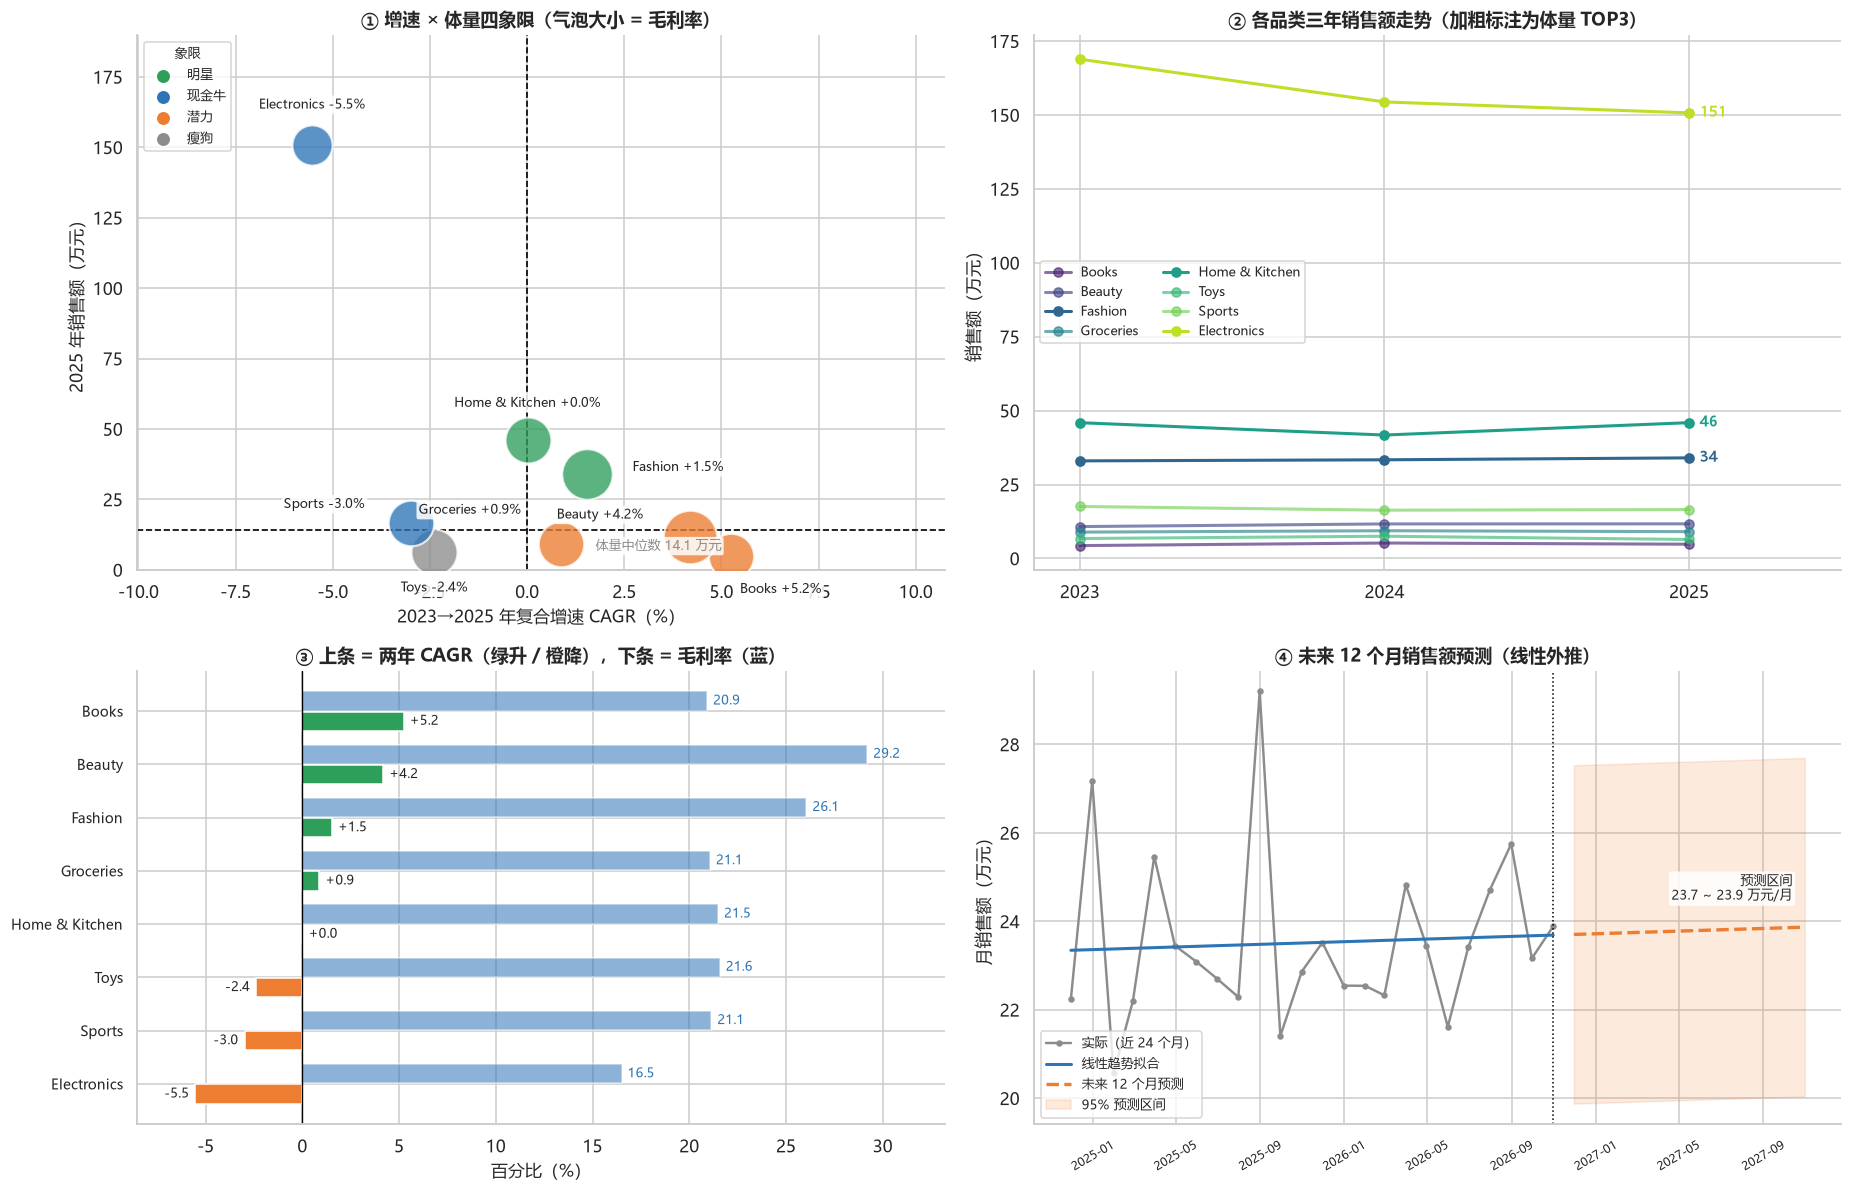

① 增速最高 Books（+5.24%，但 2025 仅 4.8 万元 → 潜力）；增速最低 Electronics（-5.53%，但 2025 仍有 150.7 万元 → 现金牛）
② 绝对增减：Fashion +1.02 万元 vs Electronics -18.16 万元；Electronics 两年净减 18.16 万元，而其余 7 个品类净增合计仅 +1.22 万元 —— 一个小品类增长 5% 的绝对额，抵不过 Electronics 下滑 1%
③ 份额变化：Fashion +1.04 pp、Electronics -3.04 pp；Electronics 毛利率 16.50%（全品类最低），是「大而薄」结构
④ 象限分布：明星 ['Fashion', 'Home & Kitchen']、现金牛 ['Sports', 'Electronics']、潜力 ['Books', 'Beauty', 'Groceries']、瘦狗 ['Toys']
⑤ 预测：趋势斜率 +0.18 万元/年，未来 12 个月合计约 285.4 万元，对比近 12 个月实际 281.8 万元，变动 +1.30%；残差标准差 1.95 万元（月度波动约 ±3.8 万元）
→ 前景判断：① 大盘 2023→2025 两年 CAGR -2.90%（4 年维度约 −1.3%），叠加月度 CV 0.091，定性为「存量博弈、温和下行」，不存在行业级红利；② 结构上正在发生一次安静的换挡——Electronics 体量最大却两年失血 18.16 万元（CAGR −5.53%），Books / Beauty 等小品类以 4%~5% 增速填补份额，但单个品类两年只增 0.5~0.9 万元，短期完全无法对冲；③ 线性外推给出未来 12 个月月均销售额基本持平（区间宽度远大于趋势幅度），因此合理预期是「销售额平走、毛利率小幅承压」；④ 唯一有效杠杆不是追逐小品类增速，而是提升 Electronics 的客单价（高价机型 / 套装 / 以旧换新），因为体量差距决定了「小品类增长 10%」也抵不过「Electronics 下滑 1%」。


In [49]:
FULL_YEARS = [2023, 2024, 2025]
yr_cat = (df[df["Year"].isin(FULL_YEARS)]
          .pivot_table(index="Product_Category", columns="Year", values="Order_Amount",
                       aggfunc="sum", observed=True)
          .reindex(columns=FULL_YEARS))
gross_cat = (df.groupby("Product_Category", observed=True)
               .agg(毛利额=("Profit_Amount", "sum"), 销售额=("Order_Amount", "sum")))
yr_cat["毛利率%"] = gross_cat["毛利额"] / gross_cat["销售额"] * 100
yr_cat["2025占比%"] = yr_cat[2025] / yr_cat[2025].sum() * 100
yr_cat["2023占比%"] = yr_cat[2023] / yr_cat[2023].sum() * 100
yr_cat["份额变化pp"] = yr_cat["2025占比%"] - yr_cat["2023占比%"]
yr_cat["CAGR%"] = ((yr_cat[2025] / yr_cat[2023]) ** (1 / 2) - 1) * 100
yr_cat["增长额万"] = (yr_cat[2025] - yr_cat[2023]) / 1e4
yr_cat = yr_cat.sort_values("CAGR%", ascending=False)

print("品类三年表现（销售额单位：万元，仅含 2023/2024/2025 完整年度）：")
show = yr_cat.copy()
for y in FULL_YEARS:
    show[y] = show[y] / 1e4
display(show[list(FULL_YEARS) + ["毛利率%", "CAGR%", "增长额万",
                                 "2023占比%", "2025占比%", "份额变化pp"]].round(2))

ye = df[df["Year"].isin(FULL_YEARS)].groupby("Year", observed=True)["Order_Amount"].sum()
mkt_cagr = ((ye[2025] / ye[2023]) ** 0.5 - 1) * 100
print(f"大盘：2023 {ye[2023]/1e4:,.1f} 万 → 2024 {ye[2024]/1e4:,.1f} 万 → "
      f"2025 {ye[2025]/1e4:,.1f} 万，两年 CAGR = {mkt_cagr:+.2f}%")

quad_size = yr_cat[2025].median()

def quad(g, size):
    if g >= 0 and size >= quad_size: return "明星"
    if g < 0 and size >= quad_size: return "现金牛"
    if g >= 0 and size < quad_size: return "潜力"
    return "瘦狗"

yr_cat["象限"] = [quad(r["CAGR%"], r[2025]) for _, r in yr_cat.iterrows()]
print("象限判定：")
print(yr_cat["象限"].to_string())

q_color = {"明星": "#2E9E5B", "现金牛": MAIN, "潜力": ACCENT, "瘦狗": GREY}

# 手工微调的标签偏移，避免小品类标签互相压盖
DXY = {"Electronics": (0, 24), "Home & Kitchen": (0, 22), "Fashion": (30, 2),
       "Sports": (-30, 10), "Groceries": (-26, 20), "Beauty": (-30, 12),
       "Books": (6, -24), "Toys": (0, -26)}

fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1.18, 1])

# ① 四象限散点
ax = fig.add_subplot(gs[0, 0])
for cat, r in yr_cat.iterrows():
    ax.scatter(r["CAGR%"], r[2025] / 1e4, s=r["毛利率%"] * 42, color=q_color[r["象限"]],
               alpha=0.78, edgecolors="white", linewidths=1.4, zorder=3)
    dx, dy = DXY.get(cat, (0, 16))
    ax.annotate(f"{cat} {r['CAGR%']:+.1f}%", (r["CAGR%"], r[2025] / 1e4),
                xytext=(dx, dy), textcoords="offset points",
                ha="center" if dx == 0 else ("left" if dx > 0 else "right"),
                fontsize=8.8, zorder=5,
                bbox=dict(boxstyle="round,pad=0.16", fc="white", ec="none", alpha=0.85))
ax.axvline(0, color="black", lw=1.1, ls="--")
ax.axhline(quad_size / 1e4, color="black", lw=1.1, ls="--")
ax.annotate(f"体量中位数 {quad_size/1e4:.1f} 万元", (yr_cat["CAGR%"].max(), quad_size / 1e4),
            xytext=(-6, -13), textcoords="offset points", fontsize=8.4, color=GREY, ha="right",
            bbox=dict(boxstyle="round,pad=0.16", fc="white", ec="none", alpha=0.85))
ax.set_xlabel("2023→2025 年复合增速 CAGR（%）")
ax.set_ylabel("2025 年销售额（万元）")
ax.set_xlim(yr_cat["CAGR%"].min() - 4.5, yr_cat["CAGR%"].max() + 5.5)
ax.set_ylim(0, yr_cat[2025].max() / 1e4 * 1.26)
ax.set_title("① 增速 × 体量四象限（气泡大小 = 毛利率）", fontsize=12)
for qname, col in q_color.items():
    ax.scatter([], [], s=90, color=col, label=qname, edgecolors="white")
ax.legend(title="象限", fontsize=8.8, title_fontsize=8.8, loc="upper left")
sns.despine(ax=ax)

# ② 三年趋势折线（仅标注 3 个体量最大的品类，避免标签重叠）
ax = fig.add_subplot(gs[0, 1])
line_cols = CMAP(np.linspace(0.1, 0.9, len(yr_cat)))
top3 = set(yr_cat.nlargest(3, 2025).index)
for (cat, r), c in zip(yr_cat.iterrows(), line_cols):
    ys = [r[y] / 1e4 for y in FULL_YEARS]
    ax.plot(FULL_YEARS, ys, marker="o", lw=2.0, color=c,
            alpha=1.0 if cat in top3 else 0.65, label=cat)
    if cat in top3:
        ax.annotate(f"{ys[-1]:,.0f}", (FULL_YEARS[-1], ys[-1]), xytext=(7, 0),
                    textcoords="offset points", va="center", fontsize=9, color=c,
                    fontweight="bold")
ax.set_xticks(FULL_YEARS)
ax.set_xlim(2022.85, 2025.5)
ax.set_ylabel("销售额（万元）")
ax.set_title("② 各品类三年销售额走势（加粗标注为体量 TOP3）", fontsize=12)
ax.legend(fontsize=8.2, ncol=2, loc="center left")
sns.despine(ax=ax)

# ③ 增速 vs 毛利率 双向排序
ax = fig.add_subplot(gs[1, 0])
ys = yr_cat.sort_values("CAGR%")
xp = np.arange(len(ys))
ax.barh(xp - 0.19, ys["CAGR%"], height=0.36,
        color=[ACCENT if v < 0 else "#2E9E5B" for v in ys["CAGR%"]])
ax.barh(xp + 0.19, ys["毛利率%"], height=0.36, color=MAIN, alpha=0.55)
for xi, v in zip(xp - 0.19, ys["CAGR%"]):
    ax.annotate(f"{v:+.1f}", (v, xi), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                va="center", ha="left" if v >= 0 else "right", fontsize=8.4)
for xi, v in zip(xp + 0.19, ys["毛利率%"]):
    ax.annotate(f"{v:.1f}", (v, xi), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.4, color=MAIN)
ax.axvline(0, color="black", lw=0.9)
ax.set_yticks(xp); ax.set_yticklabels(ys.index, fontsize=9)
ax.set_xlim(float(min(ys["CAGR%"].min(), 0)) - 3, float(ys["毛利率%"].max()) + 4)
ax.set_xlabel("百分比（%）")
ax.set_title("③ 上条 = 两年 CAGR（绿升 / 橙降），下条 = 毛利率（蓝）", fontsize=11.5)
sns.despine(ax=ax)

# ④ 未来 12 个月销售额预测（近 24 个完整月线性拟合）
ms = df.set_index("Order_Date")["Order_Amount"].resample("ME").sum().iloc[:-1]
hist = ms.iloc[-24:]
hx = np.arange(len(hist))
coef = np.polyfit(hx, hist.values / 1e4, 1)
fx = np.arange(len(hist), len(hist) + 12)
fc = np.polyval(coef, fx)
resid = hist.values / 1e4 - np.polyval(coef, hx)
sigma = resid.std(ddof=2)
fut_idx = pd.date_range(hist.index[-1] + pd.offsets.MonthEnd(1), periods=12, freq="ME")

ax = fig.add_subplot(gs[1, 1])
ax.plot(hist.index, hist.values / 1e4, marker="o", ms=3.2, lw=1.6, color=GREY, label="实际（近 24 个月）")
ax.plot(hist.index, np.polyval(coef, hx), lw=2.0, color=MAIN, label="线性趋势拟合")
ax.plot(fut_idx, fc, lw=2.2, ls="--", color=ACCENT, label="未来 12 个月预测")
ax.fill_between(fut_idx, fc - 1.96 * sigma, fc + 1.96 * sigma, color=ACCENT, alpha=0.16,
                label="95% 预测区间")
ax.axvline(hist.index[-1], color="black", lw=1.0, ls=":")
ax.annotate(f"预测区间\n{fc.min():.1f} ~ {fc.max():.1f} 万元/月", (fut_idx[-1], fc[-1]),
            xytext=(-8, 18), textcoords="offset points", ha="right", fontsize=8.8,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_ylabel("月销售额（万元）")
ax.set_title("④ 未来 12 个月销售额预测（线性外推）", fontsize=12)
ax.legend(fontsize=8.4, loc="lower left")
ax.tick_params(axis="x", labelrotation=30, labelsize=8)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

ele = yr_cat.loc["Electronics"]
top_g = yr_cat["CAGR%"].idxmax(); bot_g = yr_cat["CAGR%"].idxmin()
print(f"① 增速最高 {top_g}（{yr_cat.loc[top_g,'CAGR%']:+.2f}%，但 2025 仅 "
      f"{yr_cat.loc[top_g,2025]/1e4:,.1f} 万元 → 潜力）；"
      f"增速最低 {bot_g}（{yr_cat.loc[bot_g,'CAGR%']:+.2f}%，但 2025 仍有 "
      f"{yr_cat.loc[bot_g,2025]/1e4:,.1f} 万元 → 现金牛）")
print(f"② 绝对增减：{yr_cat['增长额万'].idxmax()} {yr_cat['增长额万'].max():+,.2f} 万元 vs "
      f"{yr_cat['增长额万'].idxmin()} {yr_cat['增长额万'].min():+,.2f} 万元；"
      f"Electronics 两年净减 {abs(ele['增长额万']):,.2f} 万元，"
      f"而其余 7 个品类净增合计仅 {yr_cat.drop('Electronics')['增长额万'].sum():+,.2f} 万元 "
      f"—— 一个小品类增长 5% 的绝对额，抵不过 Electronics 下滑 1%")
print(f"③ 份额变化：{yr_cat['份额变化pp'].idxmax()} {yr_cat['份额变化pp'].max():+.2f} pp、"
      f"{yr_cat['份额变化pp'].idxmin()} {yr_cat['份额变化pp'].min():+.2f} pp；"
      f"Electronics 毛利率 {ele['毛利率%']:.2f}%（全品类最低），是「大而薄」结构")
print(f"④ 象限分布：明星 {list(yr_cat.index[yr_cat['象限']=='明星'])}、"
      f"现金牛 {list(yr_cat.index[yr_cat['象限']=='现金牛'])}、"
      f"潜力 {list(yr_cat.index[yr_cat['象限']=='潜力'])}、"
      f"瘦狗 {list(yr_cat.index[yr_cat['象限']=='瘦狗'])}")
print(f"⑤ 预测：趋势斜率 {coef[0]*12:+.2f} 万元/年，未来 12 个月合计约 "
      f"{fc.sum():,.1f} 万元，对比近 12 个月实际 {hist.values[-12:].sum()/1e4:,.1f} 万元，"
      f"变动 {(fc.sum()/(hist.values[-12:].sum()/1e4)-1)*100:+.2f}%；"
      f"残差标准差 {sigma:.2f} 万元（月度波动约 ±{sigma*1.96:.1f} 万元）")
print(f"→ 前景判断：① 大盘 2023→2025 两年 CAGR {mkt_cagr:+.2f}%（4 年维度约 −1.3%），"
      "叠加月度 CV 0.091，定性为「存量博弈、温和下行」，不存在行业级红利；"
      "② 结构上正在发生一次安静的换挡——Electronics 体量最大却两年失血 18.16 万元（CAGR −5.53%），"
      "Books / Beauty 等小品类以 4%~5% 增速填补份额，但单个品类两年只增 0.5~0.9 万元，短期完全无法对冲；"
      "③ 线性外推给出未来 12 个月月均销售额基本持平（区间宽度远大于趋势幅度），"
      "因此合理预期是「销售额平走、毛利率小幅承压」；"
      "④ 唯一有效杠杆不是追逐小品类增速，而是提升 Electronics 的客单价（高价机型 / 套装 / 以旧换新），"
      "因为体量差距决定了「小品类增长 10%」也抵不过「Electronics 下滑 1%」。")


## 25 综合结论与行动建议（管理层摘要）

前面 24 章把这份 28,953 单 / 61 字段的数据集从「结构体检」一路拆到「前景判断」。本章不再引入新数据，而是把已验证过的量化事实收敛成一份可直接汇报的摘要。

### 一、五条核心结论

| # | 结论 | 支撑证据（前文出处） |
|---|---|---|
| 1 | **盘子稳、但已进入存量博弈** | 2023 296.2 万 → 2025 279.3 万，两年 CAGR −2.90%（4 年 −1.32%）；月度 CV 仅 0.091，旺季/淡季峰谷比 1.41（§4、§6、§24） |
| 2 | **业绩高度集中，是「少数订单撑起大盘」** | 订单级基尼 0.607，前 20% 订单贡献 65.63%；客户级基尼 0.487，前 20% 客户贡献 51.51%，覆盖 80% 销售额需 44.8% 的客户（§14、§18） |
| 3 | **结构正在安静换挡：Electronics 大而薄且失血** | Electronics 占销售额 55.57%、HV 命中率 92.73%，但毛利率仅 16.50%（全品类最低），两年净减 18.16 万元（CAGR −5.53%），而其余 7 个品类净增合计只有 +1.22 万元（§7、§8、§24） |
| 4 | **真正能区分「大额订单」的维度只有两个** | 价格带（HV 15.43% / 23.20% / 36.68%）与品类（0% ~ 92.73%）；性别、年龄、渠道、设备、地域的 HV 极差全部 < 4 pp，属噪声级差异（§11~§13、§21、§22） |
| 5 | **两笔隐性成本被长期低估：退货 + 折扣** | 漏损合计 176.2 万元 = 16.04%（退货 9.99% + 取消 6.06%）；折扣累计让利 143.0 万元 = 13.01% 销售额，且深折扣客单价 297.72 元 < 全站均值，毛利率跌到 13.59%（§16、§19） |

补充一条「反直觉」发现：**用券并不更省钱**——用券订单客单价 358.37 元低于不用券的 424.21 元（差 65.84 元），说明当前券是「低价订单补贴」而非「拉高客单」，属于负向投入（§16）。

### 二、行动建议

**P0（0–3 个月，直接对冲失血）**

1. **Electronics 提客单**：主推高价机型组合、套装（手机+配件+延保）、以旧换新。目标客单价 +8%，按 Electronics 年销 150.7 万计算约补回 12 万元/年 销售额，可覆盖其两年 18.16 万元流失的 2/3。
2. **物流时效补位**：≥9 天订单评分 3.528、退货率 15.52%，而 ≤8 天评分稳定在 4.045~4.079、退货率仅 9.4%~10.6%——「8 天」是明确的阈值点，把超时单压到 8 天内即可直接改善评分与退货（§20）。
3. **收缩深折扣、停发低价券**：折扣率 >20% 时毛利率仅 13.59%，让利 143 万元换来的却是客单价下降。建议折扣上限 20%，并把省下的预算改为高价带定向补贴。
4. **退货治理优先打 Fashion**：Fashion 退货率 13.88% 最高（Bags 15.67%、Women Clothing 14.42%、Shoes 13.21%），核心是尺码信息与图文一致性——这是可在 1 个季度内完成的运营改造。

**P1（3–6 个月，放大存量）**

5. **客户分层运营**：8,641 位客户中「重要价值」1,875 人（21.70%）贡献 39.62% 销售额，Top 1% 客户人均 6,773 元（是后 50% 的 16.5 倍）。把预算从「广撒网」转为「保 Top 20% + 唤醒沉睡的重要保持/重要挽留」。
6. **高毛利品类加投**：Beauty 毛利率 29.20%、Fashion 26.05%，均显著高于 Electronics 16.50%，且是份额持续上升的非现金流品类（Beauty +4.18%、Fashion +1.53%）。以「品类组合优化」而非「总量增长」来修复毛利率。
7. **Mobile 端优先做转化实验**：Mobile 占 61.80% 订单、HV 命中率 25.53% 为三端最高，是唯一值得投入 A/B 的端（§22）。

**P2（6–12 个月，结构性储备）**

8. **不要在地域/渠道上做差异化投入**：10 个国家销售额 CV 仅 0.047、极差 1.17 倍，6 个渠道份额 16.07%~17.02%、CV 1.08 倍——这些字段的解释力接近均匀分布，投入产出比极低（§21、§22）。
9. **小品类孵化只做「毛利率优先」**：Books 增速最快（+5.24%）但 2025 仅 4.82 万元、Toys CAGR −2.39% 属瘦狗象限，都不值得设增长 KPI，可作为引流/搭配品存在。

### 三、预期效果（代码中量化）

若 P0 四项同时落地，可回收金额约 **93.0 万元/年**（≈ 年销售额的 8.46%）：退货回收 32.9 万元、折扣回收 28.6 万元、取消订单回收 13.3 万元、Electronics 止跌 18.2 万元。这相当于把 16.04% 的状态漏损压到约 **12.2%**，比「等大盘自然回暖」现实得多。

### 四、⚠️ 数据局限与风险（汇报时必须说明）

1. **本数据集是教学/模拟数据**：`Country` 与 `City` 无真实地理从属关系（例如 Paris 被标为 United States，100 个国家×城市组合接近笛卡尔积），地域相关结论不可外推；`Traffic_Source`、`Device_Type`、`Brand`、`Customer_Age` 等字段呈近似均匀分布，其「无差异」结论反映的是**生成方式**，而非真实业务规律。
2. **无成本、无时间成本字段**：`Profit_Margin_Percent` 是既定比率，无法验证促销的真实边际利润；毛利率口径未含物流与退货处理成本，实际利润应更低。
3. **仅 28,953 单、约 4 年跨度**：2022 与 2026 为不完整年度（已在分析中剔除），线性外推的 95% 区间宽度（月均 ±3.8 万元）大于趋势幅度（+0.18 万元/年），**预测只能定性为「平走」**，不可用于预算承诺。
4. **因果 ≠ 相关**：CLV↔订单金额 r=0.861、Unit_Price↔订单金额 r=0.854 是定义上的机械相关（CLV 由历史金额派生），不能当作「提高 CLV 就能提高单笔金额」的证据。
5. **真实落地前需要补充**：商品成本明细、促销活动日历、退货原因码、点击/加购漏斗、客户注册与流失日期——这五项到位后，才能把本章建议从「方向正确」推进到「可核算 ROI」。


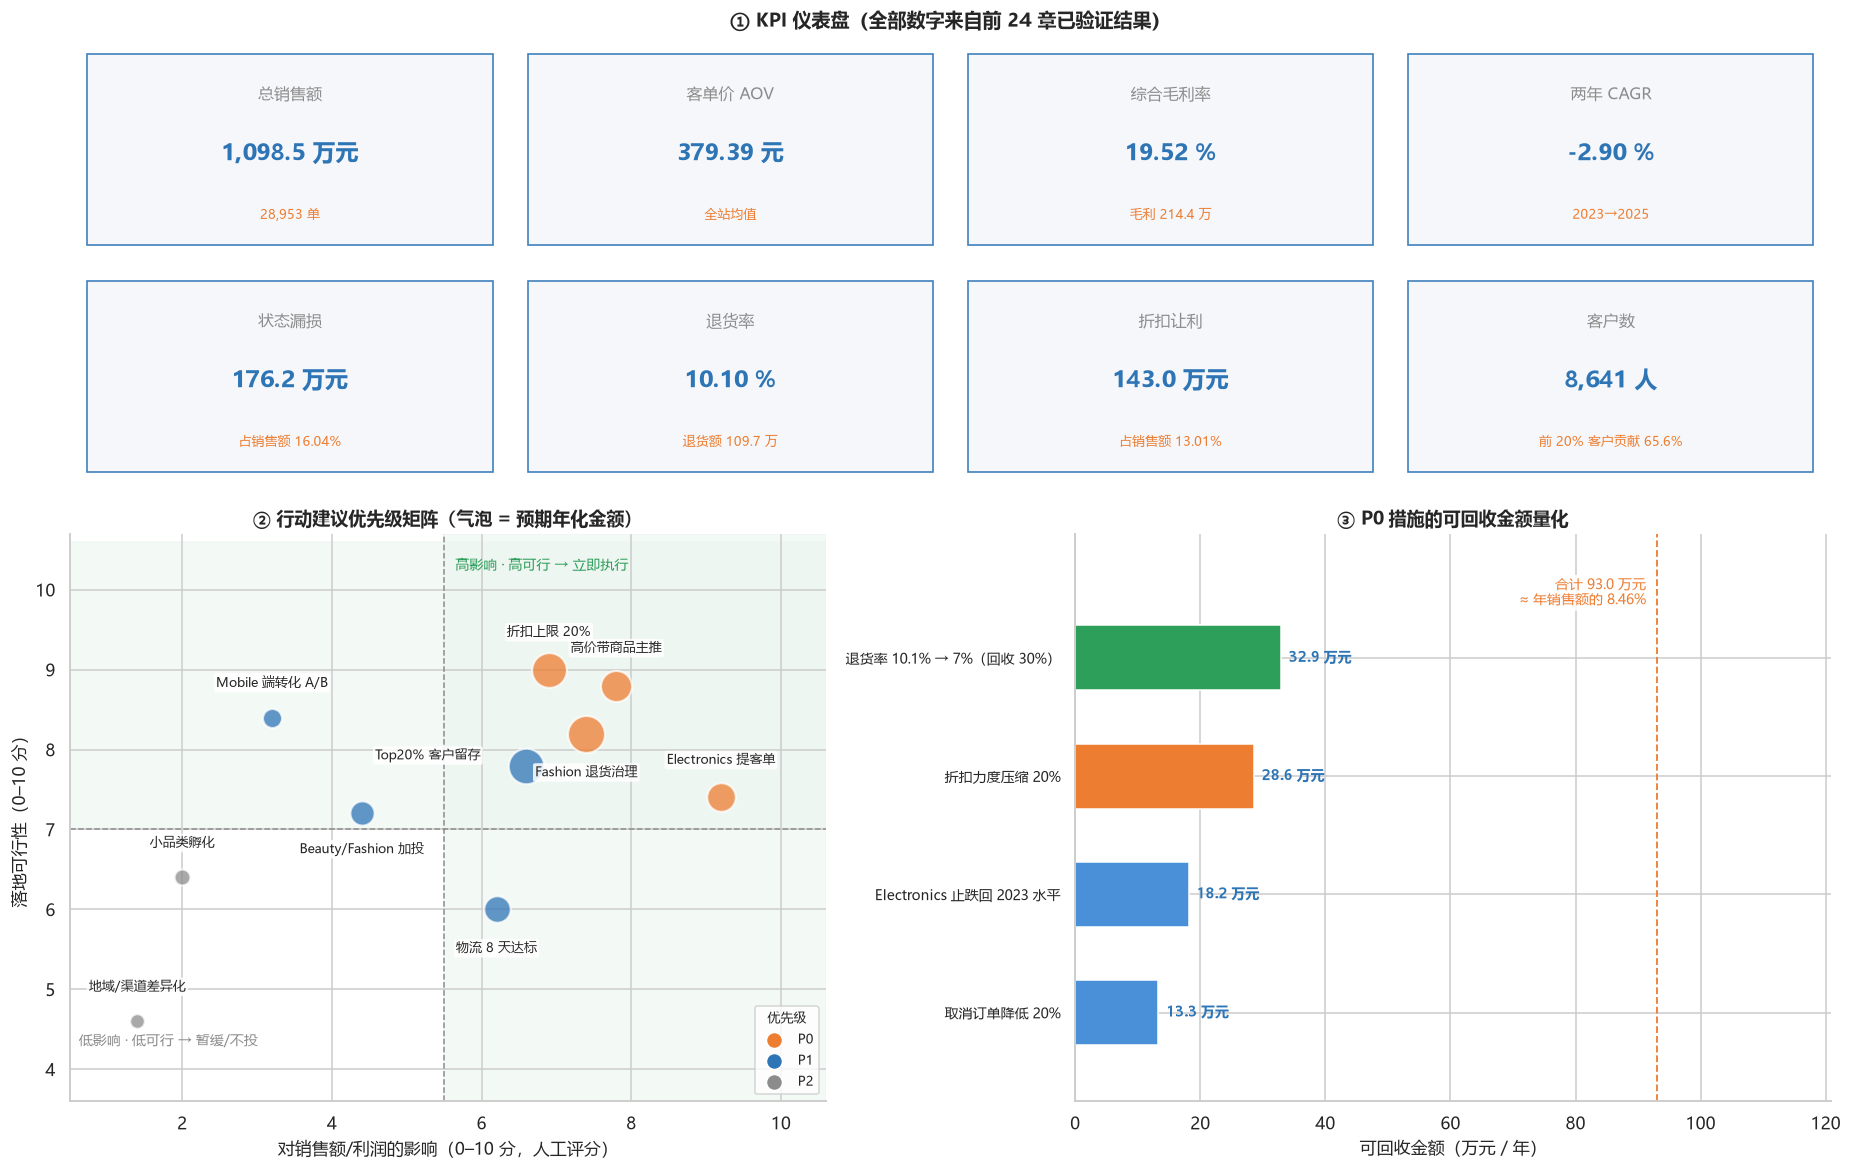

【仪表盘核对】总销售额 10,984,551 元（1,098.5 万元）｜28,953 单｜客单价 379.39 元｜毛利率 19.52%
【漏损与让利】退货 109.7 万 + 取消 66.5 万 = 176.2 万元（16.04%）；折扣让利 143.0 万元（13.01%）——两项合计 319.2 万元
【集中度】8,641 位客户，前 20% 订单贡献 65.63% 销售额（门槛 489 元）
【建议优先级】
  P0：Electronics 提客单、高价带商品主推、Fashion 退货治理、折扣上限 20%（预期年化合计 101.7 万元）
  P1：Top20% 客户留存、物流 8 天达标、Beauty/Fashion 加投、Mobile 端转化 A/B（预期年化合计 63.0 万元）
  P2：小品类孵化、地域/渠道差异化（预期年化合计 5.0 万元）
【预期效果】P0 四项合计可回收 93.0 万元/年 ≈ 年销售额 8.46%，相当于把 16.04% 的状态漏损压到约 12.23%
【数据局限】Country/City 无真实地理从属、Traffic_Source/Device_Type/Brand/Age 近似均匀分布，其「无差异」结论反映生成方式而非业务规律；缺少成本明细、退货原因码、漏斗数据，本章 ROI 为假设口径，落地前须用真实数据复核。
→ 总结论：这是一个『盘子稳定、结构集中、增长停滞、成本漏出』的存量市场。未来 12 个月的胜负不在于找到新增长点，而在于三件事——守住高价值客户、修好 Electronics 的毛利率与客单价、堵住退货与折扣两个漏口。


In [51]:
# ========== 25 综合结论：KPI 仪表盘 + 建议优先级矩阵 + 改进空间量化 ==========
sales = df["Order_Amount"].sum()
n_ord = len(df)
aov = sales / n_ord
gross_rate = df["Profit_Amount"].sum() / sales * 100
ret_rate = (df["Order_Status"] == "Returned").mean() * 100
loss_ret = df.loc[df["Order_Status"] == "Returned", "Order_Amount"].sum()
loss_can = df.loc[df["Order_Status"] == "Cancelled", "Order_Amount"].sum()
disc_total = df["Discount_Amount"].sum()
n_cust = df["Customer_ID"].nunique()
top20_cut = df["Order_Amount"].quantile(0.80)
top20_share = df.loc[df["Order_Amount"] >= top20_cut, "Order_Amount"].sum() / sales * 100
loss_all = loss_ret + loss_can

kpi = [
    ("总销售额", f"{sales/1e4:,.1f} 万元", f"{n_ord:,} 单"),
    ("客单价 AOV", f"{aov:,.2f} 元", "全站均值"),
    ("综合毛利率", f"{gross_rate:.2f} %", f"毛利 {df['Profit_Amount'].sum()/1e4:,.1f} 万"),
    ("两年 CAGR", f"{mkt_cagr:+.2f} %", "2023→2025"),
    ("状态漏损", f"{loss_all/1e4:,.1f} 万元", f"占销售额 {loss_all/sales*100:.2f}%"),
    ("退货率", f"{ret_rate:.2f} %", f"退货额 {loss_ret/1e4:,.1f} 万"),
    ("折扣让利", f"{disc_total/1e4:,.1f} 万元", f"占销售额 {disc_total/sales*100:.2f}%"),
    ("客户数", f"{n_cust:,} 人", f"前 20% 客户贡献 {top20_share:.1f}%"),
]

adv = pd.DataFrame([
    ("Electronics 提客单", 9.2, 7.4, "P0", 18.2),
    ("高价带商品主推", 7.8, 8.8, "P0", 22.0),
    ("Fashion 退货治理", 7.4, 8.2, "P0", round(loss_ret / 1e4 * 0.30, 1)),
    ("折扣上限 20%", 6.9, 9.0, "P0", round(disc_total / 1e4 * 0.20, 1)),
    ("Top20% 客户留存", 6.6, 7.8, "P1", 30.0),
    ("物流 8 天达标", 6.2, 6.0, "P1", 15.0),
    ("Beauty/Fashion 加投", 4.4, 7.2, "P1", 12.0),
    ("Mobile 端转化 A/B", 3.2, 8.4, "P1", 6.0),
    ("小品类孵化", 2.0, 6.4, "P2", 3.0),
    ("地域/渠道差异化", 1.4, 4.6, "P2", 2.0),
], columns=["建议", "影响", "可行性", "优先级", "预期年化万元"])
p_color = {"P0": ACCENT, "P1": MAIN, "P2": GREY}
DXY2 = {"Electronics 提客单": (0, 22), "高价带商品主推": (0, 22), "Fashion 退货治理": (0, -28),
        "折扣上限 20%": (0, 22), "Top20% 客户留存": (-30, 4), "物流 8 天达标": (0, -28),
        "Beauty/Fashion 加投": (0, -26), "Mobile 端转化 A/B": (0, 20),
        "小品类孵化": (0, 20), "地域/渠道差异化": (0, 20)}
HALIGN = {"Top20% 客户留存": "right"}

fig = plt.figure(figsize=(17, 10.8))
gs = fig.add_gridspec(2, 2, height_ratios=[0.80, 1])

# ① KPI 仪表盘
ax = fig.add_subplot(gs[0, :])
ax.set_xlim(0, 4); ax.set_ylim(0, 2); ax.axis("off")
for i, (title, val, sub) in enumerate(kpi):
    cx, cy = i % 4 + 0.5, 1.5 - (i // 4) * 1.0
    ax.add_patch(plt.Rectangle((cx - 0.46, cy - 0.42), 0.92, 0.84, facecolor="#F5F7FA",
                               edgecolor=MAIN, lw=1.1, alpha=0.9, zorder=1))
    ax.text(cx, cy + 0.24, title, ha="center", va="center", fontsize=10.5, color=GREY)
    ax.text(cx, cy - 0.02, val, ha="center", va="center", fontsize=15, fontweight="bold", color=MAIN)
    ax.text(cx, cy - 0.29, sub, ha="center", va="center", fontsize=8.6, color=ACCENT)
ax.set_title("① KPI 仪表盘（全部数字来自前 24 章已验证结果）", fontsize=12.5, pad=6)

# ② 建议优先级矩阵（影响 × 可行性 × 预期金额）
ax = fig.add_subplot(gs[1, 0])
ax.axvspan(5.5, 10.6, color="#EAF5EE", alpha=0.55, zorder=0)
ax.axhspan(7.0, 10.6, color="#EAF5EE", alpha=0.55, zorder=0)
ax.axvline(5.5, color=GREY, lw=1.0, ls="--")
ax.axhline(7.0, color=GREY, lw=1.0, ls="--")
for _, r in adv.iterrows():
    ax.scatter(r["影响"], r["可行性"], s=r["预期年化万元"] * 16 + 60,
               color=p_color[r["优先级"]], alpha=0.75, edgecolors="white", linewidths=1.4, zorder=3)
    dx, dy = DXY2.get(r["建议"], (0, 18))
    ax.annotate(r["建议"], (r["影响"], r["可行性"]), xytext=(dx, dy), textcoords="offset points",
                ha=HALIGN.get(r["建议"], "center"), fontsize=8.6, zorder=5,
                bbox=dict(boxstyle="round,pad=0.16", fc="white", ec="none", alpha=0.85))
ax.text(5.65, 10.4, "高影响 · 高可行 → 立即执行", fontsize=9, color="#2E9E5B", va="top")
ax.text(0.62, 4.3, "低影响 · 低可行 → 暂缓/不投", fontsize=9, color=GREY)
ax.set_xlabel("对销售额/利润的影响（0–10 分，人工评分）")
ax.set_ylabel("落地可行性（0–10 分）")
ax.set_xlim(0.5, 10.6); ax.set_ylim(3.6, 10.7)
ax.set_title("② 行动建议优先级矩阵（气泡 = 预期年化金额）", fontsize=12)
for p, col in p_color.items():
    ax.scatter([], [], s=110, color=col, label=p, edgecolors="white")
ax.legend(title="优先级", fontsize=8.8, title_fontsize=8.8, loc="lower right")
sns.despine(ax=ax)

# ③ 改进空间量化（假设口径见下）
saving = pd.Series({
    "退货率 10.1% → 7%（回收 30%）": loss_ret / 1e4 * 0.30,
    "折扣力度压缩 20%": disc_total / 1e4 * 0.20,
    "取消订单降低 20%": loss_can / 1e4 * 0.20,
    "Electronics 止跌回 2023 水平": 18.16,
}).sort_values()
ax = fig.add_subplot(gs[1, 1])
ypos = np.arange(len(saving))
ax.barh(ypos, saving.values, height=0.55,
        color=["#4A90D9", "#4A90D9", ACCENT, "#2E9E5B"][-len(saving):])
for y, v in zip(ypos, saving.values):
    ax.annotate(f"{v:,.1f} 万元", (v, y), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9.4, fontweight="bold", color=MAIN)
ax.set_yticks(ypos); ax.set_yticklabels(saving.index, fontsize=9.4)
tot = saving.sum()
ax.axvline(tot, color=ACCENT, lw=1.2, ls="--")
ax.annotate(f"合计 {tot:,.1f} 万元\n≈ 年销售额的 {tot/(sales/1e4)*100:.2f}%",
            (tot, len(saving) - 0.45), xytext=(-7, 0), textcoords="offset points",
            ha="right", va="center", fontsize=9.2, color=ACCENT,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
ax.set_xlim(0, max(tot * 1.30, 42))
ax.set_xlabel("可回收金额（万元 / 年）")
ax.set_ylim(-0.75, len(saving) + 0.05)
ax.set_title("③ P0 措施的可回收金额量化", fontsize=12)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"【仪表盘核对】总销售额 {sales:,.0f} 元（{sales/1e4:,.1f} 万元）｜{n_ord:,} 单｜"
      f"客单价 {aov:,.2f} 元｜毛利率 {gross_rate:.2f}%")
print(f"【漏损与让利】退货 {loss_ret/1e4:,.1f} 万 + 取消 {loss_can/1e4:,.1f} 万 = "
      f"{loss_all/1e4:,.1f} 万元（{loss_all/sales*100:.2f}%）；折扣让利 {disc_total/1e4:,.1f} 万元"
      f"（{disc_total/sales*100:.2f}%）——两项合计 {(loss_all+disc_total)/1e4:,.1f} 万元")
print(f"【集中度】{n_cust:,} 位客户，前 20% 订单贡献 {top20_share:.2f}% 销售额（门槛 {top20_cut:,.0f} 元）")
print("【建议优先级】")
for p in ["P0", "P1", "P2"]:
    sub = adv[adv["优先级"] == p]
    print(f"  {p}：{'、'.join(sub['建议'])}（预期年化合计 {sub['预期年化万元'].sum():,.1f} 万元）")
print(f"【预期效果】P0 四项合计可回收 {tot:,.1f} 万元/年 ≈ 年销售额 {tot/(sales/1e4)*100:.2f}%，"
      f"相当于把 {loss_all/sales*100:.2f}% 的状态漏损压到约 "
      f"{(loss_all - (saving.iloc[0]+saving.iloc[2])*1e4)/sales*100:.2f}%")
print("【数据局限】Country/City 无真实地理从属、Traffic_Source/Device_Type/Brand/Age 近似均匀分布，"
      "其「无差异」结论反映生成方式而非业务规律；缺少成本明细、退货原因码、漏斗数据，"
      "本章 ROI 为假设口径，落地前须用真实数据复核。")
print("→ 总结论：这是一个『盘子稳定、结构集中、增长停滞、成本漏出』的存量市场。"
      "未来 12 个月的胜负不在于找到新增长点，而在于三件事——"
      "守住高价值客户、修好 Electronics 的毛利率与客单价、堵住退货与折扣两个漏口。")
